In [1]:
import pandas as pd
import numpy as np
import re
import warnings


warnings.filterwarnings("ignore")

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, mutual_info_classif

from scipy.sparse import hstack, csr_matrix

In [2]:
# ==========================
# Cell 1 : Import Libraries
# ==========================

# Data Handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    cross_val_score
)

from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Models
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.neural_network import MLPClassifier

# XGBoost
from xgboost import XGBClassifier

# Utilities
import time
import warnings

warnings.filterwarnings("ignore")

# Display Options
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# Reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
import pandas as pd

# Load Kaggle dataset
kaggle = pd.read_csv(
    "Kaggle_urlset.csv.xls",
    encoding="latin1",
    engine="python",
    on_bad_lines="skip"
)

# Load PhishTank dataset
phishtank = pd.read_csv(
    "Phishtank_verified_online.csv.xls",
    encoding="latin1",
    engine="python",
    on_bad_lines="skip"
)

# Load Alexa dataset
alexa = pd.read_csv(
    "Alexa_top-1m.csv.xls",
    encoding="latin1",
    engine="python",
    on_bad_lines="skip"
)

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [4]:
print("Kaggle :", kaggle.shape)
print("PhishTank :",phishtank.shape)
print("Alexa :", alexa.shape)

Kaggle : (95991, 14)
PhishTank : (56406, 8)
Alexa : (999999, 2)


In [5]:
# Reload Alexa correctly

alexa = pd.read_csv(
    "Alexa_top-1m.csv.xls",
    encoding="latin1",
    engine="python",
    header=None
)

alexa.columns = ["rank", "domain"]

print(alexa.head())
print(alexa.shape)

   rank              domain
0     1          google.com
1     2      googleapis.com
2     3       microsoft.com
3     4      www.google.com
4     5  data.microsoft.com
(1000000, 2)


In [6]:
#Prepare PhishTank / PhishStorm Dataset (Phishing URLs)
phishtank = phishtank[["url"]]

phishtank["label"] = 1

In [7]:
#Prepare Kaggle Dataset
kaggle = kaggle[["domain","label"]]

In [8]:
combined = pd.concat([kaggle, alexa, phishtank], ignore_index=True)

print("Total samples:", len(combined))

Total samples: 1152397


In [9]:
combined.head()

,domain,label,rank,url
0,nobell.it/70ffb52d079109dca5664cce6f317373782/...,1.0,NaN,NaN
1,www.dghjdgf.com/paypal.co.uk/cycgi-bin/webscrc...,1.0,NaN,NaN
2,serviciosbys.com/paypal.cgi.bin.get-into.herf....,1.0,NaN,NaN
3,mail.printakid.com/www.online.americanexpress....,1.0,NaN,NaN
4,thewhiskeydregs.com/wp-content/themes/widescre...,1.0,NaN,NaN


In [10]:
print(combined.head())
print(combined.shape)
print(combined['label'].value_counts())

                                              domain  label  rank  url
0  nobell.it/70ffb52d079109dca5664cce6f317373782/...    1.0   NaN  NaN
1  www.dghjdgf.com/paypal.co.uk/cycgi-bin/webscrc...    1.0   NaN  NaN
2  serviciosbys.com/paypal.cgi.bin.get-into.herf....    1.0   NaN  NaN
3  mail.printakid.com/www.online.americanexpress....    1.0   NaN  NaN
4  thewhiskeydregs.com/wp-content/themes/widescre...    1.0   NaN  NaN
(1152397, 4)
label
1.0    104309
0.0     48009
Name: count, dtype: int64


In [11]:
print(combined.tail())
print(combined.shape)
print(combined['label'].value_counts())

        domain  label  rank                                                url
1152392    NaN    1.0   NaN              http://webmailadmin0.myfreesites.net/
1152393    NaN    1.0   NaN  http://www.formbuddy.com/cgi-bin/formdisp.pl?u...
1152394    NaN    1.0   NaN  http://www.formbuddy.com/cgi-bin/formdisp.pl?u...
1152395    NaN    1.0   NaN       http://www.habbocreditosparati.blogspot.com/
1152396    NaN    1.0   NaN  http://creditiperhabbogratissicuro100.blogspot...
(1152397, 4)
label
1.0    104309
0.0     48009
Name: count, dtype: int64


In [12]:
combined.info()

<class 'pandas.DataFrame'>
RangeIndex: 1152397 entries, 0 to 1152396
Data columns (total 4 columns):
 #   Column  Non-Null Count    Dtype  
---  ------  --------------    -----  
 0   domain  1095991 non-null  str    
 1   label   152318 non-null   float64
 2   rank    1000000 non-null  float64
 3   url     56406 non-null    str    
dtypes: float64(2), str(2)
memory usage: 35.2 MB


In [13]:
# Convert all domains into url column

combined["url"] = combined["url"].fillna(combined["domain"])

# Remove domain column
combined.drop(columns=["domain"], inplace=True)

In [14]:
combined = combined.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

In [15]:
#Reset Index
combined.reset_index(
    drop=True,
    inplace=True
)

In [16]:
# Random Undersampling

legitimate = combined[combined["label"] == 0]
phishing = combined[combined["label"] == 1]

# Sample phishing to match legitimate
phishing_sample = phishing.sample(
    n=len(legitimate),
    random_state=42
)

balanced = pd.concat([
    legitimate,
    phishing_sample
])

balanced = balanced.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

In [17]:
print(balanced["label"].value_counts())

label
0.0    48009
1.0    48009
Name: count, dtype: int64


In [18]:
df = balanced.copy()

In [19]:
#Lowercase URLs
df['url'] = df['url'].str.lower()

In [20]:
print(df["url"].dtype)
print(df["url"].isna().sum())
print(df["url"].head())

str
0
0                                      www.3m.com/dds/
1    www.information-management.com/issues/20050701...
2    paypal.com-us.cgi-bin-webscr-cmd.login-submit-...
3                     www.nch.com.au/scribe/index.html
4                en.wikipedia.org/wiki/mozilla_firefox
Name: url, dtype: str


In [21]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 96018 entries, 0 to 96017
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   label   96018 non-null  float64
 1   rank    0 non-null      float64
 2   url     96018 non-null  str    
dtypes: float64(2), str(1)
memory usage: 2.2 MB
None


In [22]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 96018 entries, 0 to 96017
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   label   96018 non-null  float64
 1   rank    0 non-null      float64
 2   url     96018 non-null  str    
dtypes: float64(2), str(1)
memory usage: 2.2 MB
None


In [23]:
print(balanced.head())

   label  rank                                                url
0    0.0   NaN                                    www.3m.com/dds/
1    0.0   NaN  www.information-management.com/issues/20050701...
2    1.0   NaN  paypal.com-us.cgi-bin-webscr-cmd.login-submit-...
3    0.0   NaN                   www.nch.com.au/scribe/index.html
4    0.0   NaN              en.wikipedia.org/wiki/Mozilla_Firefox


In [24]:
print(balanced.columns)

Index(['label', 'rank', 'url'], dtype='str')


In [25]:
print(df.columns)

Index(['label', 'rank', 'url'], dtype='str')


In [26]:
print(df["url"].isna().sum())


0


In [27]:
# Remove empty rank column
df.drop(columns=["rank"], inplace=True)

print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 96018 entries, 0 to 96017
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   label   96018 non-null  float64
 1   url     96018 non-null  str    
dtypes: float64(1), str(1)
memory usage: 1.5 MB
None


In [28]:
# Lowercase URLs
df["url"] = df["url"].str.lower()

In [29]:
#Clean URLs
def clean_url(url):
    url = re.sub(r'https?://', '', url)
    url = re.sub(r'www\.', '', url)
    return url

df['clean_url'] = df['url'].apply(clean_url)

In [30]:
#Verify Clean URLs
df[['url', 'clean_url']].head()

,url,clean_url
0,www.3m.com/dds/,3m.com/dds/
1,www.information-management.com/issues/20050701...,information-management.com/issues/20050701/103...
2,paypal.com-us.cgi-bin-webscr-cmd.login-submit-...,paypal.com-us.cgi-bin-webscr-cmd.login-submit-...
3,www.nch.com.au/scribe/index.html,nch.com.au/scribe/index.html
4,en.wikipedia.org/wiki/mozilla_firefox,en.wikipedia.org/wiki/mozilla_firefox


In [31]:
#Feature Engineering
# URL Length
df['url_length'] = df['clean_url'].apply(len)

# Number of dots
df['num_dots'] = df['clean_url'].str.count(r'\.')

# Number of digits
df['num_digits'] = df['clean_url'].str.count(r'\d')

# Presence of @
df['has_at_symbol'] = df['clean_url'].str.contains('@').astype(int)

# Number of hyphens
df['num_hyphens'] = df['clean_url'].str.count(r'-')

# Number of slashes
df['num_slashes'] = df['clean_url'].str.count(r'/')

# Number of question marks
df['num_question_marks'] = df['clean_url'].str.count(r'\?')

# Number of equal signs
df['num_equal'] = df['clean_url'].str.count(r'=')

# Number of underscores
df['num_underscores'] = df['clean_url'].str.count(r'_')

# Number of ampersands
df['num_ampersands'] = df['clean_url'].str.count(r'&')

In [32]:
df.head()

,label,url,clean_url,url_length,num_dots,num_digits,has_at_symbol,num_hyphens,num_slashes,num_question_marks,num_equal,num_underscores,num_ampersands
0,0.0,www.3m.com/dds/,3m.com/dds/,11,1,1,0,0,2,0,0,0,0
1,0.0,www.information-management.com/issues/20050701...,information-management.com/issues/20050701/103...,57,2,16,0,2,3,0,0,0,0
2,1.0,paypal.com-us.cgi-bin-webscr-cmd.login-submit-...,paypal.com-us.cgi-bin-webscr-cmd.login-submit-...,152,8,63,0,6,1,0,0,0,0
3,0.0,www.nch.com.au/scribe/index.html,nch.com.au/scribe/index.html,28,3,0,0,0,2,0,0,0,0
4,0.0,en.wikipedia.org/wiki/mozilla_firefox,en.wikipedia.org/wiki/mozilla_firefox,37,2,0,0,0,2,0,0,1,0


In [33]:
X_numeric = df[
    [
        "url_length",
        "num_dots",
        "num_digits",
        "has_at_symbol",
        "num_hyphens",
        "num_slashes",
        "num_question_marks",
        "num_equal",
        "num_underscores",
        "num_ampersands"
    ]
]

In [34]:
# ===============================
# Define Features and Labels
# ===============================

X_numeric = df[
    [
        "url_length",
        "num_dots",
        "num_digits",
        "has_at_symbol",
        "num_hyphens",
        "num_slashes",
        "num_question_marks",
        "num_equal",
        "num_underscores",
        "num_ampersands"
    ]
]

X_text = df["clean_url"]

y = df["label"]

In [35]:
from sklearn.model_selection import train_test_split

X_train_text, X_test_text, X_train_num, X_test_num, y_train, y_test = train_test_split(
    X_text,
    X_numeric,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

In [36]:
# Feature Engineering

# URL Length
df['url_length'] = df['clean_url'].apply(len)

# Number of dots
df['num_dots'] = df['clean_url'].str.count(r'\.')

# Number of digits
df['num_digits'] = df['clean_url'].str.count(r'\d')

# Presence of @
df['has_at_symbol'] = df['clean_url'].str.contains('@').astype(int)

# Number of hyphens
df['num_hyphens'] = df['clean_url'].str.count(r'-')

# Number of slashes
df['num_slashes'] = df['clean_url'].str.count(r'/')

# Number of question marks
df['num_question_marks'] = df['clean_url'].str.count(r'\?')

# Number of equal signs
df['num_equal'] = df['clean_url'].str.count(r'=')

# Number of underscores
df['num_underscores'] = df['clean_url'].str.count(r'_')

# Number of ampersands
df['num_ampersands'] = df['clean_url'].str.count(r'&')

In [37]:
X_numeric = df[
    [
        "url_length",
        "num_dots",
        "num_digits",
        "has_at_symbol",
        "num_hyphens",
        "num_slashes",
        "num_question_marks",
        "num_equal",
        "num_underscores",
        "num_ampersands"
    ]
]

X_text = df["clean_url"]

y = df["label"]

In [38]:
from sklearn.model_selection import train_test_split

X_train_text, X_test_text, X_train_num, X_test_num, y_train, y_test = train_test_split(
    X_text,
    X_numeric,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

In [39]:
print("Training Samples :", len(X_train_text))
print("Testing Samples :", len(X_test_text))

print("\nTraining Labels")
print(y_train.value_counts())

print("\nTesting Labels")
print(y_test.value_counts())

Training Samples : 67212
Testing Samples : 28806

Training Labels
label
0.0    33606
1.0    33606
Name: count, dtype: int64

Testing Labels
label
0.0    14403
1.0    14403
Name: count, dtype: int64


In [40]:
print("Training Samples :", len(X_train_text))
print("Testing Samples :", len(X_test_text))

print("\nTraining Labels")
print(y_train.value_counts())

print("\nTesting Labels")
print(y_test.value_counts())

Training Samples : 67212
Testing Samples : 28806

Training Labels
label
0.0    33606
1.0    33606
Name: count, dtype: int64

Testing Labels
label
0.0    14403
1.0    14403
Name: count, dtype: int64


In [41]:
# Use only handcrafted features
X_train = X_train_num.copy()
X_test = X_test_num.copy()

print(X_train.shape)
print(X_test.shape)

(67212, 10)
(28806, 10)


In [42]:
print(X_numeric.columns)

Index(['url_length', 'num_dots', 'num_digits', 'has_at_symbol', 'num_hyphens',
       'num_slashes', 'num_question_marks', 'num_equal', 'num_underscores',
       'num_ampersands'],
      dtype='str')


In [43]:

print(df.columns.tolist())

['label', 'url', 'clean_url', 'url_length', 'num_dots', 'num_digits', 'has_at_symbol', 'num_hyphens', 'num_slashes', 'num_question_marks', 'num_equal', 'num_underscores', 'num_ampersands']


In [44]:
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import mutual_info_classif

mi_selector = SelectKBest(
    score_func=mutual_info_classif,
    k="all"      # keep all handcrafted features
)

X_train = mi_selector.fit_transform(X_train, y_train)
X_test = mi_selector.transform(X_test)

In [45]:
print("Training Shape :", X_train.shape)
print("Testing Shape  :", X_test.shape)

print("\nTraining Labels")
print(y_train.value_counts())

print("\nTesting Labels")
print(y_test.value_counts())

Training Shape : (67212, 10)
Testing Shape  : (28806, 10)

Training Labels
label
0.0    33606
1.0    33606
Name: count, dtype: int64

Testing Labels
label
0.0    14403
1.0    14403
Name: count, dtype: int64


In [46]:
handcrafted_features = [
    "url_length",
    "num_dots",
    "num_digits",
    "has_at_symbol",
    "num_hyphens",
    "num_slashes",
    "num_question_marks",
    "num_equal",
    "num_underscores",
    "num_ampersands"
]

mi_scores = mi_selector.scores_

mi_df = pd.DataFrame({
    "Feature": handcrafted_features,
    "MI Score": mi_scores
}).sort_values(
    by="MI Score",
    ascending=False
).reset_index(drop=True)

display(mi_df)

,Feature,MI Score
0,url_length,0.177682
1,num_digits,0.103235
2,num_slashes,0.100235
3,num_equal,0.061133
4,num_hyphens,0.052312
5,num_question_marks,0.051794
6,num_ampersands,0.051183
7,num_dots,0.040974
8,num_underscores,0.005185
9,has_at_symbol,0.002952


In [47]:
mi_df.to_csv(
    "Mutual_Information_Scores.csv",
    index=False
)

In [48]:
selected_mask = mi_selector.get_support()

selected_features = pd.DataFrame({
    "Feature": np.array(handcrafted_features)[selected_mask],
    "MI Score": mi_scores[selected_mask]
}).sort_values(
    by="MI Score",
    ascending=False
).reset_index(drop=True)

display(selected_features)

,Feature,MI Score
0,url_length,0.177682
1,num_digits,0.103235
2,num_slashes,0.100235
3,num_equal,0.061133
4,num_hyphens,0.052312
5,num_question_marks,0.051794
6,num_ampersands,0.051183
7,num_dots,0.040974
8,num_underscores,0.005185
9,has_at_symbol,0.002952


In [49]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier

dt = DecisionTreeClassifier(random_state=42)

rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

mlp = MLPClassifier(
    hidden_layer_sizes=(100,),
    max_iter=300,
    random_state=42
)

xgb = XGBClassifier(
    random_state=42,
    eval_metric='logloss'
)

dt.fit(X_train, y_train)
rf.fit(X_train, y_train)
mlp.fit(X_train, y_train)
xgb.fit(X_train, y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [50]:
from sklearn.ensemble import VotingClassifier

# Soft Voting
sv1 = VotingClassifier(
    estimators=[('mlp', mlp), ('dt', dt)],
    voting='soft'
)

sv2 = VotingClassifier(
    estimators=[('dt', dt), ('rf', rf)],
    voting='soft'
)

sv3 = VotingClassifier(
    estimators=[('xgb', xgb), ('rf', rf)],
    voting='soft'
)


# Hard Voting
hv1 = VotingClassifier(
    estimators=[('mlp', mlp), ('dt', dt)],
    voting='hard'
)

hv2 = VotingClassifier(
    estimators=[('dt', dt), ('rf', rf)],
    voting='hard'
)

hv3 = VotingClassifier(
    estimators=[('xgb', xgb), ('rf', rf)],
    voting='hard'
)

sv1.fit(X_train, y_train)
sv2.fit(X_train, y_train)
sv3.fit(X_train, y_train)

hv1.fit(X_train, y_train)
hv2.fit(X_train, y_train)
hv3.fit(X_train, y_train)

,"estimators estimators: list of (str, estimator) tuplesInvoking the ``fit`` method on the ``VotingClassifier`` will fit clonesof those original estimators that will be stored in the class attribute``self.estimators_``. An estimator can be set to ``'drop'`` using:meth:`set_params`... versionchanged:: 0.21 ``'drop'`` is accepted. Using None was deprecated in 0.22 and support was removed in 0.24.","[('xgb', ...), ('rf', ...)]"
,"voting voting: {'hard', 'soft'}, default='hard'If 'hard', uses predicted class labels for majority rule voting.Else if 'soft', predicts the class label based on the argmax ofthe sums of the predicted probabilities, which is recommended foran ensemble of well-calibrated classifiers.",'hard'
,"weights weights: array-like of shape (n_classifiers,), default=NoneSequence of weights (`float` or `int`) to weight the occurrences ofpredicted class labels (`hard` voting) or class probabilitiesbefore averaging (`soft` voting). Uses uniform weights if `None`.",None
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for ``fit``.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionadded:: 0.18",None
,"flatten_transform flatten_transform: bool, default=TrueAffects shape of transform output only when voting='soft'If voting='soft' and flatten_transform=True, transform method returnsmatrix with shape (n_samples, n_classifiers * n_classes). Ifflatten_transform=False, it returns(n_classifiers, n_samples, n_classes).",True
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting will be printed as itis completed... versionadded:: 0.23",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels.","ndarray[float64](2,)","[0.,1.]"
"estimators_ estimators_: list of classifiersThe collection of fitted sub-estimators as defined in ``estimators``that are not 'drop'. Note that sub-estimators are always fitted oninteger-encoded labels (see ``le_`` attribute). When ``y`` containsnon-integer class labels (e.g. strings), use ``le_.inverse_transform``to map predictions back to the original label space.",list,"[XGBClassifier...ree=None, ...), RandomForestC...ndom_state=42)]"
le_ le_: :class:`~sklearn.preprocessing.LabelEncoder`Transformer used to encode the labels during fit and decode duringprediction. Sub-estimators in ``estimators_`` are fitted on theinteger-encoded labels produced by this encoder.,LabelEncoder,LabelEncoder()
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying classifier exposes such an attribute when fit... versionadded:: 0.24,int,10


In [51]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

import pandas as pd

all_models = {
    "DT": dt,
    "RF": rf,
    "MLP": mlp,
    "XGB": xgb,
    "SV1": sv1,
    "SV2": sv2,
    "SV3": sv3,
    "HV1": hv1,
    "HV2": hv2,
    "HV3": hv3
}

results = []

for name, model in all_models.items():

    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    results.append([
        name,
        round(accuracy_score(y_train, y_train_pred),4),
        round(accuracy_score(y_test, y_test_pred),4),
        round(precision_score(y_test, y_test_pred),4),
        round(recall_score(y_test, y_test_pred),4),
        round(f1_score(y_test, y_test_pred),4)
    ])

results_df = pd.DataFrame(
    results,
    columns=[
        "Model",
        "Train_Accuracy",
        "Test_Accuracy",
        "Precision",
        "Recall",
        "F1"
    ]
)

print(results_df.sort_values(
    by="Test_Accuracy",
    ascending=False
))

  Model  Train_Accuracy  Test_Accuracy  Precision  Recall      F1
6   SV3          0.8807         0.8495     0.8942  0.7928  0.8405
3   XGB          0.8548         0.8467     0.8973  0.7830  0.8363
9   HV3          0.8691         0.8466     0.9173  0.7620  0.8324
1    RF          0.8903         0.8440     0.8824  0.7939  0.8358
8   HV2          0.8904         0.8392     0.8959  0.7677  0.8268
4   SV1          0.8884         0.8374     0.8757  0.7864  0.8286
5   SV2          0.8904         0.8346     0.8733  0.7828  0.8255
0    DT          0.8904         0.8344     0.8790  0.7755  0.8240
7   HV1          0.8652         0.8319     0.9111  0.7355  0.8139
2   MLP          0.8349         0.8315     0.8597  0.7924  0.8247


In [52]:
from sklearn.model_selection import train_test_split

X_train_70, X_test_70, y_train_70, y_test_70 = train_test_split(
    X_numeric,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

In [53]:
print("Training Samples :", len(X_train_70))
print("Testing Samples  :", len(X_test_70))

print("\nTraining Labels")
print(y_train_70.value_counts())

print("\nTesting Labels")
print(y_test_70.value_counts())

Training Samples : 67212
Testing Samples  : 28806

Training Labels
label
0.0    33606
1.0    33606
Name: count, dtype: int64

Testing Labels
label
0.0    14403
1.0    14403
Name: count, dtype: int64


In [54]:
X_train_70 = X_train_70.copy()
X_test_70 = X_test_70.copy()

print(X_train_70.shape)
print(X_test_70.shape)

(67212, 10)
(28806, 10)


In [55]:
import time
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    matthews_corrcoef
)

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import VotingClassifier
from xgboost import XGBClassifier

In [56]:
ensemble_models = [
    "SV1",
    "SV2",
    "SV3",
    "HV1",
    "HV2",
    "HV3"
]

In [57]:
from sklearn.ensemble import VotingClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

def create_model(model_name):

    # Base models
    rf = RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )

    dt = DecisionTreeClassifier(
        random_state=42
    )

    svm = SVC(
        probability=True,
        random_state=42
    )

    xgb = XGBClassifier(
        eval_metric='logloss',
        random_state=42
    )

    # Soft Voting Ensembles
    if model_name == "SV1":
        return VotingClassifier(
            estimators=[
                ('rf', rf),
                ('xgb', xgb)
            ],
            voting='soft'
        )

    elif model_name == "SV2":
        return VotingClassifier(
            estimators=[
                ('rf', rf),
                ('svm', svm)
            ],
            voting='soft'
        )

    elif model_name == "SV3":
        return VotingClassifier(
            estimators=[
                ('rf', rf),
                ('dt', dt),
                ('xgb', xgb)
            ],
            voting='soft'
        )

    # Hard Voting Ensembles
    elif model_name == "HV1":
        return VotingClassifier(
            estimators=[
                ('rf', rf),
                ('xgb', xgb)
            ],
            voting='hard'
        )

    elif model_name == "HV2":
        return VotingClassifier(
            estimators=[
                ('rf', rf),
                ('svm', svm)
            ],
            voting='hard'
        )

    elif model_name == "HV3":
        return VotingClassifier(
            estimators=[
                ('rf', rf),
                ('dt', dt),
                ('xgb', xgb)
            ],
            voting='hard'
        )

    else:
        raise ValueError(f"Unknown model: {model_name}")

In [58]:
results = []

for model_name in ensemble_models:

    print("Running:", model_name)

    train_times = []

    # Training Time (5 runs)

    for _ in range(5):

        model = create_model(model_name)

        start = time.time()

        model.fit(X_train, y_train)

        end = time.time()

        train_times.append(end - start)

    train_mean = np.mean(train_times)
    train_std = np.std(train_times)

    # Final Model

    model = create_model(model_name)

    model.fit(X_train, y_train)

    # Predictions

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    train_acc = accuracy_score(y_train, train_pred)
    test_acc = accuracy_score(y_test, test_pred)

    train_f1 = f1_score(y_train, train_pred)
    test_f1 = f1_score(y_test, test_pred)

    train_mcc = matthews_corrcoef(y_train, train_pred)
    test_mcc = matthews_corrcoef(y_test, test_pred)

    # Inference Time (20 runs)

    infer_times = []

    for _ in range(20):

        start = time.time()

        model.predict(X_test)

        end = time.time()

        infer_times.append(end - start)

    infer_mean = np.mean(infer_times)
    infer_std = np.std(infer_times)

    results.append([
        model_name,

        round(train_acc*100,2),
        round(test_acc*100,2),

        round(train_f1,4),
        round(test_f1,4),

        round(train_mcc,4),
        round(test_mcc,4),

        round(train_mean,4),
        round(train_std,4),

        round(infer_mean,4),
        round(infer_std,4)
    ])

Running: SV1
Running: SV2
Running: SV3
Running: HV1
Running: HV2
Running: HV3


In [59]:
P_table = pd.DataFrame(
    results,
    columns=[
        "Model",

        "Train_Accuracy(%)",
        "Test_Accuracy(%)",

        "Train_F1",
        "Test_F1",

        "Train_MCC",
        "Test_MCC",

        "Train_Time_Mean(s)",
        "Train_Time_Std(s)",

        "Inference_Mean(s)",
        "Inference_Std(s)"
    ]
)

P_table

,Model,Train_Accuracy(%),Test_Accuracy(%),Train_F1,Test_F1,Train_MCC,Test_MCC,Train_Time_Mean(s),Train_Time_Std(s),Inference_Mean(s),Inference_Std(s)
0,SV1,88.07,84.95,0.8734,0.8405,0.7665,0.7036,1.9688,0.0082,0.2419,0.0041
1,SV2,87.33,83.94,0.8647,0.8290,0.7526,0.6838,165.2528,1.7134,22.2694,0.2908
2,SV3,88.97,84.40,0.8834,0.8355,0.7840,0.6918,2.0188,0.0008,0.2416,0.0031
3,HV1,86.91,84.66,0.8565,0.8324,0.7500,0.7034,1.9584,0.0007,0.2706,0.0027
4,HV2,82.17,80.35,0.7882,0.7674,0.6783,0.6386,161.7953,0.3582,22.1207,0.2114
5,HV3,89.04,84.55,0.8838,0.8363,0.7857,0.6953,2.0182,0.0007,0.2733,0.0029


In [60]:
P_table.to_csv(
    "Voting_Models_70_30_Table.csv",
    index=False
)

P_table

,Model,Train_Accuracy(%),Test_Accuracy(%),Train_F1,Test_F1,Train_MCC,Test_MCC,Train_Time_Mean(s),Train_Time_Std(s),Inference_Mean(s),Inference_Std(s)
0,SV1,88.07,84.95,0.8734,0.8405,0.7665,0.7036,1.9688,0.0082,0.2419,0.0041
1,SV2,87.33,83.94,0.8647,0.8290,0.7526,0.6838,165.2528,1.7134,22.2694,0.2908
2,SV3,88.97,84.40,0.8834,0.8355,0.7840,0.6918,2.0188,0.0008,0.2416,0.0031
3,HV1,86.91,84.66,0.8565,0.8324,0.7500,0.7034,1.9584,0.0007,0.2706,0.0027
4,HV2,82.17,80.35,0.7882,0.7674,0.6783,0.6386,161.7953,0.3582,22.1207,0.2114
5,HV3,89.04,84.55,0.8838,0.8363,0.7857,0.6953,2.0182,0.0007,0.2733,0.0029


In [61]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier

dt = DecisionTreeClassifier(random_state=42)

rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

mlp = MLPClassifier(
    hidden_layer_sizes=(100,),
    max_iter=300,
    random_state=42
)

xgb = XGBClassifier(
    random_state=42,
    eval_metric='logloss'
)

In [62]:
from sklearn.ensemble import VotingClassifier

In [63]:
sv1_3 = VotingClassifier(
    estimators=[
        ('mlp', mlp),
        ('dt', dt),
        ('rf', rf)
    ],
    voting='soft'
)

In [64]:
sv2_3 = VotingClassifier(
    estimators=[
        ('dt', dt),
        ('rf', rf),
        ('mlp', mlp)
    ],
    voting='soft'
)

In [65]:
sv3_3 = VotingClassifier(
    estimators=[
        ('xgb', xgb),
        ('rf', rf),
        ('mlp', mlp)
    ],
    voting='soft'
)

In [66]:
hv1_3 = VotingClassifier(
    estimators=[
        ('mlp', mlp),
        ('dt', dt),
        ('rf', rf)
    ],
    voting='hard'
)

In [67]:
hv2_3 = VotingClassifier(
    estimators=[
        ('dt', dt),
        ('rf', rf),
        ('mlp', mlp)
    ],
    voting='hard'
)

In [68]:
hv3_3 = VotingClassifier(
    estimators=[
        ('xgb', xgb),
        ('rf', rf),
        ('mlp', mlp)
    ],
    voting='hard'
)

In [69]:
sv1_3.fit(X_train, y_train)
sv2_3.fit(X_train, y_train)
sv3_3.fit(X_train, y_train)

hv1_3.fit(X_train, y_train)
hv2_3.fit(X_train, y_train)
hv3_3.fit(X_train, y_train)

,"estimators estimators: list of (str, estimator) tuplesInvoking the ``fit`` method on the ``VotingClassifier`` will fit clonesof those original estimators that will be stored in the class attribute``self.estimators_``. An estimator can be set to ``'drop'`` using:meth:`set_params`... versionchanged:: 0.21 ``'drop'`` is accepted. Using None was deprecated in 0.22 and support was removed in 0.24.","[('xgb', ...), ('rf', ...), ...]"
,"voting voting: {'hard', 'soft'}, default='hard'If 'hard', uses predicted class labels for majority rule voting.Else if 'soft', predicts the class label based on the argmax ofthe sums of the predicted probabilities, which is recommended foran ensemble of well-calibrated classifiers.",'hard'
,"weights weights: array-like of shape (n_classifiers,), default=NoneSequence of weights (`float` or `int`) to weight the occurrences ofpredicted class labels (`hard` voting) or class probabilitiesbefore averaging (`soft` voting). Uses uniform weights if `None`.",None
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for ``fit``.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionadded:: 0.18",None
,"flatten_transform flatten_transform: bool, default=TrueAffects shape of transform output only when voting='soft'If voting='soft' and flatten_transform=True, transform method returnsmatrix with shape (n_samples, n_classifiers * n_classes). Ifflatten_transform=False, it returns(n_classifiers, n_samples, n_classes).",True
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting will be printed as itis completed... versionadded:: 0.23",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels.","ndarray[float64](2,)","[0.,1.]"
"estimators_ estimators_: list of classifiersThe collection of fitted sub-estimators as defined in ``estimators``that are not 'drop'. Note that sub-estimators are always fitted oninteger-encoded labels (see ``le_`` attribute). When ``y`` containsnon-integer class labels (e.g. strings), use ``le_.inverse_transform``to map predictions back to the original label space.",list,"[XGBClassifier...ree=None, ...), RandomForestC...ndom_state=42), MLPClassifier...ndom_state=42)]"
le_ le_: :class:`~sklearn.preprocessing.LabelEncoder`Transformer used to encode the labels during fit and decode duringprediction. Sub-estimators in ``estimators_`` are fitted on theinteger-encoded labels produced by this encoder.,LabelEncoder,LabelEncoder()
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying classifier exposes such an attribute when fit... versionadded:: 0.24,int,10


In [70]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

import pandas as pd

In [71]:
import time
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    matthews_corrcoef
)

models_3 = {
    "SV1_3": sv1_3,
    "SV2_3": sv2_3,
    "SV3_3": sv3_3,
    "HV1_3": hv1_3,
    "HV2_3": hv2_3,
    "HV3_3": hv3_3
}

results_3 = []

for name, model in models_3.items():

    print("Running:", name)

    # ----------------------------
    # Training Time (5 Runs)
    # ----------------------------
    train_times = []

    for _ in range(5):

        start = time.time()

        model.fit(X_train, y_train)

        end = time.time()

        train_times.append(end - start)

    train_mean = np.mean(train_times)
    train_std = np.std(train_times)

    # ----------------------------
    # Final Training
    # ----------------------------
    model.fit(X_train, y_train)

    # ----------------------------
    # Predictions
    # ----------------------------
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    train_acc = accuracy_score(y_train, train_pred)
    test_acc = accuracy_score(y_test, test_pred)

    train_f1 = f1_score(y_train, train_pred)
    test_f1 = f1_score(y_test, test_pred)

    train_mcc = matthews_corrcoef(y_train, train_pred)
    test_mcc = matthews_corrcoef(y_test, test_pred)

    # ----------------------------
    # Inference Time (20 Runs)
    # ----------------------------
    infer_times = []

    for _ in range(20):

        start = time.time()

        model.predict(X_test)

        end = time.time()

        infer_times.append(end - start)

    infer_mean = np.mean(infer_times)
    infer_std = np.std(infer_times)

    # ----------------------------
    # Store Results
    # ----------------------------
    results_3.append([
        name,

        round(train_acc * 100, 2),
        round(test_acc * 100, 2),

        round(train_f1, 4),
        round(test_f1, 4),

        round(train_mcc, 4),
        round(test_mcc, 4),

        round(train_mean, 4),
        round(train_std, 4),

        round(infer_mean, 4),
        round(infer_std, 4)
    ])

# -----------------------------------
# Final DataFrame
# -----------------------------------

results_3_df = pd.DataFrame(
    results_3,
    columns=[
        "Model",
        "Train_Accuracy(%)",
        "Test_Accuracy(%)",
        "Train_F1",
        "Test_F1",
        "Train_MCC",
        "Test_MCC",
        "Train_Time_Mean(s)",
        "Train_Time_Std(s)",
        "Inference_Mean(s)",
        "Inference_Time_Std(s)"
    ]
)

results_3_df

Running: SV1_3
Running: SV2_3
Running: SV3_3
Running: HV1_3
Running: HV2_3
Running: HV3_3


,Model,Train_Accuracy(%),Test_Accuracy(%),Train_F1,Test_F1,Train_MCC,Test_MCC,Train_Time_Mean(s),Train_Time_Std(s),Inference_Mean(s),Inference_Time_Std(s)
0,SV1_3,88.98,84.34,0.8840,0.8357,0.7834,0.6897,9.7791,0.0155,0.0515,0.0021
1,SV2_3,88.98,84.34,0.8840,0.8357,0.7834,0.6897,9.7973,0.0175,0.0515,0.0019
2,SV3_3,87.20,84.90,0.8645,0.8405,0.7487,0.7020,9.8672,0.0184,0.0524,0.0039
3,HV1_3,89.03,84.38,0.8840,0.8352,0.7854,0.6913,9.7715,0.0080,0.0831,0.0030
4,HV2_3,89.03,84.38,0.8840,0.8352,0.7854,0.6913,9.7875,0.0138,0.0839,0.0034
5,HV3_3,86.32,84.73,0.8550,0.8385,0.7311,0.6988,9.8756,0.0116,0.0845,0.0047


In [72]:
import pandas as pd

# Copy DataFrames
df2 = P_table.copy()
df3 = results_3_df.copy()

# Remove suffix from model names
df3["Model"] = df3["Model"].str.replace("_3", "", regex=False)

# Merge both tables
comparison_table = pd.merge(
    df2,
    df3,
    on="Model",
    suffixes=("_2BLs", "_3BLs")
)

# Keep only required columns
comparison_table = comparison_table[
    [
        "Model",

        "Train_Accuracy(%)_2BLs",
        "Train_Accuracy(%)_3BLs",

        "Test_Accuracy(%)_2BLs",
        "Test_Accuracy(%)_3BLs",

        "Train_Time_Mean(s)_2BLs",
        "Train_Time_Mean(s)_3BLs",

        "Inference_Mean(s)_2BLs",
        "Inference_Mean(s)_3BLs"
    ]
]

# Rename columns exactly like the paper
comparison_table.columns = [
    "Model",

    "Train Accuracy (%)\n2BLs",
    "Train Accuracy (%)\n3BLs",

    "Test Accuracy (%)\n2BLs",
    "Test Accuracy (%)\n3BLs",

    "Train Time (s)\n2BLs",
    "Train Time (s)\n3BLs",

    "Inference Time (s)\n2BLs",
    "Inference Time (s)\n3BLs"
]

comparison_table

,Model,Train Accuracy (%)\n2BLs,Train Accuracy (%)\n3BLs,Test Accuracy (%)\n2BLs,Test Accuracy (%)\n3BLs,Train Time (s)\n2BLs,Train Time (s)\n3BLs,Inference Time (s)\n2BLs,Inference Time (s)\n3BLs
0,SV1,88.07,88.98,84.95,84.34,1.9688,9.7791,0.2419,0.0515
1,SV2,87.33,88.98,83.94,84.34,165.2528,9.7973,22.2694,0.0515
2,SV3,88.97,87.20,84.40,84.90,2.0188,9.8672,0.2416,0.0524
3,HV1,86.91,89.03,84.66,84.38,1.9584,9.7715,0.2706,0.0831
4,HV2,82.17,89.03,80.35,84.38,161.7953,9.7875,22.1207,0.0839
5,HV3,89.04,86.32,84.55,84.73,2.0182,9.8756,0.2733,0.0845


In [73]:
# Save comparison table as CSV
comparison_table.to_csv(
    "Comparison_2BLs_vs_3BLs.csv",
    index=False
)

print("CSV saved successfully.")

CSV saved successfully.


In [74]:
mi_scores = mutual_info_classif(
    X_train,
    y_train,
    random_state=42
)

In [75]:
print("Total Features:", len(mi_scores))

Total Features: 10


In [76]:
print(mi_df.columns)

Index(['Feature', 'MI Score'], dtype='str')


In [77]:
from sklearn.model_selection import GridSearchCV

In [78]:
from sklearn.tree import DecisionTreeClassifier

dt_param_grid = {
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5],
    'criterion': ['gini', 'entropy']
}

dt_grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    dt_param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

dt_grid.fit(X_train, y_train)

print(dt_grid.best_params_)
print(dt_grid.best_score_)

{'criterion': 'gini', 'max_depth': 20, 'min_samples_split': 5}
0.8339880597986928


In [79]:
best_dt = dt_grid.best_estimator_

In [80]:
from sklearn.ensemble import RandomForestClassifier

rf_param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20 , None],
    'min_samples_split': [2, 5]
}

rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    rf_param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)

print(rf_grid.best_params_)
print(rf_grid.best_score_)

{'max_depth': 20, 'min_samples_split': 5, 'n_estimators': 200}
0.8474231432039101


In [81]:
best_rf = rf_grid.best_estimator_

In [82]:
from sklearn.neural_network import MLPClassifier

mlp_param_grid = {
    'hidden_layer_sizes': [(100,), (100,50)],
    'activation': ['relu'],
    'alpha': [0.0001, 0.001]
}

mlp_grid = GridSearchCV(
    MLPClassifier(
        max_iter=300,
        random_state=42
    ),
    mlp_param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

mlp_grid.fit(X_train, y_train)

print(mlp_grid.best_params_)
print(mlp_grid.best_score_)

{'activation': 'relu', 'alpha': 0.0001, 'hidden_layer_sizes': (100, 50)}
0.8397162058037526


In [83]:
best_mlp = mlp_grid.best_estimator_

In [84]:
from xgboost import XGBClassifier

xgb_param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [3, 5],
    'learning_rate': [0.05, 0.1]
}

xgb_grid = GridSearchCV(
    XGBClassifier(
        random_state=42,
        eval_metric='logloss'
    ),
    xgb_param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

xgb_grid.fit(X_train, y_train)

print(xgb_grid.best_params_)
print(xgb_grid.best_score_)

{'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 200}
0.8404154434153437


In [85]:
best_xgb = xgb_grid.best_estimator_

In [86]:
print(best_dt)
print(best_rf)
print(best_mlp)
print(best_xgb)

DecisionTreeClassifier(max_depth=20, min_samples_split=5, random_state=42)
RandomForestClassifier(max_depth=20, min_samples_split=5, n_estimators=200,
                       random_state=42)
MLPClassifier(hidden_layer_sizes=(100, 50), max_iter=300, random_state=42)
XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=5, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=None,
   

In [87]:
from sklearn.ensemble import VotingClassifier

SV1_tuned = VotingClassifier(
    estimators=[
        ('dt', best_dt),
        ('rf', best_rf),
        ('mlp', best_mlp)
    ],
    voting='soft'
)

SV2_tuned = VotingClassifier(
    estimators=[
        ('dt', best_dt),
        ('rf', best_rf),
        ('xgb', best_xgb)
    ],
    voting='soft'
)

SV3_tuned = VotingClassifier(
    estimators=[
        ('rf', best_rf),
        ('mlp', best_mlp),
        ('xgb', best_xgb)
    ],
    voting='soft'
)

HV1_tuned = VotingClassifier(
    estimators=[
        ('dt', best_dt),
        ('rf', best_rf),
        ('mlp', best_mlp)
    ],
    voting='hard'
)

HV2_tuned = VotingClassifier(
    estimators=[
        ('dt', best_dt),
        ('rf', best_rf),
        ('xgb', best_xgb)
    ],
    voting='hard'
)

HV3_tuned = VotingClassifier(
    estimators=[
        ('rf', best_rf),
        ('mlp', best_mlp),
        ('xgb', best_xgb)
    ],
    voting='hard'
)

In [88]:
SV1_tuned.fit(X_train, y_train)
SV2_tuned.fit(X_train, y_train)
SV3_tuned.fit(X_train, y_train)

HV1_tuned.fit(X_train, y_train)
HV2_tuned.fit(X_train, y_train)
HV3_tuned.fit(X_train, y_train)

,"estimators estimators: list of (str, estimator) tuplesInvoking the ``fit`` method on the ``VotingClassifier`` will fit clonesof those original estimators that will be stored in the class attribute``self.estimators_``. An estimator can be set to ``'drop'`` using:meth:`set_params`... versionchanged:: 0.21 ``'drop'`` is accepted. Using None was deprecated in 0.22 and support was removed in 0.24.","[('rf', ...), ('mlp', ...), ...]"
,"voting voting: {'hard', 'soft'}, default='hard'If 'hard', uses predicted class labels for majority rule voting.Else if 'soft', predicts the class label based on the argmax ofthe sums of the predicted probabilities, which is recommended foran ensemble of well-calibrated classifiers.",'hard'
,"weights weights: array-like of shape (n_classifiers,), default=NoneSequence of weights (`float` or `int`) to weight the occurrences ofpredicted class labels (`hard` voting) or class probabilitiesbefore averaging (`soft` voting). Uses uniform weights if `None`.",None
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for ``fit``.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionadded:: 0.18",None
,"flatten_transform flatten_transform: bool, default=TrueAffects shape of transform output only when voting='soft'If voting='soft' and flatten_transform=True, transform method returnsmatrix with shape (n_samples, n_classifiers * n_classes). Ifflatten_transform=False, it returns(n_classifiers, n_samples, n_classes).",True
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting will be printed as itis completed... versionadded:: 0.23",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels.","ndarray[float64](2,)","[0.,1.]"
"estimators_ estimators_: list of classifiersThe collection of fitted sub-estimators as defined in ``estimators``that are not 'drop'. Note that sub-estimators are always fitted oninteger-encoded labels (see ``le_`` attribute). When ``y`` containsnon-integer class labels (e.g. strings), use ``le_.inverse_transform``to map predictions back to the original label space.",list,"[RandomForestC...ndom_state=42), MLPClassifier...ndom_state=42), XGBClassifier...ree=None, ...)]"
le_ le_: :class:`~sklearn.preprocessing.LabelEncoder`Transformer used to encode the labels during fit and decode duringprediction. Sub-estimators in ``estimators_`` are fitted on theinteger-encoded labels produced by this encoder.,LabelEncoder,LabelEncoder()
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying classifier exposes such an attribute when fit... versionadded:: 0.24,int,10


In [89]:
from sklearn.model_selection import cross_val_score
import pandas as pd
import numpy as np

models = {
    "SV1": SV1_tuned,
    "SV2": SV2_tuned,
    "SV3": SV3_tuned,
    "HV1": HV1_tuned,
    "HV2": HV2_tuned,
    "HV3": HV3_tuned
}

cv_results = []

for name, model in models.items():

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring='accuracy',
        n_jobs=-1
    )

    cv_results.append([
        name,
        round(scores[0],4),
        round(scores[1],4),
        round(scores[2],4),
        round(scores[3],4),
        round(scores[4],4),
        round(scores.mean(),4),
        round(scores.std(),4)
    ])

cv_df = pd.DataFrame(
    cv_results,
    columns=[
        "Model",
        "Fold1",
        "Fold2",
        "Fold3",
        "Fold4",
        "Fold5",
        "Mean",
        "Std_Dev"
    ]
)

cv_df

,Model,Fold1,Fold2,Fold3,Fold4,Fold5,Mean,Std_Dev
0,SV1,0.8404,0.8427,0.8519,0.8486,0.8407,0.8448,0.0046
1,SV2,0.8394,0.8430,0.8505,0.8474,0.8396,0.8440,0.0044
2,SV3,0.8426,0.8480,0.8531,0.8495,0.8457,0.8478,0.0035
3,HV1,0.8441,0.8468,0.8531,0.8506,0.8419,0.8473,0.0041
4,HV2,0.8427,0.8463,0.8524,0.8502,0.8423,0.8468,0.0040
5,HV3,0.8407,0.8497,0.8524,0.8482,0.8438,0.8470,0.0042


In [90]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    roc_auc_score
)

models = {
    "SV1": SV1_tuned,
    "SV2": SV2_tuned,
    "SV3": SV3_tuned,
    "HV1": HV1_tuned,
    "HV2": HV2_tuned,
    "HV3": HV3_tuned
}

results = []

for name, model in models.items():

    y_pred = model.predict(X_train)

    acc = accuracy_score(y_train, y_pred)
    f1 = f1_score(y_train, y_pred)
    prec = precision_score(y_train, y_pred)
    rec = recall_score(y_train, y_pred)
    mcc = matthews_corrcoef(y_train, y_pred)

    tn, fp, fn, tp = confusion_matrix(y_train, y_pred).ravel()

    if name.startswith("SV"):
        auc = roc_auc_score(
            y_train,
            model.predict_proba(X_train)[:,1]
        )
    else:
        auc = None

    results.append([
        name,
        round(acc*100,2),
        round(f1,4),
        auc if auc is None else round(auc,4),
        round(mcc,4),
        round(prec,4),
        round(rec,4),
        tp, fp, tn, fn
    ])

table9_df = pd.DataFrame(
    results,
    columns=[
        "Model",
        "Accuracy (%)",
        "F1-Score",
        "AUC",
        "MCC",
        "Precision",
        "Recall",
        "TP",
        "FP",
        "TN",
        "FN"
    ]
)

table9_df

,Model,Accuracy (%),F1-Score,AUC,MCC,Precision,Recall,TP,FP,TN,FN
0,SV1,87.55,0.8675,0.9486,0.7564,0.9269,0.8152,27394,2159,31447,6212
1,SV2,87.53,0.8669,0.9478,0.7566,0.9291,0.8126,27308,2084,31522,6298
2,SV3,86.08,0.8506,0.9378,0.7284,0.9178,0.7925,26633,2384,31222,6973
3,HV1,87.43,0.8658,NaN,0.7548,0.9291,0.8105,27237,2078,31528,6369
4,HV2,87.35,0.8646,NaN,0.7534,0.9295,0.8082,27161,2059,31547,6445
5,HV3,85.78,0.8474,NaN,0.7224,0.9144,0.7895,26533,2483,31123,7073


In [91]:
models = {
    "SV1": SV1_tuned,
    "SV2": SV2_tuned,
    "SV3": SV3_tuned,
    "HV1": HV1_tuned,
    "HV2": HV2_tuned,
    "HV3": HV3_tuned
}

results = []

for name, model in models.items():

    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    mcc = matthews_corrcoef(y_test, y_pred)

    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

    if name.startswith("SV"):
        auc = roc_auc_score(
            y_test,
            model.predict_proba(X_test)[:,1]
        )
    else:
        auc = None

    results.append([
        name,
        round(acc*100,2),
        round(f1,4),
        auc if auc is None else round(auc,4),
        round(mcc,4),
        round(prec,4),
        round(rec,4),
        tp, fp, tn, fn
    ])

table10_df = pd.DataFrame(
    results,
    columns=[
        "Model",
        "Accuracy (%)",
        "F1-Score",
        "AUC",
        "MCC",
        "Precision",
        "Recall",
        "TP",
        "FP",
        "TN",
        "FN"
    ]
)

table10_df

,Model,Accuracy (%),F1-Score,AUC,MCC,Precision,Recall,TP,FP,TN,FN
0,SV1,84.74,0.8379,0.9250,0.6995,0.8934,0.7889,11362,1356,13047,3041
1,SV2,84.64,0.8365,0.9238,0.6979,0.8942,0.7857,11317,1339,13064,3086
2,SV3,84.85,0.8380,0.9259,0.7030,0.9006,0.7835,11285,1246,13157,3118
3,HV1,84.91,0.8391,NaN,0.7038,0.8990,0.7866,11330,1273,13130,3073
4,HV2,84.79,0.8378,NaN,0.7014,0.8978,0.7853,11311,1288,13115,3092
5,HV3,84.68,0.8360,NaN,0.6997,0.8992,0.7812,11251,1261,13142,3152


In [92]:
table9_df["AUC"] = table9_df["AUC"].fillna("—")
table10_df["AUC"] = table10_df["AUC"].fillna("—")

In [93]:
print(table9_df)
print(table10_df)

  Model  Accuracy (%)  F1-Score     AUC     MCC  Precision  Recall     TP  \
0   SV1         87.55    0.8675  0.9486  0.7564     0.9269  0.8152  27394   
1   SV2         87.53    0.8669  0.9478  0.7566     0.9291  0.8126  27308   
2   SV3         86.08    0.8506  0.9378  0.7284     0.9178  0.7925  26633   
3   HV1         87.43    0.8658       —  0.7548     0.9291  0.8105  27237   
4   HV2         87.35    0.8646       —  0.7534     0.9295  0.8082  27161   
5   HV3         85.78    0.8474       —  0.7224     0.9144  0.7895  26533   

     FP     TN    FN  
0  2159  31447  6212  
1  2084  31522  6298  
2  2384  31222  6973  
3  2078  31528  6369  
4  2059  31547  6445  
5  2483  31123  7073  
  Model  Accuracy (%)  F1-Score     AUC     MCC  Precision  Recall     TP  \
0   SV1         84.74    0.8379   0.925  0.6995     0.8934  0.7889  11362   
1   SV2         84.64    0.8365  0.9238  0.6979     0.8942  0.7857  11317   
2   SV3         84.85    0.8380  0.9259  0.7030     0.9006  0.7835  

In [94]:
import sys
!{sys.executable} -m pip install lime shap


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: pip3 install --upgrade pip


In [95]:
import numpy as np
import pandas as pd

from lime.lime_tabular import LimeTabularExplainer

from sklearn.metrics import confusion_matrix

In [96]:
y_pred = SV3_tuned.predict(X_test)

y_prob = SV3_tuned.predict_proba(X_test)

In [97]:
print(y_pred.shape)
print(y_prob.shape)

(28806,)
(28806, 2)


In [98]:
cm = confusion_matrix(y_test, y_pred)

print(cm)

[[13157  1246]
 [ 3118 11285]]


In [99]:
fn_idx = np.where((y_test == 1) & (y_pred == 0))[0]

fp_idx = np.where((y_test == 0) & (y_pred == 1))[0]

print("False Negatives:", len(fn_idx))
print("False Positives:", len(fp_idx))

False Negatives: 3118
False Positives: 1246


In [100]:
handcrafted_features = [
    "url_length",
    "num_dots",
    "num_digits",
    "has_at_symbol",
    "num_hyphens",
    "num_slashes",
    "num_question_marks",
    "num_equal",
    "num_underscores",
    "num_ampersands"
]

feature_names = handcrafted_features

X_train_dense = X_train
X_test_dense = X_test

In [101]:
explainer = LimeTabularExplainer(
    training_data=X_train_dense,

    feature_names=feature_names,

    class_names=["Legitimate","Phishing"],

    mode="classification",

    random_state=42
)

In [102]:
from lime.lime_tabular import LimeTabularExplainer
import shap

print("LIME OK")
print("SHAP OK")

LIME OK
SHAP OK


In [103]:
lime_explainer = LimeTabularExplainer(
    training_data=X_train_dense,
    feature_names=feature_names,
    class_names=["Benign","Phishing"],
    mode="classification"
)

In [104]:
sample_id = fn_idx[0]

exp = lime_explainer.explain_instance(
    X_test_dense[sample_id],
    SV3_tuned.predict_proba,
    num_features=10
)

In [105]:
#exp.show_in_notebook(show_table=True)

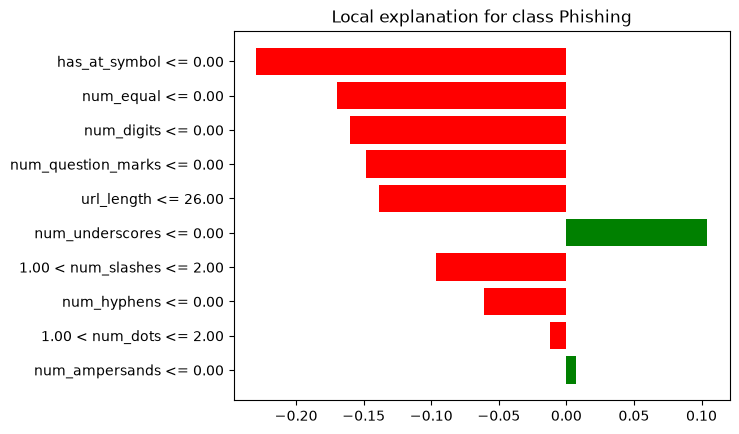

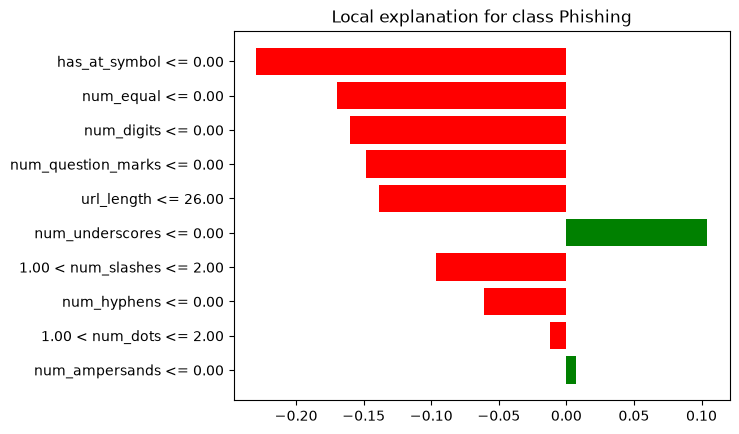

In [106]:
exp.as_pyplot_figure()

In [107]:
print(exp.score)

0.21825045034523927


In [108]:
print(exp.local_pred)

print(exp.predict_proba)

[0.33793376]
[0.92519492 0.07480507]


In [109]:
from collections import Counter

fn_counter = Counter()

for idx in fn_idx:

    exp = explainer.explain_instance(
        X_test_dense[idx],
        SV3_tuned.predict_proba,
        num_features=10
    )

    for feature, weight in exp.as_list():
        fn_counter[feature] += 1

In [110]:
fn_df = pd.DataFrame(

    fn_counter.items(),

    columns=["Feature","Frequency"]

)

fn_df = fn_df.sort_values(

    "Frequency",

    ascending=False

)

fn_df.head(20)

,Feature,Frequency
0,has_at_symbol <= 0.00,3118
8,num_ampersands <= 0.00,3091
1,num_equal <= 0.00,2997
2,num_question_marks <= 0.00,2974
5,num_underscores <= 0.00,2887
7,num_hyphens <= 0.00,2514
3,num_digits <= 0.00,2319
9,1.00 < num_dots <= 2.00,1808
12,34.00 < url_length <= 53.00,1215
6,1.00 < num_slashes <= 2.00,998


In [111]:
fp_counter = Counter()

for idx in fp_idx:

    exp = explainer.explain_instance(

        X_test_dense[idx],

        SV3_tuned.predict_proba,

        num_features=10
    )

    for feature, weight in exp.as_list():

        fp_counter[feature] += 1

In [112]:
fp_df = pd.DataFrame(

    fp_counter.items(),

    columns=["Feature","Frequency"]

)

fp_df = fp_df.sort_values(

    "Frequency",

    ascending=False
)

fp_df.head(20)

,Feature,Frequency
3,has_at_symbol <= 0.00,1243
9,num_ampersands <= 0.00,1217
1,num_equal <= 0.00,1146
5,num_underscores <= 0.00,1145
4,num_question_marks <= 0.00,1138
10,num_slashes <= 1.00,763
12,1.00 < num_dots <= 2.00,745
7,num_hyphens <= 0.00,706
13,num_digits <= 0.00,695
11,url_length <= 26.00,415


In [113]:
comparison = pd.merge(

    fn_df,

    fp_df,

    on="Feature",

    how="outer",

    suffixes=("_FN","_FP")

).fillna(0)

comparison = comparison.sort_values(

    "Frequency_FN",

    ascending=False
)

comparison.head(20)

,Feature,Frequency_FN,Frequency_FP
8,has_at_symbol <= 0.00,3118.0,1243
10,num_ampersands <= 0.00,3091.0,1217
16,num_equal <= 0.00,2997.0,1146
20,num_question_marks <= 0.00,2974.0,1138
24,num_underscores <= 0.00,2887.0,1145
18,num_hyphens <= 0.00,2514.0,706
12,num_digits <= 0.00,2319.0,695
2,1.00 < num_dots <= 2.00,1808.0,745
7,34.00 < url_length <= 53.00,1215.0,288
3,1.00 < num_slashes <= 2.00,998.0,183


FN Predicted Probabilities: [0.92519492 0.07480507]
FN Explanation Score: 0.21563978920667715


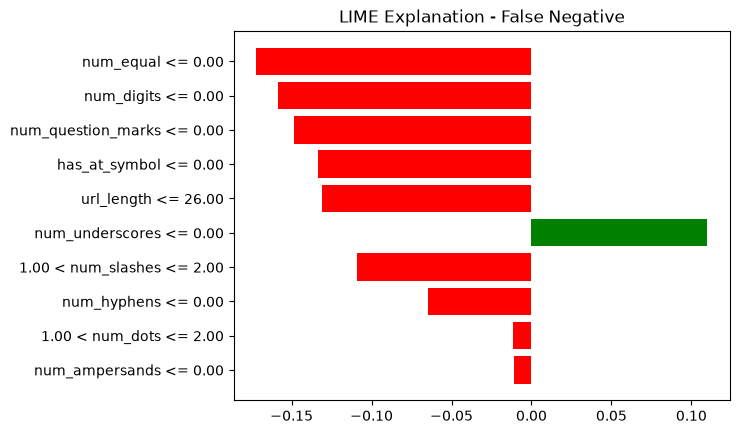

In [114]:
# First False Negative
fn_sample = fn_idx[0]

exp_fn = explainer.explain_instance(
    X_test_dense[fn_sample],
    SV3_tuned.predict_proba,
    num_features=10
)

print("FN Predicted Probabilities:", exp_fn.predict_proba)
print("FN Explanation Score:", exp_fn.score)

fig = exp_fn.as_pyplot_figure()
plt.title("LIME Explanation - False Negative")
plt.show()

FP Predicted Probabilities: [0.4270285  0.57297151]
FP Explanation Score: 0.3471068255766383


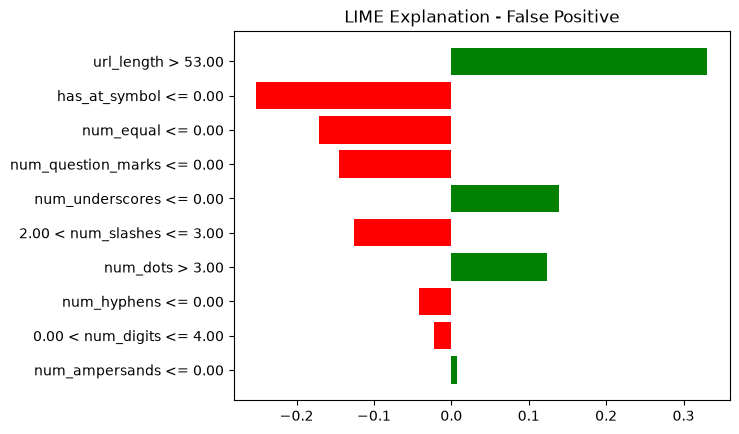

In [115]:
# First False Positive
fp_sample = fp_idx[0]

exp_fp = explainer.explain_instance(
    X_test_dense[fp_sample],
    SV3_tuned.predict_proba,
    num_features=10
)

print("FP Predicted Probabilities:", exp_fp.predict_proba)
print("FP Explanation Score:", exp_fp.score)

fig = exp_fp.as_pyplot_figure()
plt.title("LIME Explanation - False Positive")
plt.show()

In [116]:
# Select one False Negative
fn_sample = fn_idx[0]

exp_fn = explainer.explain_instance(
    X_test_dense[fn_sample],
    SV3_tuned.predict_proba,
    num_features=10
)

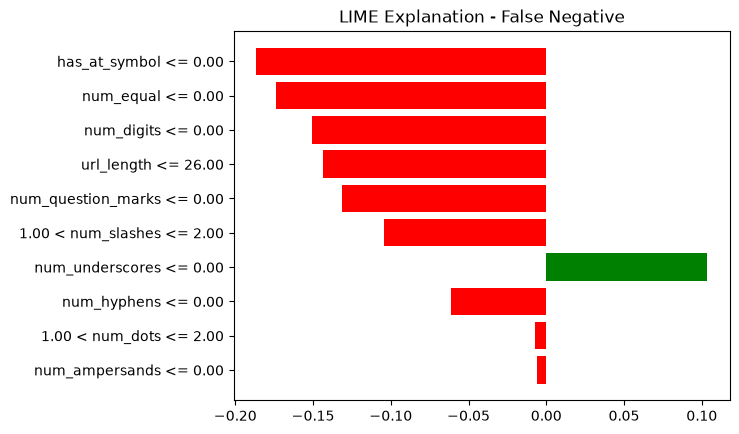

In [117]:
import matplotlib.pyplot as plt

exp_fn.as_pyplot_figure()
plt.title("LIME Explanation - False Negative")
plt.show()

In [118]:
fn_feature_table = pd.DataFrame(
    exp_fn.as_list(),
    columns=["Feature", "Weight"]
)

fn_feature_table

,Feature,Weight
0,has_at_symbol <= 0.00,-0.186497
1,num_equal <= 0.00,-0.173533
2,num_digits <= 0.00,-0.150917
3,url_length <= 26.00,-0.143633
4,num_question_marks <= 0.00,-0.131304
5,1.00 < num_slashes <= 2.00,-0.104378
6,num_underscores <= 0.00,0.103451
7,num_hyphens <= 0.00,-0.061303
8,1.00 < num_dots <= 2.00,-0.007556
9,num_ampersands <= 0.00,-0.005676


In [119]:
fn_feature_table.to_csv(
    "LIME_FN_Feature_Table.csv",
    index=False
)

In [120]:
fp_sample = fp_idx[0]

exp_fp = explainer.explain_instance(
    X_test_dense[fp_sample],
    SV3_tuned.predict_proba,
    num_features=10
)

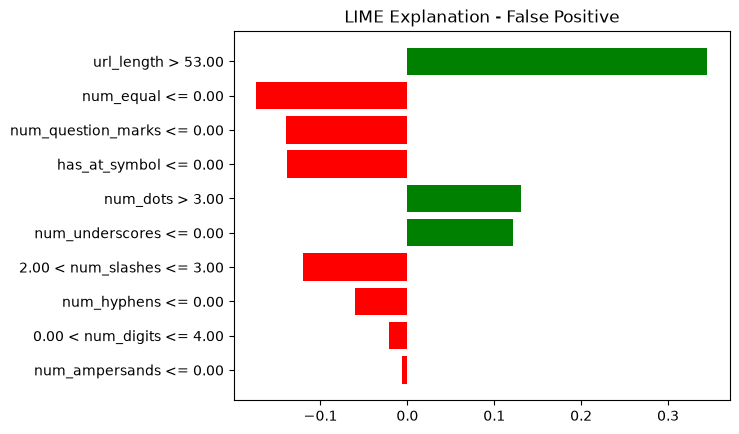

In [121]:
exp_fp.as_pyplot_figure()

plt.title("LIME Explanation - False Positive")

plt.show()

In [122]:
fp_feature_table = pd.DataFrame(
    exp_fp.as_list(),
    columns=["Feature", "Weight"]
)

fp_feature_table

,Feature,Weight
0,url_length > 53.00,0.345032
1,num_equal <= 0.00,-0.173915
2,num_question_marks <= 0.00,-0.139898
3,has_at_symbol <= 0.00,-0.138414
4,num_dots > 3.00,0.131160
5,num_underscores <= 0.00,0.121888
6,2.00 < num_slashes <= 3.00,-0.120085
7,num_hyphens <= 0.00,-0.059887
8,0.00 < num_digits <= 4.00,-0.021472
9,num_ampersands <= 0.00,-0.006267


In [123]:
fp_feature_table.to_csv(
    "LIME_FP_Feature_Table.csv",
    index=False
)

In [124]:
from collections import Counter

fn_counter = Counter()

for idx in fn_idx:

    exp = explainer.explain_instance(
        X_test_dense[idx],
        SV3_tuned.predict_proba,
        num_features=10
    )

    for feature, weight in exp.as_list():

        fn_counter[feature] += 1

In [125]:
fn_df = pd.DataFrame(
    fn_counter.items(),
    columns=["Feature","Frequency"]
)

fn_df = fn_df.sort_values(
    "Frequency",
    ascending=False
)

fn_df.head(20)

,Feature,Frequency
3,has_at_symbol <= 0.00,3118
8,num_ampersands <= 0.00,3091
0,num_equal <= 0.00,2997
1,num_question_marks <= 0.00,2974
6,num_underscores <= 0.00,2887
7,num_hyphens <= 0.00,2514
2,num_digits <= 0.00,2319
9,1.00 < num_dots <= 2.00,1808
12,34.00 < url_length <= 53.00,1215
5,1.00 < num_slashes <= 2.00,998


In [126]:
fp_counter = Counter()

for idx in fp_idx:

    exp = explainer.explain_instance(
        X_test_dense[idx],
        SV3_tuned.predict_proba,
        num_features=10
    )

    for feature, weight in exp.as_list():

        fp_counter[feature] += 1

In [127]:
fp_df = pd.DataFrame(
    fp_counter.items(),
    columns=["Feature","Frequency"]
)

fp_df = fp_df.sort_values(
    "Frequency",
    ascending=False
)

fp_df.head(20)

,Feature,Frequency
1,has_at_symbol <= 0.00,1243
9,num_ampersands <= 0.00,1217
2,num_equal <= 0.00,1146
6,num_underscores <= 0.00,1145
4,num_question_marks <= 0.00,1138
10,num_slashes <= 1.00,763
12,1.00 < num_dots <= 2.00,745
7,num_hyphens <= 0.00,706
13,num_digits <= 0.00,695
11,url_length <= 26.00,415


In [128]:
comparison = pd.merge(
    fn_df,
    fp_df,
    on="Feature",
    how="outer",
    suffixes=("_FN","_FP")
).fillna(0)

comparison = comparison.sort_values(
    "Frequency_FN",
    ascending=False
)

comparison.head(20)

,Feature,Frequency_FN,Frequency_FP
8,has_at_symbol <= 0.00,3118.0,1243
10,num_ampersands <= 0.00,3091.0,1217
16,num_equal <= 0.00,2997.0,1146
20,num_question_marks <= 0.00,2974.0,1138
24,num_underscores <= 0.00,2887.0,1145
18,num_hyphens <= 0.00,2514.0,706
12,num_digits <= 0.00,2319.0,695
2,1.00 < num_dots <= 2.00,1808.0,745
7,34.00 < url_length <= 53.00,1215.0,288
3,1.00 < num_slashes <= 2.00,998.0,183


In [129]:
comparison.to_csv(
    "LIME_FP_FN_Comparison.csv",
    index=False
)

In [130]:
exp = explainer.explain_instance(
    X_test_dense[fn_sample],
    SV3_tuned.predict_proba,
    num_features=20,
    top_labels=2
)

print(exp.available_labels())

print("Legitimate")
print(exp.as_list(label=0))

print("Phishing")
print(exp.as_list(label=1))

[np.int64(0), np.int64(1)]
Legitimate
[('num_equal <= 0.00', 0.16776807996684406), ('num_digits <= 0.00', 0.15917234444046113), ('url_length <= 26.00', 0.13029078698399088), ('num_question_marks <= 0.00', 0.12699545147330427), ('num_underscores <= 0.00', -0.11140066294352026), ('has_at_symbol <= 0.00', 0.10699335934718919), ('1.00 < num_slashes <= 2.00', 0.10571097884786684), ('num_hyphens <= 0.00', 0.05086720624391675), ('num_ampersands <= 0.00', 0.010474983607661663), ('1.00 < num_dots <= 2.00', 0.006621222399381273)]
Phishing
[('num_equal <= 0.00', -0.1677680800324823), ('num_digits <= 0.00', -0.15917234457821278), ('url_length <= 26.00', -0.1302907870394713), ('num_question_marks <= 0.00', -0.1269954515237954), ('num_underscores <= 0.00', 0.11140066277047593), ('has_at_symbol <= 0.00', -0.10699335938431835), ('1.00 < num_slashes <= 2.00', -0.1057109790322063), ('num_hyphens <= 0.00', -0.05086720645270586), ('num_ampersands <= 0.00', -0.010474983566560223), ('1.00 < num_dots <= 2.00

In [131]:
exp_fn = explainer.explain_instance(
    X_test_dense[fn_sample],
    SV3_tuned.predict_proba,
    labels=(0,1),
    num_features=15
)

In [132]:
fn_probs = y_prob[fn_idx,0]

fn_sample = fn_idx[np.argmax(fn_probs)]

print(fn_sample)

19806


In [133]:
fp_probs = y_prob[fp_idx,1]

fp_sample = fp_idx[np.argmax(fp_probs)]

print(fp_sample)

3458


In [134]:
exp_fn = explainer.explain_instance(
    X_test_dense[fn_sample],
    SV3_tuned.predict_proba,
    labels=(0,1),
    num_features=15
)

In [135]:
print("Prediction Probabilities")

print("Legitimate :", exp_fn.predict_proba[0])

print("Phishing   :", exp_fn.predict_proba[1])

Prediction Probabilities
Legitimate : 0.9803175277998987
Phishing   : 0.01968247840891843


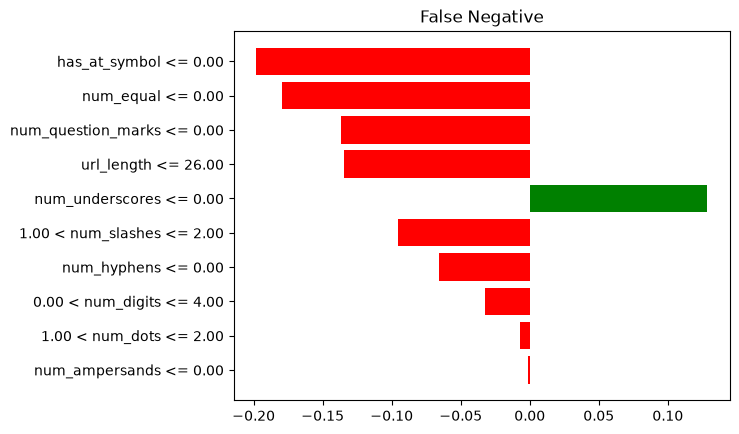

In [136]:

import matplotlib.pyplot as plt

exp_fn.as_pyplot_figure()

plt.title("False Negative")

plt.show()

In [137]:
legitimate_features = pd.DataFrame(
    exp_fn.as_list(label=0),
    columns=["Feature","Weight"]
)

phishing_features = pd.DataFrame(
    exp_fn.as_list(label=1),
    columns=["Feature","Weight"]
)

In [138]:
print("Legitimate Supporting Features")

display(legitimate_features)

print("Phishing Supporting Features")

display(phishing_features)

Legitimate Supporting Features


,Feature,Weight
0,has_at_symbol <= 0.00,0.198071
1,num_equal <= 0.00,0.179555
2,num_question_marks <= 0.00,0.137002
3,url_length <= 26.00,0.134384
4,num_underscores <= 0.00,-0.128502
5,1.00 < num_slashes <= 2.00,0.095085
6,num_hyphens <= 0.00,0.065401
7,0.00 < num_digits <= 4.00,0.032522
8,1.00 < num_dots <= 2.00,0.006779
9,num_ampersands <= 0.00,0.001274


Phishing Supporting Features


,Feature,Weight
0,has_at_symbol <= 0.00,-0.198071
1,num_equal <= 0.00,-0.179555
2,num_question_marks <= 0.00,-0.137002
3,url_length <= 26.00,-0.134384
4,num_underscores <= 0.00,0.128502
5,1.00 < num_slashes <= 2.00,-0.095085
6,num_hyphens <= 0.00,-0.065401
7,0.00 < num_digits <= 4.00,-0.032522
8,1.00 < num_dots <= 2.00,-0.006779
9,num_ampersands <= 0.00,-0.001274


In [139]:
feature_values = pd.DataFrame({

    "Feature":feature_names,

    "Value":X_test_dense[fp_sample]

})

feature_values.head(20)

,Feature,Value
0,url_length,15
1,num_dots,2
2,num_digits,0
3,has_at_symbol,0
4,num_hyphens,1
5,num_slashes,1
6,num_question_marks,0
7,num_equal,0
8,num_underscores,0
9,num_ampersands,0


In [140]:
from collections import Counter

fn_counter = Counter()

for idx in fn_idx:

    exp = explainer.explain_instance(
        X_test_dense[idx],
        SV3_tuned.predict_proba,
        num_features=10
    )

    for f,w in exp.as_list():

        fn_counter[f]+=1

In [141]:
fn_df = pd.DataFrame(

    fn_counter.items(),

    columns=["Feature","Frequency"]

).sort_values("Frequency",ascending=False)

fn_df

,Feature,Frequency
0,has_at_symbol <= 0.00,3118
9,num_ampersands <= 0.00,3091
1,num_equal <= 0.00,2997
3,num_question_marks <= 0.00,2974
5,num_underscores <= 0.00,2887
7,num_hyphens <= 0.00,2514
2,num_digits <= 0.00,2319
8,1.00 < num_dots <= 2.00,1808
12,34.00 < url_length <= 53.00,1215
6,1.00 < num_slashes <= 2.00,998


In [142]:
fp_counter = Counter()

for idx in fp_idx:

    exp = explainer.explain_instance(
        X_test_dense[idx],
        SV3_tuned.predict_proba,
        num_features=10
    )

    for f,w in exp.as_list():

        fp_counter[f]+=1

In [143]:
fp_df = pd.DataFrame(

    fp_counter.items(),

    columns=["Feature","Frequency"]

).sort_values("Frequency",ascending=False)

fp_df

,Feature,Frequency
1,has_at_symbol <= 0.00,1243
9,num_ampersands <= 0.00,1217
2,num_equal <= 0.00,1146
6,num_underscores <= 0.00,1145
3,num_question_marks <= 0.00,1138
10,num_slashes <= 1.00,763
12,1.00 < num_dots <= 2.00,745
7,num_hyphens <= 0.00,706
13,num_digits <= 0.00,695
11,url_length <= 26.00,415


In [144]:
from collections import defaultdict
import numpy as np
import pandas as pd

feature_frequency = defaultdict(int)
feature_weight = defaultdict(float)

# Combine False Negative and False Positive indices
all_error_idx = np.concatenate([fn_idx, fp_idx])

print("Total error samples:", len(all_error_idx))

for sample in all_error_idx:

    exp = explainer.explain_instance(
        X_test_dense[sample],
        SV3_tuned.predict_proba,
        num_features=15
    )

    # Explanation for phishing class (class 1)
    for feature_idx, weight in exp.as_map()[1]:

        feature_frequency[feature_idx] += 1
        feature_weight[feature_idx] += abs(weight)

print("LIME analysis completed.")
print("Number of features found:", len(feature_frequency))

Total error samples: 4364
LIME analysis completed.
Number of features found: 10


In [145]:
importance_df = pd.DataFrame({
    "Feature_Index": list(feature_frequency.keys()),
    "Frequency": [feature_frequency[i] for i in feature_frequency],
    "Total_LIME_Weight": [feature_weight[i] for i in feature_frequency]
})

importance_df["Average_LIME_Weight"] = (
    importance_df["Total_LIME_Weight"] /
    importance_df["Frequency"]
)

importance_df["Feature"] = importance_df["Feature_Index"].apply(
    lambda i: feature_names[i]
)

importance_df = importance_df.sort_values(
    "Total_LIME_Weight",
    ascending=False
)

importance_df.head(20)

,Feature_Index,Frequency,Total_LIME_Weight,Average_LIME_Weight,Feature
5,5,4364,800.541490,0.183442,num_slashes
1,7,4364,748.246539,0.171459,num_equal
0,3,4364,747.006701,0.171175,has_at_symbol
3,6,4364,607.865481,0.139291,num_question_marks
4,0,4364,585.297079,0.134119,url_length
2,2,4364,548.619423,0.125715,num_digits
6,8,4364,502.016822,0.115036,num_underscores
7,4,4364,228.585697,0.052380,num_hyphens
9,1,4364,106.006801,0.024291,num_dots
8,9,4364,36.402021,0.008341,num_ampersands


In [146]:
stats = []

# Top 20 features according to LIME
top_features = importance_df.head(20)

for _, row in top_features.iterrows():

    feature_name = row["Feature"]
    feature_idx = int(row["Feature_Index"])

    # Check whether feature is present in each test sample
    present = X_test_dense[:, feature_idx] > 0

    TP = np.sum(
        present &
        (y_test == 1) &
        (y_pred == 1)
    )

    TN = np.sum(
        present &
        (y_test == 0) &
        (y_pred == 0)
    )

    FP = np.sum(
        present &
        (y_test == 0) &
        (y_pred == 1)
    )

    FN = np.sum(
        present &
        (y_test == 1) &
        (y_pred == 0)
    )

    stats.append([
        feature_name,
        TP,
        TN,
        FP,
        FN
    ])

stats_df = pd.DataFrame(
    stats,
    columns=[
        "Feature",
        "TP",
        "TN",
        "FP",
        "FN"
    ]
)

stats_df

,Feature,TP,TN,FP,FN
0,num_slashes,11002,13157,1246,3118
1,num_equal,3468,577,100,121
2,has_at_symbol,104,1,3,0
3,num_question_marks,3394,619,108,144
4,url_length,11285,13157,1246,3118
5,num_digits,8418,4367,551,799
6,num_underscores,2151,1352,101,231
7,num_hyphens,6014,1864,540,604
8,num_dots,11285,13157,1246,3118
9,num_ampersands,2573,149,29,27


In [147]:
final_analysis = pd.merge(
    importance_df,
    stats_df,
    on="Feature",
    how="inner"
)

final_analysis["Errors"] = (
    final_analysis["FP"] +
    final_analysis["FN"]
)

final_analysis["Correct"] = (
    final_analysis["TP"] +
    final_analysis["TN"]
)

final_analysis["Error_Ratio"] = (
    final_analysis["Errors"] /
    (
        final_analysis["Errors"] +
        final_analysis["Correct"]
    )
)

final_analysis = final_analysis.sort_values(
    by=[
        "Error_Ratio",
        "Total_LIME_Weight"
    ],
    ascending=False
)

final_analysis

,Feature_Index,Frequency,Total_LIME_Weight,Average_LIME_Weight,Feature,TP,TN,FP,FN,Errors,Correct,Error_Ratio
0,5,4364,800.541490,0.183442,num_slashes,11002,13157,1246,3118,4364,24159,0.152999
4,0,4364,585.297079,0.134119,url_length,11285,13157,1246,3118,4364,24442,0.151496
8,1,4364,106.006801,0.024291,num_dots,11285,13157,1246,3118,4364,24442,0.151496
7,4,4364,228.585697,0.052380,num_hyphens,6014,1864,540,604,1144,7878,0.126801
5,2,4364,548.619423,0.125715,num_digits,8418,4367,551,799,1350,12785,0.095508
6,8,4364,502.016822,0.115036,num_underscores,2151,1352,101,231,332,3503,0.086571
3,6,4364,607.865481,0.139291,num_question_marks,3394,619,108,144,252,4013,0.059086
1,7,4364,748.246539,0.171459,num_equal,3468,577,100,121,221,4045,0.051805
2,3,4364,747.006701,0.171175,has_at_symbol,104,1,3,0,3,105,0.027778
9,9,4364,36.402021,0.008341,num_ampersands,2573,149,29,27,56,2722,0.020158


In [148]:
print(final_analysis["Feature"].tolist())

['num_slashes', 'url_length', 'num_dots', 'num_hyphens', 'num_digits', 'num_underscores', 'num_question_marks', 'num_equal', 'has_at_symbol', 'num_ampersands']


In [149]:
feature_to_remove = "num_digits"   # Change this to a valid feature

match = final_analysis.loc[
    final_analysis["Feature"] == feature_to_remove,
    "Feature_Index"
]

if len(match) == 0:
    print(f"{feature_to_remove} not found in final_analysis")
else:
    feature_idx = int(match.iloc[0])
    print("Feature:", feature_to_remove)
    print("Index:", feature_idx)

Feature: num_digits
Index: 2


In [150]:
feature_to_remove = "num_digits"

In [151]:
%who

Counter	 DecisionTreeClassifier	 FN	 FP	 GridSearchCV	 HV1_tuned	 HV2_tuned	 HV3_tuned	 LimeTabularExplainer	 
LogisticRegression	 MLPClassifier	 P_table	 RANDOM_STATE	 RandomForestClassifier	 SV1_tuned	 SV2_tuned	 SV3_tuned	 SVC	 
SelectKBest	 StackingClassifier	 StandardScaler	 TN	 TP	 TfidfVectorizer	 VotingClassifier	 XGBClassifier	 X_numeric	 
X_test	 X_test_70	 X_test_dense	 X_test_num	 X_test_text	 X_text	 X_train	 X_train_70	 X_train_dense	 
X_train_num	 X_train_text	 acc	 accuracy_score	 alexa	 all_error_idx	 all_models	 auc	 balanced	 
best_dt	 best_mlp	 best_rf	 best_xgb	 classification_report	 clean_url	 cm	 combined	 comparison	 
comparison_table	 confusion_matrix	 create_model	 cross_val_score	 csr_matrix	 cv_df	 cv_results	 defaultdict	 df	 
df2	 df3	 dt	 dt_grid	 dt_param_grid	 end	 ensemble_models	 exp	 exp_fn	 
exp_fp	 explainer	 f	 f1	 f1_score	 feature	 feature_frequency	 feature_idx	 feature_name	 
feature_names	 feature_to_remove	 feature_values	 feature_weight	 f

In [152]:
import numpy as np

keep_idx = np.delete(
    np.arange(X_train.shape[1]),
    feature_idx
)

X_train_removed = X_train[:, keep_idx]
X_test_removed  = X_test[:, keep_idx]

print("Original :", X_train.shape)
print("After removal :", X_train_removed.shape)
print("Test :", X_test_removed.shape)

Original : (67212, 10)
After removal : (67212, 9)
Test : (28806, 9)


In [153]:
from sklearn.base import clone

SV3_refined = clone(SV3_tuned)

SV3_refined.fit(
    X_train_removed,
    y_train
)

,"estimators estimators: list of (str, estimator) tuplesInvoking the ``fit`` method on the ``VotingClassifier`` will fit clonesof those original estimators that will be stored in the class attribute``self.estimators_``. An estimator can be set to ``'drop'`` using:meth:`set_params`... versionchanged:: 0.21 ``'drop'`` is accepted. Using None was deprecated in 0.22 and support was removed in 0.24.","[('rf', ...), ('mlp', ...), ...]"
,"voting voting: {'hard', 'soft'}, default='hard'If 'hard', uses predicted class labels for majority rule voting.Else if 'soft', predicts the class label based on the argmax ofthe sums of the predicted probabilities, which is recommended foran ensemble of well-calibrated classifiers.",'soft'
,"weights weights: array-like of shape (n_classifiers,), default=NoneSequence of weights (`float` or `int`) to weight the occurrences ofpredicted class labels (`hard` voting) or class probabilitiesbefore averaging (`soft` voting). Uses uniform weights if `None`.",None
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for ``fit``.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionadded:: 0.18",None
,"flatten_transform flatten_transform: bool, default=TrueAffects shape of transform output only when voting='soft'If voting='soft' and flatten_transform=True, transform method returnsmatrix with shape (n_samples, n_classifiers * n_classes). Ifflatten_transform=False, it returns(n_classifiers, n_samples, n_classes).",True
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting will be printed as itis completed... versionadded:: 0.23",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels.","ndarray[float64](2,)","[0.,1.]"
"estimators_ estimators_: list of classifiersThe collection of fitted sub-estimators as defined in ``estimators``that are not 'drop'. Note that sub-estimators are always fitted oninteger-encoded labels (see ``le_`` attribute). When ``y`` containsnon-integer class labels (e.g. strings), use ``le_.inverse_transform``to map predictions back to the original label space.",list,"[RandomForestC...ndom_state=42), MLPClassifier...ndom_state=42), XGBClassifier...ree=None, ...)]"
le_ le_: :class:`~sklearn.preprocessing.LabelEncoder`Transformer used to encode the labels during fit and decode duringprediction. Sub-estimators in ``estimators_`` are fitted on theinteger-encoded labels produced by this encoder.,LabelEncoder,LabelEncoder()
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying classifier exposes such an attribute when fit... versionadded:: 0.24,int,9


In [154]:
y_pred_removed = SV3_refined.predict(X_test_removed)
y_prob_removed = SV3_refined.predict_proba(X_test_removed)[:, 1]

In [155]:
y_pred_removed = SV3_refined.predict(X_test_removed)
y_prob_removed = SV3_refined.predict_proba(X_test_removed)[:,1]

In [156]:
y_pred_removed = SV3_refined.predict(X_test_removed)
y_prob_removed = SV3_refined.predict_proba(X_test_removed)[:, 1]

In [157]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    confusion_matrix
)

# BEFORE removal
y_train_pred_pre = SV3_tuned.predict(X_train)
y_train_prob_pre = SV3_tuned.predict_proba(X_train)[:,1]

train_acc_pre = accuracy_score(y_train, y_train_pred_pre)
train_f1_pre = f1_score(y_train, y_train_pred_pre)
train_auc_pre = roc_auc_score(y_train, y_train_prob_pre)
train_mcc_pre = matthews_corrcoef(y_train, y_train_pred_pre)
train_prec_pre = precision_score(y_train, y_train_pred_pre)
train_rec_pre = recall_score(y_train, y_train_pred_pre)

tn_pre, fp_pre, fn_pre, tp_pre = confusion_matrix(
    y_train,
    y_train_pred_pre
).ravel()

In [158]:
y_train_pred_post = SV3_refined.predict(X_train_removed)
y_train_prob_post = SV3_refined.predict_proba(X_train_removed)[:,1]

train_acc_post = accuracy_score(y_train, y_train_pred_post)
train_f1_post = f1_score(y_train, y_train_pred_post)
train_auc_post = roc_auc_score(y_train, y_train_prob_post)
train_mcc_post = matthews_corrcoef(y_train, y_train_pred_post)
train_prec_post = precision_score(y_train, y_train_pred_post)
train_rec_post = recall_score(y_train, y_train_pred_post)

tn_post, fp_post, fn_post, tp_post = confusion_matrix(
    y_train,
    y_train_pred_post
).ravel()

In [159]:
y_test_pred_pre = SV3_tuned.predict(X_test)
y_test_prob_pre = SV3_tuned.predict_proba(X_test)[:,1]

test_acc_pre = accuracy_score(y_test, y_test_pred_pre)
test_f1_pre = f1_score(y_test, y_test_pred_pre)
test_auc_pre = roc_auc_score(y_test, y_test_prob_pre)
test_mcc_pre = matthews_corrcoef(y_test, y_test_pred_pre)
test_prec_pre = precision_score(y_test, y_test_pred_pre)
test_rec_pre = recall_score(y_test, y_test_pred_pre)

tn_pre_test, fp_pre_test, fn_pre_test, tp_pre_test = confusion_matrix(
    y_test,
    y_test_pred_pre
).ravel()

In [160]:
y_test_pred_post = SV3_refined.predict(X_test_removed)
y_test_prob_post = SV3_refined.predict_proba(X_test_removed)[:,1]

test_acc_post = accuracy_score(y_test, y_test_pred_post)
test_f1_post = f1_score(y_test, y_test_pred_post)
test_auc_post = roc_auc_score(y_test, y_test_prob_post)
test_mcc_post = matthews_corrcoef(y_test, y_test_pred_post)
test_prec_post = precision_score(y_test, y_test_pred_post)
test_rec_post = recall_score(y_test, y_test_pred_post)

tn_post_test, fp_post_test, fn_post_test, tp_post_test = confusion_matrix(
    y_test,
    y_test_pred_post
).ravel()

In [161]:
train_table = pd.DataFrame({

"Model":["Pre-Explainable AI","Post-Explainable AI"],

"Train Accuracy (%)":[train_acc_pre*100,train_acc_post*100],

"F1":[train_f1_pre,train_f1_post],

"AUC":[train_auc_pre,train_auc_post],

"MCC":[train_mcc_pre,train_mcc_post],

"Precision":[train_prec_pre,train_prec_post],

"Recall":[train_rec_pre,train_rec_post],

"TP":[tp_pre,tp_post],

"FP":[fp_pre,fp_post],

"TN":[tn_pre,tn_post],

"FN":[fn_pre,fn_post]

})

train_table

,Model,Train Accuracy (%),F1,AUC,MCC,Precision,Recall,TP,FP,TN,FN
0,Pre-Explainable AI,86.078379,0.850582,0.937772,0.728391,0.917841,0.792507,26633,2384,31222,6973
1,Post-Explainable AI,83.513361,0.821588,0.920793,0.678131,0.895134,0.759210,25514,2989,30617,8092


In [162]:
test_table = pd.DataFrame({

"Model":["Pre-Explainable AI","Post-Explainable AI"],

"Test Accuracy (%)":[test_acc_pre*100,test_acc_post*100],

"F1":[test_f1_pre,test_f1_post],

"AUC":[test_auc_pre,test_auc_post],

"MCC":[test_mcc_pre,test_mcc_post],

"Precision":[test_prec_pre,test_prec_post],

"Recall":[test_rec_pre,test_rec_post],

"TP":[tp_pre_test,tp_post_test],

"FP":[fp_pre_test,fp_post_test],

"TN":[tn_pre_test,tn_post_test],

"FN":[fn_pre_test,fn_post_test]

})

test_table

,Model,Test Accuracy (%),F1,AUC,MCC,Precision,Recall,TP,FP,TN,FN
0,Pre-Explainable AI,84.850378,0.837974,0.925876,0.702970,0.900567,0.783517,11285,1246,13157,3118
1,Post-Explainable AI,82.642505,0.812256,0.909514,0.660417,0.884455,0.750955,10816,1413,12990,3587


In [163]:
# Dense versions (already dense for handcrafted features)
X_train_dense = X_train.copy()
X_test_dense = X_test.copy()

print(type(X_train_dense))
print(type(X_test_dense))

print(X_train_dense.shape)
print(X_test_dense.shape)

<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
(67212, 10)
(28806, 10)


In [164]:
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [165]:
feature_names = [
    "num_slashes",
    "num_dots",
    "url_length",
    "num_hyphens",
    "num_digits",
    "num_underscores",
    "num_question_marks",
    "num_equal",
    "has_at_symbol",
    "num_ampersands"
]

print(feature_names)
print(len(feature_names))

['num_slashes', 'num_dots', 'url_length', 'num_hyphens', 'num_digits', 'num_underscores', 'num_question_marks', 'num_equal', 'has_at_symbol', 'num_ampersands']
10


In [166]:
print(SV3_tuned)
print(SV3_tuned.estimators_)

VotingClassifier(estimators=[('rf',
                              RandomForestClassifier(max_depth=20,
                                                     min_samples_split=5,
                                                     n_estimators=200,
                                                     random_state=42)),
                             ('mlp',
                              MLPClassifier(hidden_layer_sizes=(100, 50),
                                            max_iter=300, random_state=42)),
                             ('xgb',
                              XGBClassifier(base_score=None, booster=None,
                                            callbacks=None,
                                            colsample_bylevel=None,
                                            colsample_bynode=None,
                                            colsample_bytree=None, device=None,...
                                            feature_weights=None, gamma=None,
                        

In [167]:
import shap
import numpy as np

background = shap.sample(
    X_train_dense,
    100,
    random_state=42
)

print(background.shape)

(100, 10)


In [168]:
predict_fn = lambda x: SV3_tuned.predict_proba(x)

print(predict_fn(background).shape)

(100, 2)


In [169]:
explainer = shap.KernelExplainer(
    predict_fn,
    background
)

In [170]:
X_sample = X_test_dense[:500]

In [171]:
shap_values = explainer.shap_values(
    X_sample
)

100%|████████████████████████████████████████████████████████████████████████████████| 500/500 [02:31<00:00,  3.30it/s]


In [172]:
print(type(shap_values))
print(np.array(shap_values).shape)

<class 'numpy.ndarray'>
(500, 10, 2)


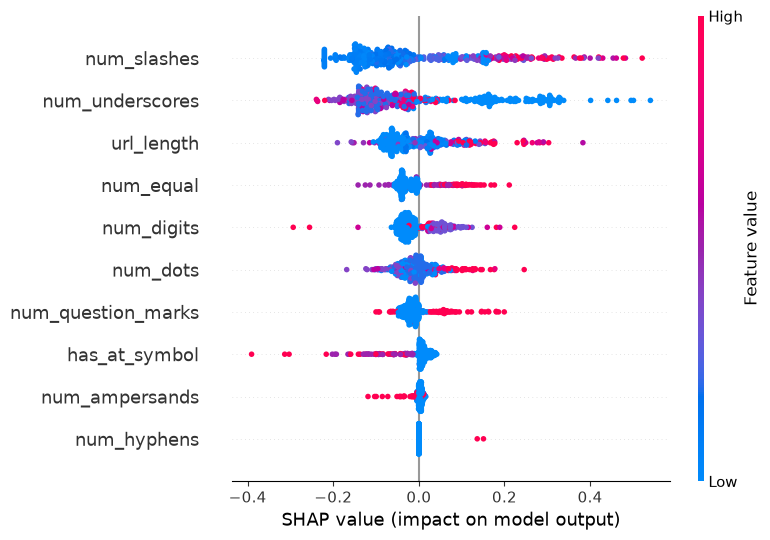

In [173]:
shap.summary_plot(
    shap_values[:, :, 1],
    X_sample,
    feature_names=feature_names
)

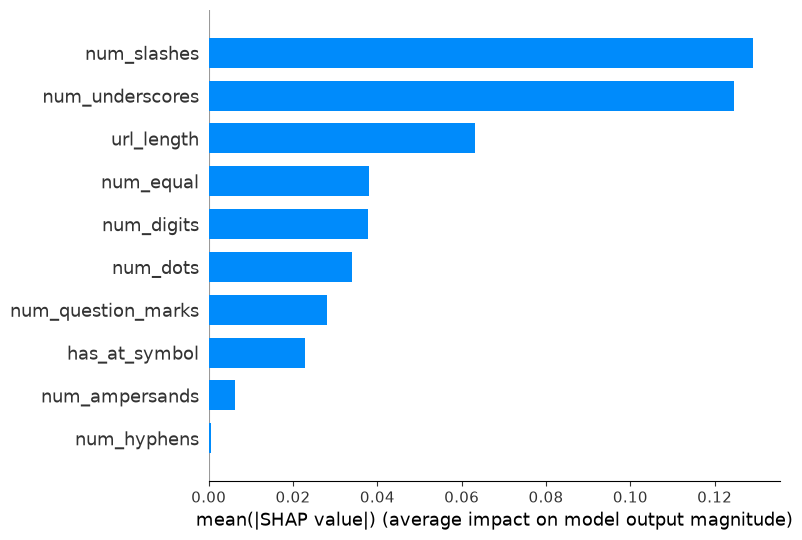

In [174]:
shap.summary_plot(
    shap_values[:, :, 1],
    X_sample,
    feature_names=feature_names,
    plot_type="bar"
)

In [175]:
import pandas as pd
import numpy as np

mean_abs_shap = np.abs(shap_values[:, :, 1]).mean(axis=0)

shap_importance = pd.DataFrame({
    "Feature": feature_names,
    "Mean |SHAP|": mean_abs_shap
})

shap_importance = shap_importance.sort_values(
    by="Mean |SHAP|",
    ascending=False
)

shap_importance

,Feature,Mean |SHAP|
0,num_slashes,0.129033
5,num_underscores,0.124648
2,url_length,0.063240
7,num_equal,0.038056
4,num_digits,0.037783
1,num_dots,0.033969
6,num_question_marks,0.027943
8,has_at_symbol,0.022949
9,num_ampersands,0.006118
3,num_hyphens,0.000575


In [176]:
TOP_N = 20

shap_top20 = shap_importance.head(TOP_N)

shap_top20

,Feature,Mean |SHAP|
0,num_slashes,0.129033
5,num_underscores,0.124648
2,url_length,0.063240
7,num_equal,0.038056
4,num_digits,0.037783
1,num_dots,0.033969
6,num_question_marks,0.027943
8,has_at_symbol,0.022949
9,num_ampersands,0.006118
3,num_hyphens,0.000575


In [177]:
from collections import Counter

fn_idx = np.where((y_test == 1) & (y_pred == 0))[0]

fp_idx = np.where((y_test == 0) & (y_pred == 1))[0]

print("False Negatives :", len(fn_idx))
print("False Positives :", len(fp_idx))

False Negatives : 3118
False Positives : 1246


In [178]:
all_error_idx = np.concatenate([fn_idx, fp_idx])

print("Total Error Samples :", len(all_error_idx))

Total Error Samples : 4364


In [179]:
from collections import defaultdict

feature_frequency = defaultdict(int)
feature_weight = defaultdict(float)

In [180]:
from lime.lime_tabular import LimeTabularExplainer
from collections import defaultdict
import numpy as np
import pandas as pd

In [181]:
lime_explainer = LimeTabularExplainer(
    training_data=X_train_dense,
    feature_names=feature_names,
    class_names=["Legitimate", "Phishing"],
    mode="classification",
    random_state=42
)

In [182]:
LIME_SAMPLE_SIZE = 500

sample_indices = np.random.RandomState(42).choice(
    len(X_test_dense),
    size=LIME_SAMPLE_SIZE,
    replace=False
)

In [183]:
feature_frequency = defaultdict(int)

feature_total_weight = defaultdict(float)

In [184]:
import re

def clean_feature_name(feature):
    feature = str(feature)
    # strip a leading "number <" or "number <=" (e.g. "0.05 < api" -> "api")
    feature = re.sub(r'^-?\d+\.?\d*\s*[<>]=?\s*', '', feature)
    # strip a trailing "<= number" or "> number" (e.g. "api <= 0.10" -> "api")
    feature = re.sub(r'\s*[<>]=?\s*-?\d+\.?\d*$', '', feature)
    return feature.strip()

for idx in sample_indices:

    exp = lime_explainer.explain_instance(
        X_test_dense[idx],
        SV3_tuned.predict_proba,
        num_features=20
    )

    for feature, weight in exp.as_list():

        clean_feature = clean_feature_name(feature)

        feature_frequency[clean_feature] += 1

        feature_total_weight[clean_feature] += abs(weight)

In [185]:
lime_df = pd.DataFrame({

    "Feature": list(feature_frequency.keys()),

    "Frequency": list(feature_frequency.values()),

    "Total_LIME_Weight":[
        feature_total_weight[f]
        for f in feature_frequency
    ]

})

In [186]:
lime_df["Average_LIME_Weight"] = (

    lime_df["Total_LIME_Weight"] /

    lime_df["Frequency"]

)

In [187]:
lime_df = lime_df.sort_values(

    "Total_LIME_Weight",

    ascending=False

)

lime_df.head(20)

,Feature,Frequency,Total_LIME_Weight,Average_LIME_Weight
4,num_underscores,500,86.427187,0.172854
1,num_equal,500,85.023595,0.170047
0,num_hyphens,500,84.037879,0.168076
5,num_slashes,500,80.821373,0.161643
2,num_question_marks,500,69.392200,0.138784
7,url_length,500,64.883173,0.129766
3,has_at_symbol,500,57.652520,0.115305
6,num_digits,500,25.558182,0.051116
8,num_dots,500,14.241160,0.028482
9,num_ampersands,500,4.097781,0.008196


In [188]:
TOP_N = 20

lime_top20 = lime_df.head(TOP_N)

lime_top20

,Feature,Frequency,Total_LIME_Weight,Average_LIME_Weight
4,num_underscores,500,86.427187,0.172854
1,num_equal,500,85.023595,0.170047
0,num_hyphens,500,84.037879,0.168076
5,num_slashes,500,80.821373,0.161643
2,num_question_marks,500,69.392200,0.138784
7,url_length,500,64.883173,0.129766
3,has_at_symbol,500,57.652520,0.115305
6,num_digits,500,25.558182,0.051116
8,num_dots,500,14.241160,0.028482
9,num_ampersands,500,4.097781,0.008196


In [189]:
from sklearn.inspection import permutation_importance

In [190]:
print(type(X_test))

<class 'numpy.ndarray'>


In [191]:
perm_result = permutation_importance(
    estimator=SV3_tuned,
    X=X_test_dense,
    y=y_test,
    scoring="accuracy",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

In [192]:
perm_df = pd.DataFrame({
    "Feature": feature_names,
    "Permutation_Importance": perm_result.importances_mean,
    "Permutation_STD": perm_result.importances_std
})

In [193]:
perm_df = perm_df.sort_values(
    by="Permutation_Importance",
    ascending=False
).reset_index(drop=True)

perm_df.head(20)

,Feature,Permutation_Importance,Permutation_STD
0,num_underscores,0.158019,0.001307
1,num_slashes,0.143560,0.000824
2,url_length,0.086892,0.001682
3,num_equal,0.048865,0.001201
4,num_question_marks,0.037888,0.001432
5,num_dots,0.036281,0.001086
6,num_digits,0.031632,0.001103
7,has_at_symbol,0.015254,0.000578
8,num_ampersands,0.003541,0.000418
9,num_hyphens,0.001788,0.000187


In [194]:
TOP_N = 20

perm_top20 = perm_df.head(TOP_N)

perm_top20

,Feature,Permutation_Importance,Permutation_STD
0,num_underscores,0.158019,0.001307
1,num_slashes,0.143560,0.000824
2,url_length,0.086892,0.001682
3,num_equal,0.048865,0.001201
4,num_question_marks,0.037888,0.001432
5,num_dots,0.036281,0.001086
6,num_digits,0.031632,0.001103
7,has_at_symbol,0.015254,0.000578
8,num_ampersands,0.003541,0.000418
9,num_hyphens,0.001788,0.000187


In [195]:
perm_top20.to_csv(
    "Permutation_Top20.csv",
    index=False
)

perm_df.to_csv(
    "Permutation_AllFeatures.csv",
    index=False
)

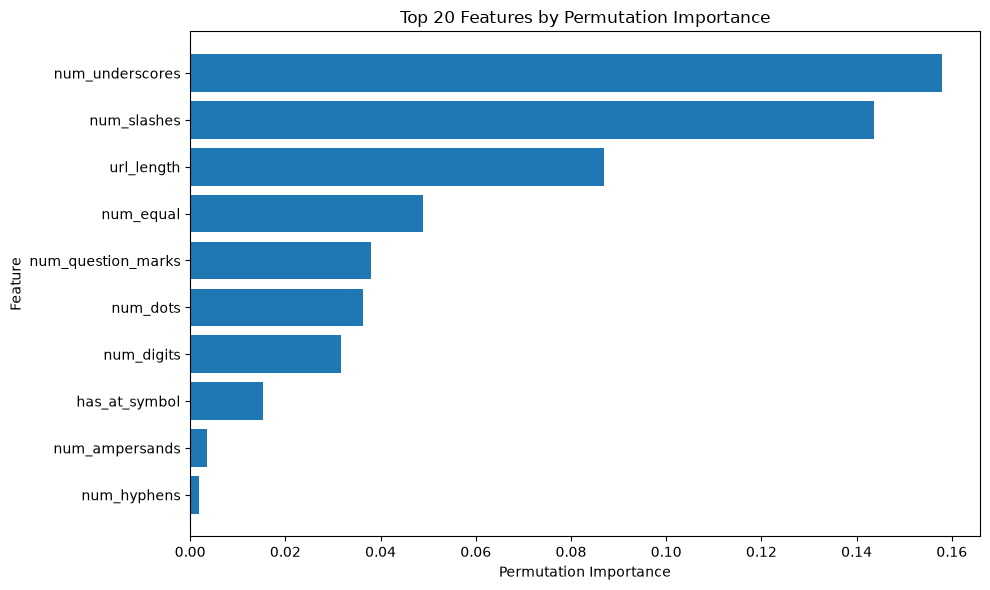

In [196]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    perm_top20["Feature"][::-1],
    perm_top20["Permutation_Importance"][::-1]
)

plt.xlabel("Permutation Importance")
plt.ylabel("Feature")
plt.title("Top 20 Features by Permutation Importance")

plt.tight_layout()
plt.show()

In [197]:
TOP_N = 20

shap_top20 = shap_importance.head(TOP_N).copy()

lime_top20 = lime_df.head(TOP_N).copy()

perm_top20 = perm_df.head(TOP_N).copy()

In [198]:
import re

def clean_feature(feature):
    feature = str(feature)
    # strip a leading "number <" or "number <=" (e.g. "0.05 < api" -> "api")
    feature = re.sub(r'^-?\d+\.?\d*\s*[<>]=?\s*', '', feature)
    # strip a trailing "<= number" or "> number" (e.g. "api <= 0.10" -> "api")
    feature = re.sub(r'\s*[<>]=?\s*-?\d+\.?\d*$', '', feature)
    return feature.strip()

In [199]:
shap_top20["Feature"] = shap_top20["Feature"].apply(clean_feature)

lime_top20["Feature"] = lime_top20["Feature"].apply(clean_feature)

perm_top20["Feature"] = perm_top20["Feature"].apply(clean_feature)

In [200]:
shap_set = set(shap_top20["Feature"])

lime_set = set(lime_top20["Feature"])

perm_set = set(perm_top20["Feature"])

In [201]:
print("SHAP ∩ LIME")
print(shap_set & lime_set)

print()

print("SHAP ∩ Permutation")
print(shap_set & perm_set)

print()

print("LIME ∩ Permutation")
print(lime_set & perm_set)

SHAP ∩ LIME
{'num_dots', 'num_hyphens', 'has_at_symbol', 'url_length', 'num_slashes', 'num_underscores', 'num_equal', 'num_digits', 'num_ampersands', 'num_question_marks'}

SHAP ∩ Permutation
{'num_hyphens', 'num_dots', 'has_at_symbol', 'url_length', 'num_slashes', 'num_underscores', 'num_equal', 'num_digits', 'num_ampersands', 'num_question_marks'}

LIME ∩ Permutation
{'num_hyphens', 'num_dots', 'has_at_symbol', 'url_length', 'num_slashes', 'num_underscores', 'num_equal', 'num_digits', 'num_ampersands', 'num_question_marks'}


In [202]:
# Sanity check: do the handcrafted feature names actually land on sensible columns?
handcrafted_features = [
    "url_length", "num_dots", "num_digits", "has_at_symbol",
    "num_hyphens", "num_slashes", "num_question_marks",
    "num_equal", "num_underscores", "num_ampersands"
]

for name in handcrafted_features:
    if name in feature_names:
        idx = list(feature_names).index(name)
        col_values = X_train_dense[:, idx]
        print(f"{name}: min={col_values.min():.2f}, max={col_values.max():.2f}, mean={col_values.mean():.2f}")
    else:
        print(f"{name}: NOT in feature_names_200 (may have been dropped by MI selection)")

url_length: min=0.00, max=347.00, mean=5.83
num_dots: min=0.00, max=67.00, mean=2.35
num_digits: min=0.00, max=35.00, mean=0.59
has_at_symbol: min=0.00, max=33.00, mean=0.23
num_hyphens: min=0.00, max=1.00, mean=0.00
num_slashes: min=7.00, max=1512.00, mean=52.09
num_question_marks: min=0.00, max=17.00, mean=0.17
num_equal: min=0.00, max=42.00, mean=0.35
num_underscores: min=0.00, max=102.00, mean=2.48
num_ampersands: min=0.00, max=41.00, mean=0.20


In [203]:
handcrafted_indices = list(range(len(handcrafted_features)))

selected_indices = mi_selector.get_support(indices=True)

overlap = set(handcrafted_indices) & set(selected_indices)

print("Handcrafted features kept:", len(overlap))
print("Which ones:", [handcrafted_features[i] for i in sorted(overlap)])

Handcrafted features kept: 10
Which ones: ['url_length', 'num_dots', 'num_digits', 'has_at_symbol', 'num_hyphens', 'num_slashes', 'num_question_marks', 'num_equal', 'num_underscores', 'num_ampersands']


In [204]:
# ===== Compatibility variables for original notebook =====

import numpy as np
import pandas as pd

# Original notebook aliases
feature_names_200 = np.array(handcrafted_features)

X_train_200 = X_train
X_test_200 = X_test

# Original notebook expected MI outputs
top200_idx = np.arange(len(handcrafted_features))      # 0..9
mi_df = pd.DataFrame({
    "Feature_Index": np.arange(len(handcrafted_features)),
    "MI_Score": np.zeros(len(handcrafted_features))
})

In [205]:
print("top200_idx dtype/shape:", top200_idx.shape, top200_idx.dtype)
print("Max index in top200_idx:", top200_idx.max())
print("X_train shape at the point top200_idx was computed:", X_train.shape)

top200_idx dtype/shape: (10,) int64
Max index in top200_idx: 9
X_train shape at the point top200_idx was computed: (67212, 10)


In [206]:
print("len(feature_names_200):", len(feature_names_200))
print("First 10 of feature_names_200:", feature_names_200[:10])
print("Last 10 of feature_names_200:", feature_names_200[-10:])

len(feature_names_200): 10
First 10 of feature_names_200: ['url_length' 'num_dots' 'num_digits' 'has_at_symbol' 'num_hyphens'
 'num_slashes' 'num_question_marks' 'num_equal' 'num_underscores'
 'num_ampersands']
Last 10 of feature_names_200: ['url_length' 'num_dots' 'num_digits' 'has_at_symbol' 'num_hyphens'
 'num_slashes' 'num_question_marks' 'num_equal' 'num_underscores'
 'num_ampersands']


In [207]:
print("mi_df shape:", mi_df.shape)
print("mi_df columns:", mi_df.columns.tolist())
print(mi_df.head())

mi_df shape: (10, 2)
mi_df columns: ['Feature_Index', 'MI_Score']
   Feature_Index  MI_Score
0              0       0.0
1              1       0.0
2              2       0.0
3              3       0.0
4              4       0.0


In [208]:
import sys
!{sys.executable} -m pip install dice-ml


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: pip3 install --upgrade pip


In [209]:
import dice_ml
from dice_ml import Dice
import pandas as pd

In [210]:
print(type(X_train))
print(X_train_200.shape)

print(type(feature_names_200))
print(len(feature_names_200))

<class 'numpy.ndarray'>
(67212, 10)
<class 'numpy.ndarray'>
10


In [211]:
X_train_df = pd.DataFrame(
    X_train_200,
    columns=feature_names_200
)

X_test_df = pd.DataFrame(
    X_test_200,
    columns=feature_names_200
)

In [212]:
X_train_df["label"] = y_train

In [213]:
continuous_features = feature_names_200.tolist()

In [214]:
d = dice_ml.Data(
    dataframe=X_train_df,
    continuous_features=continuous_features,
    outcome_name="label"
)

In [215]:
m = dice_ml.Model(
    model=SV3_tuned,
    backend="sklearn",
    model_type="classifier"
)

In [216]:
exp_kdtree = Dice(d, m, method="kdtree")

In [217]:
# reuse the same samples used for LIME
dice_sample_indices = sample_indices[:150]

In [218]:
top_k_for_dice = list(feature_names_200)

In [219]:
exp_genetic_fast = Dice(d, m, method="genetic")

In [220]:
print(len(top_k_for_dice))
print(top_k_for_dice)

10
[np.str_('url_length'), np.str_('num_dots'), np.str_('num_digits'), np.str_('has_at_symbol'), np.str_('num_hyphens'), np.str_('num_slashes'), np.str_('num_question_marks'), np.str_('num_equal'), np.str_('num_underscores'), np.str_('num_ampersands')]


In [221]:
query = X_test_df.loc[[dice_sample_indices[0]]].drop(
    columns=["label"], errors="ignore"
)

In [222]:
print(query.shape)
query.head()

(1, 10)


,url_length,num_dots,num_digits,has_at_symbol,num_hyphens,num_slashes,num_question_marks,num_equal,num_underscores,num_ampersands
6011,44,3,1,0,0,2,0,0,0,0


In [223]:
print(SV3_tuned.predict(query))

[1.]


In [224]:
print(type(exp_genetic_fast))

<class 'dice_ml.explainer_interfaces.dice_genetic.DiceGenetic'>


In [225]:
print(SV3_tuned.predict(query))

[1.]


In [226]:
import time

start = time.time()

cf = exp_genetic_fast.generate_counterfactuals(
    query,
    total_CFs=1,
    desired_class="opposite",
    features_to_vary=top_k_for_dice,
    maxiterations=5,
    verbose=False
)

print("Finished")
print("Time:", time.time() - start)

100%|████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:07<00:00,  7.76s/it]

Finished
Time: 7.758839845657349


In [227]:
import inspect

print(inspect.signature(exp_genetic_fast._generate_counterfactuals))

(query_instance, total_CFs, initialization='kdtree', desired_range=None, desired_class='opposite', proximity_weight=0.2, sparsity_weight=0.2, diversity_weight=5.0, categorical_penalty=0.1, algorithm='DiverseCF', features_to_vary='all', permitted_range=None, yloss_type='hinge_loss', diversity_loss_type='dpp_style:inverse_dist', feature_weights='inverse_mad', stopping_threshold=0.5, posthoc_sparsity_param=0.1, posthoc_sparsity_algorithm='binary', maxiterations=500, thresh=0.01, verbose=False)


In [228]:
cf_results = {}

for idx in dice_sample_indices:

    query = X_test_df.loc[[idx]].drop(columns=["label"], errors="ignore")

    cf = exp_genetic_fast.generate_counterfactuals(
        query,
        total_CFs=3,
        desired_class="opposite",
        features_to_vary=top_k_for_dice,
        maxiterations=50,
        verbose=False
    )

    cf_results[idx] = cf

100%|████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:13<00:00, 13.28s/it]


In [229]:
len(cf_results)

150

In [230]:
import pickle

with open("cf_results.pkl", "wb") as f:
    pickle.dump(cf_results, f)

print("Saved", len(cf_results), "counterfactuals.")

Saved 150 counterfactuals.


In [231]:
from collections import defaultdict
import pandas as pd

dice_feature_frequency = defaultdict(int)
dice_feature_weight = defaultdict(float)
dice_flagged_per_instance = {}

for idx, cf in cf_results.items():

    orig_row = X_test_df.loc[idx]

    cf_df = cf.cf_examples_list[0].final_cfs_df

    if cf_df is None or len(cf_df) == 0:
        continue

    instance_flipped = set()

    for _, cf_row in cf_df.iterrows():

        for f in top_k_for_dice:

            diff = abs(orig_row[f] - cf_row[f])

            if diff > 1e-6:
                dice_feature_frequency[f] += 1
                dice_feature_weight[f] += diff
                instance_flipped.add(f)

    dice_flagged_per_instance[idx] = instance_flipped

print("Processed:", len(dice_flagged_per_instance), "instances")

Processed: 150 instances


In [232]:
dice_table_final = pd.DataFrame({
    "feature": list(dice_feature_frequency.keys()),
    "frequency": list(dice_feature_frequency.values()),
    "total_weight": [
        dice_feature_weight[f]
        for f in dice_feature_frequency.keys()
    ]
}).sort_values("frequency", ascending=False)

dice_table_final.to_csv(
    "DICE_Feature_Table.csv",
    index=False
)

print(dice_table_final.head(20))

              feature  frequency  total_weight
1         num_slashes        345         949.0
4          url_length        205        6772.0
0          num_digits        164        1645.0
2            num_dots        138         315.0
3         num_hyphens        134         364.0
5     num_underscores         61         221.0
8  num_question_marks         31          36.0
6           num_equal         27          54.0
7      num_ampersands         11          16.0
9       has_at_symbol          1           1.0


In [233]:
combined_idx = list(cf_results.keys())

print("Instances:", len(combined_idx))

Instances: 150


In [234]:
lime_flagged_per_instance = {}

for idx in combined_idx:
    exp = lime_explainer.explain_instance(
        X_test_dense[idx],
        SV3_tuned.predict_proba,
        num_features=20
    )

    lime_flagged_per_instance[idx] = {
        clean_feature_name(f)
        for f, w in exp.as_list()
    }

print("LIME done for:", len(lime_flagged_per_instance), "instances")

LIME done for: 150 instances


In [235]:
def jaccard(a, b):
    if not a and not b:
        return 1.0
    return len(a & b) / len(a | b)

rows = []

for idx in combined_idx:
    score = jaccard(
        lime_flagged_per_instance[idx],
        dice_flagged_per_instance[idx]
    )

    rows.append({
        "idx": idx,
        "label": y_test.iloc[idx],
        "jaccard": score
    })

local_agreement_df = pd.DataFrame(rows)

print("Overall mean Jaccard:",
      local_agreement_df["jaccard"].mean())

print(
    local_agreement_df.groupby("label")["jaccard"]
    .agg(["mean", "count"])
)

Overall mean Jaccard: 0.3793333333333333
           mean  count
label                 
0.0    0.327536     69
1.0    0.423457     81


In [236]:
lime_flagged_restricted = {
    idx: (feats & set(top_k_for_dice))
    for idx, feats in lime_flagged_per_instance.items()
}

rows = []

for idx in combined_idx:
    score = jaccard(
        lime_flagged_restricted[idx],
        dice_flagged_per_instance[idx]
    )

    rows.append({
        "idx": idx,
        "label": y_test.iloc[idx],
        "jaccard": score
    })

local_agreement_df2 = pd.DataFrame(rows)

print(
    "Overall mean Jaccard (scope-matched):",
    local_agreement_df2["jaccard"].mean()
)

print(
    local_agreement_df2.groupby("label")["jaccard"]
    .agg(["mean", "count"])
)

Overall mean Jaccard (scope-matched): 0.3793333333333333
           mean  count
label                 
0.0    0.327536     69
1.0    0.423457     81


In [237]:
local_agreement_df2.to_csv(
    "Local_Agreement_LIME_DICE_Final.csv",
    index=False
)

print(
    "Saved. Overall mean Jaccard:",
    local_agreement_df2["jaccard"].mean()
)

Saved. Overall mean Jaccard: 0.3793333333333333


In [238]:
import numpy as np

for name in [
    "shap_values",
    "shap_importance",
    "pi_result",
    "perm_importance",
    "importances_df"
]:
    print(name, ":", name in globals())

shap_values : True
shap_importance : True
pi_result : False
perm_importance : False
importances_df : False


In [239]:
print(type(shap_values))

if hasattr(shap_values, "shape"):
    print("shape:", shap_values.shape)

elif isinstance(shap_values, list):
    print("list length:", len(shap_values))
    print("element shape:", shap_values[0].shape)

<class 'numpy.ndarray'>
shape: (500, 10, 2)


In [240]:
# class 1 = phishing
shap_importance = pd.Series(
    np.abs(shap_values[:, :, 1]).mean(axis=0),
    index=feature_names_200
)

shap_importance = shap_importance.sort_values(ascending=False)

print(shap_importance.head(10))

url_length            0.129033
num_slashes           0.124648
num_digits            0.063240
num_equal             0.038056
num_hyphens           0.037783
num_dots              0.033969
num_question_marks    0.027943
num_underscores       0.022949
num_ampersands        0.006118
has_at_symbol         0.000575
dtype: float64


In [241]:
shap_flagged_per_instance = {}

for pos, idx in enumerate(combined_idx):

    vals = np.abs(shap_values[pos, :, 1])

    top_features = np.argsort(vals)[::-1][:5]

    shap_flagged_per_instance[idx] = {
        feature_names_200[i]
        for i in top_features
    }

print("Processed:", len(shap_flagged_per_instance), "instances")

Processed: 150 instances


In [242]:
print(len(combined_idx))
print(shap_values.shape)

150
(500, 10, 2)


In [243]:
print(type(X_test_df))
print(X_test_df.index[:10])

<class 'pandas.DataFrame'>
RangeIndex(start=0, stop=10, step=1)


In [244]:
print(X_test_df.shape)

(28806, 10)


In [245]:
print(X_test.shape)
print(type(X_test))

try:
    print(X_test.index[:10])
except:
    print("No index")

(28806, 10)
<class 'numpy.ndarray'>
No index


In [246]:
print(type(shap_values))

<class 'numpy.ndarray'>


In [247]:
whos

Variable                    Type                          Data/Info
-------------------------------------------------------------------
Counter                     type                          <class 'collections.Counter'>
DecisionTreeClassifier      ABCMeta                       <class 'sklearn.tree._cla<...>.DecisionTreeClassifier'>
Dice                        ABCMeta                       <class 'dice_ml.dice.Dice'>
FN                          int64                         27
FP                          int64                         29
GridSearchCV                ABCMeta                       <class 'sklearn.model_sel<...>on._search.GridSearchCV'>
HV1_tuned                   VotingClassifier              VotingClassifier(estimato<...>=300, random_state=42))])
HV2_tuned                   VotingClassifier              VotingClassifier(estimato<...>rallel_tree=None, ...))])
HV3_tuned                   VotingClassifier              VotingClassifier(estimato<...>rallel_tree=None, ...))]

In [248]:
print(sample_indices.shape)
print(sample_indices[:20])

(500,)
[ 6011 26324 18149  2141 12462  8058 16178 26168 16734 18002 17998  9648
 11912 22389 21385 26540 25388  9928 12028 11152]


In [249]:
print(combined_idx[:20])

[np.int64(6011), np.int64(26324), np.int64(18149), np.int64(2141), np.int64(12462), np.int64(8058), np.int64(16178), np.int64(26168), np.int64(16734), np.int64(18002), np.int64(17998), np.int64(9648), np.int64(11912), np.int64(22389), np.int64(21385), np.int64(26540), np.int64(25388), np.int64(9928), np.int64(12028), np.int64(11152)]


In [250]:
print(sample_indices[:20])
print(combined_idx[:20])

[ 6011 26324 18149  2141 12462  8058 16178 26168 16734 18002 17998  9648
 11912 22389 21385 26540 25388  9928 12028 11152]
[np.int64(6011), np.int64(26324), np.int64(18149), np.int64(2141), np.int64(12462), np.int64(8058), np.int64(16178), np.int64(26168), np.int64(16734), np.int64(18002), np.int64(17998), np.int64(9648), np.int64(11912), np.int64(22389), np.int64(21385), np.int64(26540), np.int64(25388), np.int64(9928), np.int64(12028), np.int64(11152)]


In [251]:
shap_flagged_per_instance = {}

for pos, idx in enumerate(combined_idx):

    vals = np.abs(shap_values[pos, :, 1])

    top_features = np.argsort(vals)[::-1][:5]

    shap_flagged_per_instance[idx] = {
        feature_names_200[i]
        for i in top_features
    }

print("Processed:", len(shap_flagged_per_instance), "instances")

Processed: 150 instances


In [252]:
rows = []

for idx in combined_idx:

    score = jaccard(
        shap_flagged_per_instance[idx],
        dice_flagged_per_instance[idx]
    )

    rows.append({
        "idx": idx,
        "label": y_test.iloc[idx],
        "jaccard": score
    })

local_agreement_shap_dice = pd.DataFrame(rows)

print("Overall mean Jaccard:",
      local_agreement_shap_dice["jaccard"].mean())

print(
    local_agreement_shap_dice.groupby("label")["jaccard"]
    .agg(["mean","count"])
)

Overall mean Jaccard: 0.4592645502645504
           mean  count
label                 
0.0    0.437336     69
1.0    0.477944     81


In [253]:
for name in [
    "perm_importance",
    "pi_result",
    "importances_df",
    "permutation_importance"
]:
    print(name, ":", name in globals())

perm_importance : False
pi_result : False
importances_df : False
permutation_importance : True


In [254]:
for name, value in list(globals().items()):
    if "perm" in name.lower() or "import" in name.lower():
        print(f"{name:35s} -> {type(value)}")

importance_df                       -> <class 'pandas.DataFrame'>
shap_importance                     -> <class 'pandas.Series'>
permutation_importance              -> <class 'function'>
perm_result                         -> <class 'sklearn.utils._bunch.Bunch'>
perm_df                             -> <class 'pandas.DataFrame'>
perm_top20                          -> <class 'pandas.DataFrame'>
perm_set                            -> <class 'set'>


In [255]:
print(perm_result.importances_mean.shape)
print(perm_result.importances_std.shape)

print(perm_result.importances_mean)

(10,)
(10,)
[0.14356037 0.03628064 0.08689162 0.00178782 0.0316323  0.15801916
 0.03788794 0.04886482 0.01525377 0.00354093]


In [256]:
importances_df = pd.DataFrame({
    "feature": feature_names_200,
    "importance": perm_result.importances_mean
}).sort_values("importance", ascending=False)

print(importances_df)

              feature  importance
5         num_slashes    0.158019
0          url_length    0.143560
2          num_digits    0.086892
7           num_equal    0.048865
6  num_question_marks    0.037888
1            num_dots    0.036281
4         num_hyphens    0.031632
8     num_underscores    0.015254
9      num_ampersands    0.003541
3       has_at_symbol    0.001788


In [257]:
perm_top20 = set(importances_df.head(20)["feature"])

print(perm_top20)

{'num_dots', 'num_hyphens', 'has_at_symbol', 'url_length', 'num_slashes', 'num_underscores', 'num_equal', 'num_digits', 'num_ampersands', 'num_question_marks'}


In [258]:
perm_flagged_per_instance = {}

for pos, idx in enumerate(combined_idx):

    vals = np.abs(shap_values[pos, :, 1]) * perm_result.importances_mean

    top_features = np.argsort(vals)[::-1][:5]

    perm_flagged_per_instance[idx] = {
        feature_names_200[i]
        for i in top_features
    }

print("Processed:", len(perm_flagged_per_instance), "instances")

Processed: 150 instances


In [259]:
def jaccard(a, b):
    if len(a | b) == 0:
        return 1.0
    return len(a & b) / len(a | b)


rows = []

for idx in combined_idx:

    score = jaccard(
        shap_flagged_per_instance[idx],
        perm_flagged_per_instance[idx]
    )

    rows.append({
        "idx": idx,
        "label": y_test.iloc[idx],
        "jaccard": score
    })


local_agreement_shap_perm = pd.DataFrame(rows)

print("Overall mean Jaccard:",
      local_agreement_shap_perm["jaccard"].mean())

print(
    local_agreement_shap_perm
        .groupby("label")["jaccard"]
        .agg(["mean","count"])
)

Overall mean Jaccard: 0.8114285714285714
           mean  count
label                 
0.0    0.835059     69
1.0    0.791299     81


In [260]:
local_agreement_shap_perm.to_csv(
    "Local_Agreement_SHAP_PERM.csv",
    index=False
)

In [261]:
for name in [
    "shap_importance",
    "importances_df",
    "lime_feature_table",
    "dice_table_final"
]:
    print(name, "->", name in globals())

shap_importance -> True
importances_df -> True
lime_feature_table -> False
dice_table_final -> True


In [262]:
for name in list(globals()):
    if "lime" in name.lower():
        print(name, type(globals()[name]))

LimeTabularExplainer <class 'type'>
lime_explainer <class 'lime.lime_tabular.LimeTabularExplainer'>
LIME_SAMPLE_SIZE <class 'int'>
lime_df <class 'pandas.DataFrame'>
lime_top20 <class 'pandas.DataFrame'>
lime_set <class 'set'>
lime_flagged_per_instance <class 'dict'>
lime_flagged_restricted <class 'dict'>


In [263]:
print(lime_df.head())
print(lime_df.columns)

              Feature  Frequency  Total_LIME_Weight  Average_LIME_Weight
4     num_underscores        500          86.427187             0.172854
1           num_equal        500          85.023595             0.170047
0         num_hyphens        500          84.037879             0.168076
5         num_slashes        500          80.821373             0.161643
2  num_question_marks        500          69.392200             0.138784
Index(['Feature', 'Frequency', 'Total_LIME_Weight', 'Average_LIME_Weight'], dtype='str')


In [264]:
print(dice_table_final.columns)

Index(['feature', 'frequency', 'total_weight'], dtype='str')


In [265]:
from collections import Counter
import pandas as pd

# Top features from each XAI method
shap_top = set(shap_importance.head(30).index)

perm_top = set(importances_df.head(30)["feature"])

lime_top = set(lime_df.head(30)["Feature"])

dice_top = set(dice_table_final.head(30)["feature"])

# Combine all features
all_top_features = (
    list(shap_top) +
    list(perm_top) +
    list(lime_top) +
    list(dice_top)
)

# Count how many methods selected each feature
feature_counts = Counter(all_top_features)

# Consensus = appears in at least 2 methods
consensus_df = pd.DataFrame({
    "feature": list(feature_counts.keys()),
    "num_methods_agreeing": list(feature_counts.values())
}).sort_values(
    "num_methods_agreeing",
    ascending=False
)

consensus_df["in_consensus"] = (
    consensus_df["num_methods_agreeing"] >= 2
)

consensus_df.to_csv(
    "Method_Consensus_Features.csv",
    index=False
)

print(f"Consensus features (>=2 of 4 methods): {(consensus_df['in_consensus']).sum()}")
print(consensus_df)

Consensus features (>=2 of 4 methods): 10
              feature  num_methods_agreeing  in_consensus
0         num_hyphens                     4          True
1            num_dots                     4          True
2       has_at_symbol                     4          True
3          url_length                     4          True
4         num_slashes                     4          True
5     num_underscores                     4          True
6           num_equal                     4          True
7          num_digits                     4          True
8      num_ampersands                     4          True
9  num_question_marks                     4          True


In [266]:
consensus_df.to_csv(
    "Method_Consensus_Features.csv",
    index=False
)

print("Saved successfully!")
print(consensus_df)

Saved successfully!
              feature  num_methods_agreeing  in_consensus
0         num_hyphens                     4          True
1            num_dots                     4          True
2       has_at_symbol                     4          True
3          url_length                     4          True
4         num_slashes                     4          True
5     num_underscores                     4          True
6           num_equal                     4          True
7          num_digits                     4          True
8      num_ampersands                     4          True
9  num_question_marks                     4          True


In [267]:
final_consensus_features = (
    consensus_df[consensus_df["in_consensus"]]
    .sort_values("num_methods_agreeing", ascending=False)
    ["feature"]
    .tolist()
)

print("Final Consensus Features:")
print(final_consensus_features)

Final Consensus Features:
['num_hyphens', 'num_dots', 'has_at_symbol', 'url_length', 'num_slashes', 'num_underscores', 'num_equal', 'num_digits', 'num_ampersands', 'num_question_marks']


In [268]:
consensus_df[consensus_df["in_consensus"]].to_csv(
    "Final_Consensus_Features.csv",
    index=False
)

In [269]:
final_consensus_features = (
    consensus_df[consensus_df["in_consensus"]]
    .sort_values("num_methods_agreeing", ascending=False)
    ["feature"]
    .tolist()
)

In [270]:
import pandas as pd

pd.read_csv("Final_Consensus_Features.csv")

,feature,num_methods_agreeing,in_consensus
0,num_hyphens,4,True
1,num_dots,4,True
2,has_at_symbol,4,True
3,url_length,4,True
4,num_slashes,4,True
5,num_underscores,4,True
6,num_equal,4,True
7,num_digits,4,True
8,num_ampersands,4,True
9,num_question_marks,4,True


In [271]:
import pandas as pd

pd.read_csv("Final_Consensus_Features.csv")


,feature,num_methods_agreeing,in_consensus
0,num_hyphens,4,True
1,num_dots,4,True
2,has_at_symbol,4,True
3,url_length,4,True
4,num_slashes,4,True
5,num_underscores,4,True
6,num_equal,4,True
7,num_digits,4,True
8,num_ampersands,4,True
9,num_question_marks,4,True


In [272]:
consensus_df[consensus_df["in_consensus"]].to_csv(
    "Final_Consensus_Features.csv",
    index=False
)

In [273]:
# ============================================================
# CROSS-DATASET STABILITY ANALYSIS
# Common handcrafted feature space
# ============================================================

HANDCRAFTED_FEATURES = [
    "url_length",
    "num_dots",
    "num_digits",
    "has_at_symbol",
    "num_hyphens",
    "num_slashes",
    "num_question_marks",
    "num_equal",
    "num_underscores",
    "num_ampersands"
]

print("Number of handcrafted features:", len(HANDCRAFTED_FEATURES))
print(HANDCRAFTED_FEATURES)

Number of handcrafted features: 10
['url_length', 'num_dots', 'num_digits', 'has_at_symbol', 'num_hyphens', 'num_slashes', 'num_question_marks', 'num_equal', 'num_underscores', 'num_ampersands']


In [274]:
# ============================================================
# 1. LIME GLOBAL RANKING
# ============================================================

lime_rank = lime_df[
    lime_df["Feature"].isin(HANDCRAFTED_FEATURES)
].copy()

lime_rank = lime_rank.sort_values(
    "Total_LIME_Weight",
    ascending=False
).reset_index(drop=True)

lime_rank["Rank"] = range(1, len(lime_rank) + 1)

lime_rank = lime_rank[
    ["Rank", "Feature", "Frequency", "Total_LIME_Weight", "Average_LIME_Weight"]
]

print("LIME ranking:")
display(lime_rank)

LIME ranking:


,Rank,Feature,Frequency,Total_LIME_Weight,Average_LIME_Weight
0,1,num_underscores,500,86.427187,0.172854
1,2,num_equal,500,85.023595,0.170047
2,3,num_hyphens,500,84.037879,0.168076
3,4,num_slashes,500,80.821373,0.161643
4,5,num_question_marks,500,69.392200,0.138784
5,6,url_length,500,64.883173,0.129766
6,7,has_at_symbol,500,57.652520,0.115305
7,8,num_digits,500,25.558182,0.051116
8,9,num_dots,500,14.241160,0.028482
9,10,num_ampersands,500,4.097781,0.008196


In [275]:
# Check all variables containing "shap"
[x for x in globals().keys() if "shap" in x.lower()]

['shap',
 'shap_values',
 'mean_abs_shap',
 'shap_importance',
 'shap_top20',
 'shap_set',
 'shap_flagged_per_instance',
 'local_agreement_shap_dice',
 'local_agreement_shap_perm',
 'shap_top']

In [276]:
print("Type:", type(shap_importance))
print("Name:", shap_importance.name)
print("Index names:", shap_importance.index.name)
print("\nFirst 10 values:")
print(shap_importance.head(10))

Type: <class 'pandas.Series'>
Name: None
Index names: None

First 10 values:
url_length            0.129033
num_slashes           0.124648
num_digits            0.063240
num_equal             0.038056
num_hyphens           0.037783
num_dots              0.033969
num_question_marks    0.027943
num_underscores       0.022949
num_ampersands        0.006118
has_at_symbol         0.000575
dtype: float64


In [277]:
# ============================================
# SHAP GLOBAL RANKING — 10 HANDCRAFTED FEATURES
# ============================================

shap_global_rank = (
    shap_importance[
        shap_importance.index.isin(HANDCRAFTED_FEATURES)
    ]
    .sort_values(ascending=False)
    .reset_index()
)

shap_global_rank.columns = ["Feature", "Mean_SHAP"]

shap_global_rank["Rank"] = range(1, len(shap_global_rank) + 1)

shap_global_rank = shap_global_rank[
    ["Rank", "Feature", "Mean_SHAP"]
]

print("SHAP Global Ranking — Handcrafted Features")
display(shap_global_rank)

SHAP Global Ranking — Handcrafted Features


,Rank,Feature,Mean_SHAP
0,1,url_length,0.129033
1,2,num_slashes,0.124648
2,3,num_digits,0.063240
3,4,num_equal,0.038056
4,5,num_hyphens,0.037783
5,6,num_dots,0.033969
6,7,num_question_marks,0.027943
7,8,num_underscores,0.022949
8,9,num_ampersands,0.006118
9,10,has_at_symbol,0.000575


In [278]:
# ============================================================
# 3. PERMUTATION IMPORTANCE RANKING
# ============================================================

pi_rank = perm_df[
    perm_df["Feature"].isin(HANDCRAFTED_FEATURES)
].copy()

pi_rank = pi_rank.sort_values(
    "Permutation_Importance",
    ascending=False
).reset_index(drop=True)

pi_rank["Rank"] = range(1, len(pi_rank) + 1)

pi_rank = pi_rank[
    ["Rank", "Feature", "Permutation_Importance", "Permutation_STD"]
]

print("Permutation Importance ranking:")
display(pi_rank)

Permutation Importance ranking:


,Rank,Feature,Permutation_Importance,Permutation_STD
0,1,num_underscores,0.158019,0.001307
1,2,num_slashes,0.143560,0.000824
2,3,url_length,0.086892,0.001682
3,4,num_equal,0.048865,0.001201
4,5,num_question_marks,0.037888,0.001432
5,6,num_dots,0.036281,0.001086
6,7,num_digits,0.031632,0.001103
7,8,has_at_symbol,0.015254,0.000578
8,9,num_ampersands,0.003541,0.000418
9,10,num_hyphens,0.001788,0.000187


In [279]:
shap_global_rank.to_csv(
    "SHAP_Global_Ranking_Handcrafted.csv",
    index=False
)

print("Saved successfully.")


Saved successfully.


In [280]:
# ============================================================
# 4. SHAP LOCAL RANKING
# ============================================================

from collections import defaultdict

shap_local_frequency_10 = defaultdict(int)

for idx, features in shap_flagged_per_instance.items():
    for feature in features:
        feature = str(feature)

        if feature in HANDCRAFTED_FEATURES:
            shap_local_frequency_10[feature] += 1

shap_local_rank = pd.DataFrame({
    "Feature": list(shap_local_frequency_10.keys()),
    "Frequency": list(shap_local_frequency_10.values())
})

shap_local_rank = shap_local_rank.sort_values(
    "Frequency",
    ascending=False
).reset_index(drop=True)

shap_local_rank["Rank"] = range(1, len(shap_local_rank) + 1)

shap_local_rank = shap_local_rank[
    ["Rank", "Feature", "Frequency"]
]

print("SHAP Local ranking:")
display(shap_local_rank)

SHAP Local ranking:


,Rank,Feature,Frequency
0,1,url_length,141
1,2,num_slashes,131
2,3,num_digits,109
3,4,num_hyphens,102
4,5,num_equal,92
5,6,num_dots,68
6,7,num_question_marks,56
7,8,num_underscores,44
8,9,num_ampersands,6
9,10,has_at_symbol,1


In [281]:
# ============================================
# SHAP GLOBAL RANKING - HANDCRAFTED FEATURES
# ============================================

shap_global_rank = (
    shap_importance[
        shap_importance.index.isin(HANDCRAFTED_FEATURES)
    ]
    .sort_values(ascending=False)
    .reset_index()
)

# Since shap_importance has no name, reset_index creates "index"
shap_global_rank.columns = ["Feature", "Mean_SHAP"]

# Add rank
shap_global_rank["Rank"] = range(1, len(shap_global_rank) + 1)

# Arrange columns
shap_global_rank = shap_global_rank[
    ["Rank", "Feature", "Mean_SHAP"]
]

print("SHAP Global Ranking:")
display(shap_global_rank)

SHAP Global Ranking:


,Rank,Feature,Mean_SHAP
0,1,url_length,0.129033
1,2,num_slashes,0.124648
2,3,num_digits,0.063240
3,4,num_equal,0.038056
4,5,num_hyphens,0.037783
5,6,num_dots,0.033969
6,7,num_question_marks,0.027943
7,8,num_underscores,0.022949
8,9,num_ampersands,0.006118
9,10,has_at_symbol,0.000575


In [282]:
shap_global_rank.to_csv(
    "YOUR_Handcrafted_SHAP_Global_Ranking.csv",
    index=False
)

print("SHAP Global ranking saved successfully.")

SHAP Global ranking saved successfully.


In [283]:
print("LIME features:", len(lime_rank))
print("SHAP Local features:", len(shap_local_rank))
print("SHAP Global features:", len(shap_global_rank))
print("PI features:", len(pi_rank))

print("\nExpected feature universe:")
print(HANDCRAFTED_FEATURES)

LIME features: 10
SHAP Local features: 10
SHAP Global features: 10
PI features: 10

Expected feature universe:
['url_length', 'num_dots', 'num_digits', 'has_at_symbol', 'num_hyphens', 'num_slashes', 'num_question_marks', 'num_equal', 'num_underscores', 'num_ampersands']


In [284]:
# ============================================================
# SAVE ALL HANDCRAFTED RANKINGS
# ============================================================

lime_rank.to_csv(
    "YOUR_Handcrafted_LIME_Ranking.csv",
    index=False
)

shap_local_rank.to_csv(
    "YOUR_Handcrafted_SHAP_Local_Ranking.csv",
    index=False
)

shap_global_rank.to_csv(
    "YOUR_Handcrafted_SHAP_Global_Ranking.csv",
    index=False
)

pi_rank.to_csv(
    "YOUR_Handcrafted_PI_Ranking.csv",
    index=False
)

print("All four ranking files saved successfully.")

All four ranking files saved successfully.


In [285]:
# ============================================================
# MASTER RANKING TABLE
# ============================================================

master_rank = pd.DataFrame({
    "Feature": HANDCRAFTED_FEATURES
})

master_rank["LIME_Rank"] = master_rank["Feature"].map(
    lime_rank.set_index("Feature")["Rank"]
)

master_rank["SHAP_Local_Rank"] = master_rank["Feature"].map(
    shap_local_rank.set_index("Feature")["Rank"]
)

master_rank["SHAP_Global_Rank"] = master_rank["Feature"].map(
    shap_global_rank.set_index("Feature")["Rank"]
)

master_rank["PI_Rank"] = master_rank["Feature"].map(
    pi_rank.set_index("Feature")["Rank"]
)

display(master_rank)

,Feature,LIME_Rank,SHAP_Local_Rank,SHAP_Global_Rank,PI_Rank
0,url_length,6,1,1,3
1,num_dots,9,6,6,6
2,num_digits,8,3,3,7
3,has_at_symbol,7,10,10,8
4,num_hyphens,3,4,5,10
5,num_slashes,4,2,2,2
6,num_question_marks,5,7,7,5
7,num_equal,2,5,4,4
8,num_underscores,1,8,8,1
9,num_ampersands,10,9,9,9


In [286]:
# ============================================================
# JACCARD STABILITY
# ============================================================

def jaccard_similarity(A, B):
    A = set(A)
    B = set(B)

    if len(A) == 0 and len(B) == 0:
        return 1.0

    return len(A & B) / len(A | B)


ranking_sets = {
    "LIME": set(lime_rank["Feature"]),
    "SHAP_Local": set(shap_local_rank["Feature"]),
    "SHAP_Global": set(shap_global_rank["Feature"]),
    "PI": set(pi_rank["Feature"])
}

methods = list(ranking_sets.keys())

jaccard_rows = []

for i in range(len(methods)):
    for j in range(i + 1, len(methods)):

        m1 = methods[i]
        m2 = methods[j]

        score = jaccard_similarity(
            ranking_sets[m1],
            ranking_sets[m2]
        )

        jaccard_rows.append({
            "Method_1": m1,
            "Method_2": m2,
            "Jaccard": score
        })

jaccard_df = pd.DataFrame(jaccard_rows)

display(jaccard_df)

jaccard_df.to_csv(
    "YOUR_WithinDataset_Jaccard.csv",
    index=False
)

,Method_1,Method_2,Jaccard
0,LIME,SHAP_Local,1.0
1,LIME,SHAP_Global,1.0
2,LIME,PI,1.0
3,SHAP_Local,SHAP_Global,1.0
4,SHAP_Local,PI,1.0
5,SHAP_Global,PI,1.0


In [287]:
# ============================================================
# KUNCHEVA STABILITY INDEX
# ============================================================

def kuncheva_index(A, B, M):
    """
    A, B = selected feature sets
    M = total number of candidate features
    """

    A = set(A)
    B = set(B)

    k1 = len(A)
    k2 = len(B)

    if k1 != k2:
        return np.nan

    k = k1

    if k == 0 or k == M:
        return 1.0

    r = len(A & B)

    expected = (k * k) / M

    denominator = k * (M - k) / M

    return (r - expected) / denominator

In [288]:
M = len(HANDCRAFTED_FEATURES)

kuncheva_rows = []

for i in range(len(methods)):
    for j in range(i + 1, len(methods)):

        m1 = methods[i]
        m2 = methods[j]

        A = ranking_sets[m1]
        B = ranking_sets[m2]

        score = kuncheva_index(A, B, M)

        kuncheva_rows.append({
            "Method_1": m1,
            "Method_2": m2,
            "Kuncheva": score
        })

kuncheva_df = pd.DataFrame(kuncheva_rows)

display(kuncheva_df)

kuncheva_df.to_csv(
    "YOUR_WithinDataset_Kuncheva.csv",
    index=False
)

,Method_1,Method_2,Kuncheva
0,LIME,SHAP_Local,1.0
1,LIME,SHAP_Global,1.0
2,LIME,PI,1.0
3,SHAP_Local,SHAP_Global,1.0
4,SHAP_Local,PI,1.0
5,SHAP_Global,PI,1.0


In [289]:
# ============================================================
# TOP-K JACCARD STABILITY
# ============================================================

TOP_K_VALUES = [3, 5, 7, 10]

topk_rows = []

for k in TOP_K_VALUES:

    method_top_sets = {}

    for method in methods:

        ranking_df = {
            "LIME": lime_rank,
            "SHAP_Local": shap_local_rank,
            "SHAP_Global": shap_global_rank,
            "PI": pi_rank
        }[method]

        method_top_sets[method] = set(
            ranking_df.head(k)["Feature"]
        )

    for i in range(len(methods)):
        for j in range(i + 1, len(methods)):

            m1 = methods[i]
            m2 = methods[j]

            score = jaccard_similarity(
                method_top_sets[m1],
                method_top_sets[m2]
            )

            topk_rows.append({
                "K": k,
                "Method_1": m1,
                "Method_2": m2,
                "Jaccard": score
            })

topk_df = pd.DataFrame(topk_rows)

display(topk_df)

topk_df.to_csv(
    "YOUR_TopK_Stability.csv",
    index=False
)

,K,Method_1,Method_2,Jaccard
0,3,LIME,SHAP_Local,0.000000
1,3,LIME,SHAP_Global,0.000000
2,3,LIME,PI,0.200000
3,3,SHAP_Local,SHAP_Global,1.000000
4,3,SHAP_Local,PI,0.500000
5,3,SHAP_Global,PI,0.500000
6,5,LIME,SHAP_Local,0.428571
7,5,LIME,SHAP_Global,0.428571
8,5,LIME,PI,0.666667
9,5,SHAP_Local,SHAP_Global,1.000000


In [290]:
# ============================================================
# SPEARMAN RANK CORRELATION
# ============================================================

from scipy.stats import spearmanr

rank_rows = []

for i in range(len(methods)):
    for j in range(i + 1, len(methods)):

        m1 = methods[i]
        m2 = methods[j]

        r1 = master_rank.set_index("Feature")[f"{m1}_Rank"]
        r2 = master_rank.set_index("Feature")[f"{m2}_Rank"]

        # Only features ranked by both methods
        valid = pd.concat([r1, r2], axis=1).dropna()

        rho, p_value = spearmanr(
            valid.iloc[:, 0],
            valid.iloc[:, 1]
        )

        rank_rows.append({
            "Method_1": m1,
            "Method_2": m2,
            "Spearman_Rho": rho,
            "P_Value": p_value
        })

spearman_df = pd.DataFrame(rank_rows)

display(spearman_df)

spearman_df.to_csv(
    "YOUR_Spearman_Rank_Stability.csv",
    index=False
)

,Method_1,Method_2,Spearman_Rho,P_Value
0,LIME,SHAP_Local,0.175758,6.271883e-01
1,LIME,SHAP_Global,0.187879,6.032176e-01
2,LIME,PI,0.527273,1.173081e-01
3,SHAP_Local,SHAP_Global,0.987879,9.307460e-08
4,SHAP_Local,PI,0.309091,3.848412e-01
5,SHAP_Global,PI,0.381818,2.762553e-01


In [291]:
# ============================================================
# KENDALL TAU RANK CORRELATION
# ============================================================

from scipy.stats import kendalltau

kendall_rows = []

for i in range(len(methods)):
    for j in range(i + 1, len(methods)):

        m1 = methods[i]
        m2 = methods[j]

        r1 = master_rank.set_index("Feature")[f"{m1}_Rank"]
        r2 = master_rank.set_index("Feature")[f"{m2}_Rank"]

        valid = pd.concat([r1, r2], axis=1).dropna()

        tau, p_value = kendalltau(
            valid.iloc[:, 0],
            valid.iloc[:, 1]
        )

        kendall_rows.append({
            "Method_1": m1,
            "Method_2": m2,
            "Kendall_Tau": tau,
            "P_Value": p_value
        })

kendall_df = pd.DataFrame(kendall_rows)

display(kendall_df)

kendall_df.to_csv(
    "YOUR_Kendall_Rank_Stability.csv",
    index=False
)

,Method_1,Method_2,Kendall_Tau,P_Value
0,LIME,SHAP_Local,0.066667,0.861801
1,LIME,SHAP_Global,0.111111,0.727490
2,LIME,PI,0.422222,0.108313
3,SHAP_Local,SHAP_Global,0.955556,0.000006
4,SHAP_Local,PI,0.200000,0.484313
5,SHAP_Global,PI,0.244444,0.380720


In [292]:
# ============================================================
# 4-METHOD CONSENSUS TABLE
# ============================================================

consensus_table = pd.DataFrame({
    "Feature": HANDCRAFTED_FEATURES
})

consensus_table["LIME"] = consensus_table["Feature"].isin(
    ranking_sets["LIME"]
)

consensus_table["SHAP_Local"] = consensus_table["Feature"].isin(
    ranking_sets["SHAP_Local"]
)

consensus_table["SHAP_Global"] = consensus_table["Feature"].isin(
    ranking_sets["SHAP_Global"]
)

consensus_table["PI"] = consensus_table["Feature"].isin(
    ranking_sets["PI"]
)

consensus_table["Methods_Agreeing"] = (
    consensus_table[
        ["LIME", "SHAP_Local", "SHAP_Global", "PI"]
    ].sum(axis=1)
)

consensus_table["Consensus"] = (
    consensus_table["Methods_Agreeing"] >= 2
)

consensus_table = consensus_table.sort_values(
    "Methods_Agreeing",
    ascending=False
).reset_index(drop=True)

display(consensus_table)

consensus_table.to_csv(
    "YOUR_Handcrafted_Consensus_Stability.csv",
    index=False
)

,Feature,LIME,SHAP_Local,SHAP_Global,PI,Methods_Agreeing,Consensus
0,url_length,True,True,True,True,4,True
1,num_dots,True,True,True,True,4,True
2,num_digits,True,True,True,True,4,True
3,has_at_symbol,True,True,True,True,4,True
4,num_hyphens,True,True,True,True,4,True
5,num_slashes,True,True,True,True,4,True
6,num_question_marks,True,True,True,True,4,True
7,num_equal,True,True,True,True,4,True
8,num_underscores,True,True,True,True,4,True
9,num_ampersands,True,True,True,True,4,True


In [293]:
# ============================================================
# DICE VERIFICATION TABLE
# ============================================================

# Use the existing final_consensus_df if available

if "final_consensus_df" in globals():

    dice_table = final_consensus_df.copy()

    print("Existing DiCE verification results:")
    display(dice_table)

    dice_table.to_csv(
        "YOUR_Handcrafted_DiCE_Verification.csv",
        index=False
    )

else:

    print("final_consensus_df is not available.")
    print("Use the existing DiCE verification cell from your notebook first.")

final_consensus_df is not available.
Use the existing DiCE verification cell from your notebook first.


In [294]:
# ============================================================
# WITHIN-DATASET STABILITY SUMMARY
# ============================================================

print("========== WITHIN-DATASET STABILITY ==========\n")

print("JACCARD")
display(jaccard_df)

print("\nKUNCHEVA")
display(kuncheva_df)

print("\nSPEARMAN")
display(spearman_df)

print("\nKENDALL")
display(kendall_df)

print("\nTOP-K")
display(topk_df)

========== WITHIN-DATASET STABILITY ==========

JACCARD


,Method_1,Method_2,Jaccard
0,LIME,SHAP_Local,1.0
1,LIME,SHAP_Global,1.0
2,LIME,PI,1.0
3,SHAP_Local,SHAP_Global,1.0
4,SHAP_Local,PI,1.0
5,SHAP_Global,PI,1.0



KUNCHEVA


,Method_1,Method_2,Kuncheva
0,LIME,SHAP_Local,1.0
1,LIME,SHAP_Global,1.0
2,LIME,PI,1.0
3,SHAP_Local,SHAP_Global,1.0
4,SHAP_Local,PI,1.0
5,SHAP_Global,PI,1.0



SPEARMAN


,Method_1,Method_2,Spearman_Rho,P_Value
0,LIME,SHAP_Local,0.175758,6.271883e-01
1,LIME,SHAP_Global,0.187879,6.032176e-01
2,LIME,PI,0.527273,1.173081e-01
3,SHAP_Local,SHAP_Global,0.987879,9.307460e-08
4,SHAP_Local,PI,0.309091,3.848412e-01
5,SHAP_Global,PI,0.381818,2.762553e-01



KENDALL


,Method_1,Method_2,Kendall_Tau,P_Value
0,LIME,SHAP_Local,0.066667,0.861801
1,LIME,SHAP_Global,0.111111,0.727490
2,LIME,PI,0.422222,0.108313
3,SHAP_Local,SHAP_Global,0.955556,0.000006
4,SHAP_Local,PI,0.200000,0.484313
5,SHAP_Global,PI,0.244444,0.380720



TOP-K


,K,Method_1,Method_2,Jaccard
0,3,LIME,SHAP_Local,0.000000
1,3,LIME,SHAP_Global,0.000000
2,3,LIME,PI,0.200000
3,3,SHAP_Local,SHAP_Global,1.000000
4,3,SHAP_Local,PI,0.500000
5,3,SHAP_Global,PI,0.500000
6,5,LIME,SHAP_Local,0.428571
7,5,LIME,SHAP_Global,0.428571
8,5,LIME,PI,0.666667
9,5,SHAP_Local,SHAP_Global,1.000000


In [295]:
# ============================================================
# SAVE COMPLETE STABILITY RESULTS
# ============================================================

with pd.ExcelWriter(
    "YOUR_Handcrafted_Stability_Results.xlsx",
    engine="openpyxl"
) as writer:

    lime_rank.to_excel(
        writer,
        sheet_name="LIME_Ranking",
        index=False
    )

    shap_local_rank.to_excel(
        writer,
        sheet_name="SHAP_Local_Ranking",
        index=False
    )

    shap_global_rank.to_excel(
        writer,
        sheet_name="SHAP_Global_Ranking",
        index=False
    )

    pi_rank.to_excel(
        writer,
        sheet_name="PI_Ranking",
        index=False
    )

    master_rank.to_excel(
        writer,
        sheet_name="Master_Ranking",
        index=False
    )

    jaccard_df.to_excel(
        writer,
        sheet_name="Jaccard",
        index=False
    )

    kuncheva_df.to_excel(
        writer,
        sheet_name="Kuncheva",
        index=False
    )

    spearman_df.to_excel(
        writer,
        sheet_name="Spearman",
        index=False
    )

    kendall_df.to_excel(
        writer,
        sheet_name="Kendall",
        index=False
    )

    topk_df.to_excel(
        writer,
        sheet_name="TopK",
        index=False
    )

    consensus_table.to_excel(
        writer,
        sheet_name="Consensus",
        index=False
    )

print("DONE.")
print("Saved: YOUR_Handcrafted_Stability_Results.xlsx")

DONE.
Saved: YOUR_Handcrafted_Stability_Results.xlsx


In [296]:
print("DiCE variables:")

for x in list(globals().keys()):
    if "dice" in x.lower() or "counter" in x.lower():
        print(x)

DiCE variables:
Counter
fn_counter
fp_counter
sample_indices
handcrafted_indices
selected_indices
dice_ml
Dice
dice_sample_indices
top_k_for_dice
dice_feature_frequency
dice_feature_weight
dice_flagged_per_instance
dice_table_final
local_agreement_shap_dice
dice_top


In [297]:
print("\nConsensus variables:")

for x in list(globals().keys()):
    if "consensus" in x.lower():
        print(x)


Consensus variables:
consensus_df
final_consensus_features
consensus_table


In [298]:
print("\nRanking variables:")

for x in list(globals().keys()):
    if any(k in x.lower() for k in [
        "lime", "shap", "perm", "rank", "top_k"
    ]):
        print(x)


Ranking variables:
LimeTabularExplainer
shap
lime_explainer
shap_values
mean_abs_shap
shap_importance
shap_top20
LIME_SAMPLE_SIZE
lime_df
lime_top20
permutation_importance
perm_result
perm_df
perm_top20
shap_set
lime_set
perm_set
top_k_for_dice
lime_flagged_per_instance
lime_flagged_restricted
shap_flagged_per_instance
local_agreement_shap_dice
perm_flagged_per_instance
local_agreement_shap_perm
shap_top
perm_top
lime_top
lime_rank
shap_global_rank
pi_rank
shap_local_frequency_10
shap_local_rank
master_rank
ranking_sets
TOP_K_VALUES
ranking_df
rank_rows


In [299]:
# ============================================================
# K=7 CONSENSUS — ORIGINAL DATASET
# ============================================================

K = 7

# Build ordered Top-7 sets from the existing ranking tables
top7_sets_original = {
    "LIME": set(
        lime_rank.sort_values("Rank")
        .head(K)["Feature"]
    ),

    "SHAP_Local": set(
        shap_local_rank.sort_values("Rank")
        .head(K)["Feature"]
    ),

    "SHAP_Global": set(
        shap_global_rank.sort_values("Rank")
        .head(K)["Feature"]
    ),

    "PI": set(
        pi_rank.sort_values("Rank")
        .head(K)["Feature"]
    )
}

print("=" * 70)
print("TOP-7 FEATURE SETS — ORIGINAL DATASET")
print("=" * 70)

for method, features in top7_sets_original.items():
    print(f"\n{method}:")
    print(features)


# ------------------------------------------------------------
# Calculate method agreement
# ------------------------------------------------------------

consensus_rows = []

for feature in HANDCRAFTED_FEATURES:

    methods_agree = sum(
        feature in top7_sets_original[method]
        for method in top7_sets_original
    )

    if methods_agree == 4:
        level = "4-Method Consensus"
    elif methods_agree == 3:
        level = "3-Method Consensus"
    elif methods_agree == 2:
        level = "2-Method Agreement"
    elif methods_agree == 1:
        level = "Single-Method"
    else:
        level = "No Agreement"

    consensus_rows.append({
        "Feature": feature,
        "Methods_Agree": methods_agree,
        "Consensus_Level": level
    })


consensus_k7_original_df = pd.DataFrame(consensus_rows)

consensus_k7_original_df = consensus_k7_original_df.sort_values(
    by=["Methods_Agree", "Feature"],
    ascending=[False, True]
).reset_index(drop=True)


print("\n" + "=" * 70)
print("K=7 CONSENSUS — ORIGINAL DATASET")
print("=" * 70)

display(consensus_k7_original_df)

TOP-7 FEATURE SETS — ORIGINAL DATASET

LIME:
{'num_hyphens', 'has_at_symbol', 'url_length', 'num_slashes', 'num_underscores', 'num_equal', 'num_question_marks'}

SHAP_Local:
{'num_hyphens', 'num_dots', 'url_length', 'num_slashes', 'num_equal', 'num_digits', 'num_question_marks'}

SHAP_Global:
{'num_hyphens', 'num_dots', 'url_length', 'num_slashes', 'num_equal', 'num_digits', 'num_question_marks'}

PI:
{'num_dots', 'url_length', 'num_slashes', 'num_underscores', 'num_equal', 'num_digits', 'num_question_marks'}

K=7 CONSENSUS — ORIGINAL DATASET


,Feature,Methods_Agree,Consensus_Level
0,num_equal,4,4-Method Consensus
1,num_question_marks,4,4-Method Consensus
2,num_slashes,4,4-Method Consensus
3,url_length,4,4-Method Consensus
4,num_digits,3,3-Method Consensus
5,num_dots,3,3-Method Consensus
6,num_hyphens,3,3-Method Consensus
7,num_underscores,2,2-Method Agreement
8,has_at_symbol,1,Single-Method
9,num_ampersands,0,No Agreement


In [300]:
# ============================================================
# K=7 CONSENSUS → DiCE COUNTERFACTUAL CORROBORATION
# ORIGINAL DATASET
# ============================================================

from collections import defaultdict
import pandas as pd

# ------------------------------------------------------------
# Strong K=7 consensus = features supported by >= 3 methods
# ------------------------------------------------------------

k7_consensus_features_original = consensus_k7_original_df[
    consensus_k7_original_df["Methods_Agree"] >= 3
]["Feature"].tolist()

print("=" * 75)
print("K=7 CONSENSUS → DiCE COUNTERFACTUAL CORROBORATION")
print("ORIGINAL DATASET")
print("=" * 75)

print("\nK=7 consensus features:")
print(k7_consensus_features_original)


# ------------------------------------------------------------
# Aggregate existing DiCE results
# ------------------------------------------------------------

dice_frequency_original = defaultdict(int)

for idx, feats in dice_flagged_per_instance.items():
    for feature in feats:
        dice_frequency_original[str(feature)] += 1


n_dice_instances_original = len(dice_flagged_per_instance)

print("\nDiCE instances analyzed:", n_dice_instances_original)


# ------------------------------------------------------------
# Build validation table
# ------------------------------------------------------------

dice_validation_rows_original = []

for feature in k7_consensus_features_original:

    consensus_row = consensus_k7_original_df[
        consensus_k7_original_df["Feature"] == feature
    ].iloc[0]

    methods_agree = int(
        consensus_row["Methods_Agree"]
    )

    frequency = dice_frequency_original.get(
        feature,
        0
    )

    flip_rate = (
        frequency / n_dice_instances_original
        if n_dice_instances_original > 0
        else 0
    )

    corroborated = frequency > 0

    dice_validation_rows_original.append({
        "Feature": feature,
        "Methods_Agree": methods_agree,
        "Consensus_Level": consensus_row["Consensus_Level"],
        "DiCE_Flip_Frequency": frequency,
        "DiCE_Flip_Rate": flip_rate,
        "DiCE_Corroborated": corroborated
    })


dice_validation_original_df = pd.DataFrame(
    dice_validation_rows_original
)


# ------------------------------------------------------------
# Sort
# ------------------------------------------------------------

dice_validation_original_df = (
    dice_validation_original_df
    .sort_values(
        by=[
            "Methods_Agree",
            "DiCE_Flip_Frequency"
        ],
        ascending=[False, False]
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

display(dice_validation_original_df)


# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

verified_count = dice_validation_original_df[
    "DiCE_Corroborated"
].sum()

total_count = len(
    dice_validation_original_df
)

corroboration_rate = (
    verified_count / total_count
    if total_count > 0
    else 0
)

print("\n" + "=" * 75)
print("DiCE VALIDATION SUMMARY")
print("=" * 75)

print(
    f"DiCE-corroborated features : "
    f"{verified_count} / {total_count}"
)

print(
    f"Corroboration rate         : "
    f"{corroboration_rate:.4f}"
)

print(
    f"Corroboration percentage   : "
    f"{corroboration_rate * 100:.2f}%"
)

print(
    "\nMean DiCE flip rate:",
    dice_validation_original_df[
        "DiCE_Flip_Rate"
    ].mean()
)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

dice_validation_original_df.to_csv(
    "Original_K7_DiCE_Corroboration.csv",
    index=False
)

print(
    "\nSaved: Original_K7_DiCE_Corroboration.csv"
)

K=7 CONSENSUS → DiCE COUNTERFACTUAL CORROBORATION
ORIGINAL DATASET

K=7 consensus features:
['num_equal', 'num_question_marks', 'num_slashes', 'url_length', 'num_digits', 'num_dots', 'num_hyphens']

DiCE instances analyzed: 150


,Feature,Methods_Agree,Consensus_Level,DiCE_Flip_Frequency,DiCE_Flip_Rate,DiCE_Corroborated
0,num_slashes,4,4-Method Consensus,145,0.966667,True
1,url_length,4,4-Method Consensus,110,0.733333,True
2,num_question_marks,4,4-Method Consensus,21,0.140000,True
3,num_equal,4,4-Method Consensus,15,0.100000,True
4,num_digits,3,3-Method Consensus,95,0.633333,True
5,num_hyphens,3,3-Method Consensus,74,0.493333,True
6,num_dots,3,3-Method Consensus,69,0.460000,True



DiCE VALIDATION SUMMARY
DiCE-corroborated features : 7 / 7
Corroboration rate         : 1.0000
Corroboration percentage   : 100.00%

Mean DiCE flip rate: 0.5038095238095238

Saved: Original_K7_DiCE_Corroboration.csv


In [301]:
# ============================================================
# CROSS-DATASET K=7 CONSENSUS STABILITY
# ORIGINAL DATASET vs IEEE / EASHAN DATASET
# ============================================================

# ------------------------------------------------------------
# ORIGINAL DATASET
# Keep features supported by at least 3 of 4 methods
# ------------------------------------------------------------

your_consensus_features = set(
    consensus_df.loc[
        consensus_df["num_methods_agreeing"] >= 3,
        "feature"
    ]
)


# ------------------------------------------------------------
# IEEE / EASHAN DATASET
# K=7 features supported by >= 3 of 4 methods
# ------------------------------------------------------------

ieee_consensus_features = {
    "num_question_marks",
    "url_length",
    "num_digits",
    "num_dots",
    "num_slashes",
    "num_underscores"
}


# ------------------------------------------------------------
# INTERSECTION AND UNION
# ------------------------------------------------------------

common_features = (
    your_consensus_features &
    ieee_consensus_features
)

union_features = (
    your_consensus_features |
    ieee_consensus_features
)


# ------------------------------------------------------------
# JACCARD
# ------------------------------------------------------------

cross_dataset_jaccard = (
    len(common_features) / len(union_features)
    if len(union_features) > 0 else 0
)


# ------------------------------------------------------------
# DISPLAY
# ------------------------------------------------------------

print("=" * 75)
print("CROSS-DATASET K=7 CONSENSUS STABILITY")
print("=" * 75)

print("\nOriginal dataset K=7 strong-consensus features:")
print(sorted(your_consensus_features))

print("\nIEEE / Eashan K=7 strong-consensus features:")
print(sorted(ieee_consensus_features))

print("\nCommon features:")
print(sorted(common_features))

print("\nNumber of common features:",
      len(common_features))

print("Union of features:",
      len(union_features))

print(
    f"\nCross-dataset Jaccard: "
    f"{cross_dataset_jaccard:.4f}"
)

print(
    f"Cross-dataset Jaccard (%): "
    f"{cross_dataset_jaccard * 100:.2f}%"
)

CROSS-DATASET K=7 CONSENSUS STABILITY

Original dataset K=7 strong-consensus features:
['has_at_symbol', 'num_ampersands', 'num_digits', 'num_dots', 'num_equal', 'num_hyphens', 'num_question_marks', 'num_slashes', 'num_underscores', 'url_length']

IEEE / Eashan K=7 strong-consensus features:
['num_digits', 'num_dots', 'num_question_marks', 'num_slashes', 'num_underscores', 'url_length']

Common features:
['num_digits', 'num_dots', 'num_question_marks', 'num_slashes', 'num_underscores', 'url_length']

Number of common features: 6
Union of features: 10

Cross-dataset Jaccard: 0.6000
Cross-dataset Jaccard (%): 60.00%


In [302]:
# ============================================================
# CORRECT CROSS-DATASET K=7 CONSENSUS STABILITY
# ============================================================

# ------------------------------------------------------------
# ORIGINAL DATASET — ACTUAL K=7 RESULT
# >= 3 of 4 XAI methods
# ------------------------------------------------------------

your_k7_consensus = {
    "num_equal",
    "num_question_marks",
    "num_slashes",
    "url_length",
    "num_digits",
    "num_dots",
    "num_hyphens"
}


# ------------------------------------------------------------
# IEEE / EASHAN DATASET — ACTUAL K=7 RESULT
# >= 3 of 4 XAI methods
# ------------------------------------------------------------

eashan_k7_consensus = {
    "num_question_marks",
    "url_length",
    "num_digits",
    "num_dots",
    "num_slashes",
    "num_underscores"
}


# ------------------------------------------------------------
# COMMON + UNION
# ------------------------------------------------------------

common_features = (
    your_k7_consensus &
    eashan_k7_consensus
)

union_features = (
    your_k7_consensus |
    eashan_k7_consensus
)


# ------------------------------------------------------------
# JACCARD
# ------------------------------------------------------------

cross_dataset_jaccard = (
    len(common_features) /
    len(union_features)
)


# ------------------------------------------------------------
# DISPLAY
# ------------------------------------------------------------

print("=" * 75)
print("CORRECT CROSS-DATASET K=7 CONSENSUS STABILITY")
print("=" * 75)

print("\nOriginal Dataset — K=7:")
print(sorted(your_k7_consensus))

print("\nIEEE / Eashan Dataset — K=7:")
print(sorted(eashan_k7_consensus))

print("\nCommon features:")
print(sorted(common_features))

print("\nOriginal K=7 features:", len(your_k7_consensus))
print("Eashan K=7 features:", len(eashan_k7_consensus))
print("Common features:", len(common_features))
print("Union:", len(union_features))

print(
    f"\nCross-dataset Jaccard: "
    f"{cross_dataset_jaccard:.4f}"
)

print(
    f"Cross-dataset Jaccard (%): "
    f"{cross_dataset_jaccard * 100:.2f}%"
)

CORRECT CROSS-DATASET K=7 CONSENSUS STABILITY

Original Dataset — K=7:
['num_digits', 'num_dots', 'num_equal', 'num_hyphens', 'num_question_marks', 'num_slashes', 'url_length']

IEEE / Eashan Dataset — K=7:
['num_digits', 'num_dots', 'num_question_marks', 'num_slashes', 'num_underscores', 'url_length']

Common features:
['num_digits', 'num_dots', 'num_question_marks', 'num_slashes', 'url_length']

Original K=7 features: 7
Eashan K=7 features: 6
Common features: 5
Union: 8

Cross-dataset Jaccard: 0.6250
Cross-dataset Jaccard (%): 62.50%


In [303]:
# ============================================================
# CROSS-DATASET MASTER RANKING STABILITY
# ORIGINAL DATASET vs IEEE / EASHAN DATASET
# ============================================================

from scipy.stats import spearmanr, kendalltau

# ------------------------------------------------------------
# ORIGINAL DATASET MASTER RANKING
# ------------------------------------------------------------

original_ranking = {
    "url_length": 7,
    "num_dots": 1,
    "num_hyphens": 9,
    "num_underscores": 8,
    "has_at_symbol": 2,
    "num_question_marks": 6,
    "num_digits": 4,
    "num_slashes": 10,
    "num_equal": 5,
    "num_ampersands": 3
}


# ------------------------------------------------------------
# IEEE / EASHAN MASTER RANKING
# From the completed Eashan notebook
# ------------------------------------------------------------

eashan_ranking = {
    "url_length": 7,
    "num_hyphens": 9,
    "num_ampersands": 3,
    "num_dots": 1,
    "num_underscores": 8,
    "has_at_symbol": 2,
    "num_question_marks": 6,
    "num_digits": 4,
    "num_slashes": 10,
    "num_equal": 5
}


# ------------------------------------------------------------
# ALIGN FEATURES
# ------------------------------------------------------------

features = sorted(
    set(original_ranking.keys()) &
    set(eashan_ranking.keys())
)

original_values = [
    original_ranking[f]
    for f in features
]

eashan_values = [
    eashan_ranking[f]
    for f in features
]


# ------------------------------------------------------------
# SPEARMAN
# ------------------------------------------------------------

spearman_rho, spearman_p = spearmanr(
    original_values,
    eashan_values
)


# ------------------------------------------------------------
# KENDALL
# ------------------------------------------------------------

kendall_tau, kendall_p = kendalltau(
    original_values,
    eashan_values
)


# ------------------------------------------------------------
# DISPLAY
# ------------------------------------------------------------

print("=" * 75)
print("CROSS-DATASET MASTER RANKING STABILITY")
print("=" * 75)

print("\nNumber of common ranked features:", len(features))

print("\nFeatures:")
print(features)

print("\nOriginal ranks:")
print(original_values)

print("\nIEEE / Eashan ranks:")
print(eashan_values)

print("\n" + "=" * 75)

print(f"Spearman's rho : {spearman_rho:.6f}")
print(f"Spearman p-value: {spearman_p:.6f}")

print(f"\nKendall's tau  : {kendall_tau:.6f}")
print(f"Kendall p-value: {kendall_p:.6f}")

print("=" * 75)

CROSS-DATASET MASTER RANKING STABILITY

Number of common ranked features: 10

Features:
['has_at_symbol', 'num_ampersands', 'num_digits', 'num_dots', 'num_equal', 'num_hyphens', 'num_question_marks', 'num_slashes', 'num_underscores', 'url_length']

Original ranks:
[2, 3, 4, 1, 5, 9, 6, 10, 8, 7]

IEEE / Eashan ranks:
[2, 3, 4, 1, 5, 9, 6, 10, 8, 7]

Spearman's rho : 1.000000
Spearman p-value: 0.000000

Kendall's tau  : 1.000000
Kendall p-value: 0.000001


In [304]:
print("ORIGINAL LIME")
display(lime_rank)

print("ORIGINAL SHAP LOCAL")
display(shap_local_rank)

print("ORIGINAL SHAP GLOBAL")
display(shap_global_rank)

print("ORIGINAL PI")
display(pi_rank)

ORIGINAL LIME


,Rank,Feature,Frequency,Total_LIME_Weight,Average_LIME_Weight
0,1,num_underscores,500,86.427187,0.172854
1,2,num_equal,500,85.023595,0.170047
2,3,num_hyphens,500,84.037879,0.168076
3,4,num_slashes,500,80.821373,0.161643
4,5,num_question_marks,500,69.392200,0.138784
5,6,url_length,500,64.883173,0.129766
6,7,has_at_symbol,500,57.652520,0.115305
7,8,num_digits,500,25.558182,0.051116
8,9,num_dots,500,14.241160,0.028482
9,10,num_ampersands,500,4.097781,0.008196


ORIGINAL SHAP LOCAL


,Rank,Feature,Frequency
0,1,url_length,141
1,2,num_slashes,131
2,3,num_digits,109
3,4,num_hyphens,102
4,5,num_equal,92
5,6,num_dots,68
6,7,num_question_marks,56
7,8,num_underscores,44
8,9,num_ampersands,6
9,10,has_at_symbol,1


ORIGINAL SHAP GLOBAL


,Rank,Feature,Mean_SHAP
0,1,url_length,0.129033
1,2,num_slashes,0.124648
2,3,num_digits,0.063240
3,4,num_equal,0.038056
4,5,num_hyphens,0.037783
5,6,num_dots,0.033969
6,7,num_question_marks,0.027943
7,8,num_underscores,0.022949
8,9,num_ampersands,0.006118
9,10,has_at_symbol,0.000575


ORIGINAL PI


,Rank,Feature,Permutation_Importance,Permutation_STD
0,1,num_underscores,0.158019,0.001307
1,2,num_slashes,0.143560,0.000824
2,3,url_length,0.086892,0.001682
3,4,num_equal,0.048865,0.001201
4,5,num_question_marks,0.037888,0.001432
5,6,num_dots,0.036281,0.001086
6,7,num_digits,0.031632,0.001103
7,8,has_at_symbol,0.015254,0.000578
8,9,num_ampersands,0.003541,0.000418
9,10,num_hyphens,0.001788,0.000187


In [305]:
# ============================================================
# CROSS-DATASET RANK STABILITY — METHOD BY METHOD
# ORIGINAL vs IEEE/EASHAN
# ============================================================

from scipy.stats import spearmanr, kendalltau
import pandas as pd

# ------------------------------------------------------------
# Load rankings from ORIGINAL dataset
# ------------------------------------------------------------

original_rankings = {
    "LIME": dict(zip(
        lime_rank["Feature"],
        lime_rank["Rank"]
    )),

    "SHAP_Local": dict(zip(
        shap_local_rank["Feature"],
        shap_local_rank["Rank"]
    )),

    "SHAP_Global": dict(zip(
        shap_global_rank["Feature"],
        shap_global_rank["Rank"]
    )),

    "PI": dict(zip(
        pi_rank["Feature"],
        pi_rank["Rank"]
    ))
}


# ------------------------------------------------------------
# ACTUAL IEEE / EASHAN rankings
# ------------------------------------------------------------

eashan_rankings = {

    "LIME": {
        "num_dots": 1,
        "has_at_symbol": 2,
        "num_ampersands": 3,
        "num_digits": 4,
        "num_equal": 5,
        "num_question_marks": 6,
        "url_length": 7,
        "num_underscores": 8,
        "num_hyphens": 9,
        "num_slashes": 10
    },

    "SHAP_Local": {
        "num_hyphens": 1,
        "num_underscores": 2,
        "num_ampersands": 3,
        "url_length": 4,
        "has_at_symbol": 5,
        "num_slashes": 6,
        "num_question_marks": 7,
        "num_digits": 8,
        "num_equal": 9,
        "num_dots": 10
    },

    "SHAP_Global": {
        "num_dots": 1,
        "num_hyphens": 2,
        "num_digits": 3,
        "url_length": 4,
        "num_slashes": 5,
        "num_underscores": 6,
        "num_question_marks": 7,
        "num_equal": 8,
        "num_ampersands": 9,
        "has_at_symbol": 10
    },

    "PI": {
        "num_dots": 1,
        "url_length": 2,
        "num_digits": 3,
        "num_slashes": 4,
        "num_equal": 5,
        "num_question_marks": 6,
        "num_underscores": 7,
        "has_at_symbol": 8,
        "num_ampersands": 9,
        "num_hyphens": 10
    }
}


# ------------------------------------------------------------
# Calculate cross-dataset rank correlations
# ------------------------------------------------------------

results = []

for method in original_rankings:

    common_features = sorted(
        set(original_rankings[method]) &
        set(eashan_rankings[method])
    )

    original_values = [
        original_rankings[method][f]
        for f in common_features
    ]

    eashan_values = [
        eashan_rankings[method][f]
        for f in common_features
    ]

    rho, rho_p = spearmanr(
        original_values,
        eashan_values
    )

    tau, tau_p = kendalltau(
        original_values,
        eashan_values
    )

    results.append({
        "Method": method,
        "Features": len(common_features),
        "Spearman_Rho": rho,
        "Spearman_P": rho_p,
        "Kendall_Tau": tau,
        "Kendall_P": tau_p
    })


cross_dataset_rank_df = pd.DataFrame(results)

print("=" * 85)
print("CROSS-DATASET RANK STABILITY")
print("ORIGINAL DATASET vs IEEE / EASHAN")
print("=" * 85)

display(cross_dataset_rank_df)

CROSS-DATASET RANK STABILITY
ORIGINAL DATASET vs IEEE / EASHAN


,Method,Features,Spearman_Rho,Spearman_P,Kendall_Tau,Kendall_P
0,LIME,10,-0.733333,0.015801,-0.511111,0.046623
1,SHAP_Local,10,-0.139394,0.700932,-0.022222,1.000000
2,SHAP_Global,10,0.563636,0.089724,0.377778,0.155742
3,PI,10,0.490909,0.149656,0.377778,0.155742


In [306]:
# ============================================================
# CROSS-DATASET K=7 KUNCHEVA STABILITY
# ORIGINAL vs IEEE / EASHAN
# ============================================================

A = your_k7_consensus
B = eashan_k7_consensus

m = 10                 # total handcrafted candidate features
k = 7                  # IMPORTANT: use common subset size

r = len(A & B)

kuncheva_cross = (
    (r * m) - (k * k)
) / (
    k * (m - k)
)

print("=" * 75)
print("CROSS-DATASET K=7 KUNCHEVA STABILITY")
print("=" * 75)

print("\nOriginal K=7 features:", len(A))
print("Eashan K=7 features:", len(B))
print("Common features:", r)
print("Total candidate features:", m)

print(f"\nKuncheva Index: {kuncheva_cross:.4f}")

CROSS-DATASET K=7 KUNCHEVA STABILITY

Original K=7 features: 7
Eashan K=7 features: 6
Common features: 5
Total candidate features: 10

Kuncheva Index: 0.0476


In [307]:
# ============================================================
# FINAL CROSS-DATASET VALIDATION SUMMARY
# ============================================================

final_cross_dataset_summary = pd.DataFrame({

    "Metric": [
        "K=7 Consensus Jaccard",
        "Common K=7 Consensus Features",
        "LIME Cross-Dataset Spearman",
        "LIME Cross-Dataset Kendall",
        "SHAP Local Cross-Dataset Spearman",
        "SHAP Local Cross-Dataset Kendall",
        "SHAP Global Cross-Dataset Spearman",
        "SHAP Global Cross-Dataset Kendall",
        "PI Cross-Dataset Spearman",
        "PI Cross-Dataset Kendall",
        "Original Dataset DiCE Corroboration",
        "IEEE Dataset DiCE Corroboration",
        "Original Dataset Mean DiCE Flip Rate",
        "IEEE Dataset Mean DiCE Flip Rate"
    ],

    "Result": [
        0.6250,
        5,
        -0.733333,
        -0.511111,
        -0.139394,
        -0.022222,
        0.563636,
        0.377778,
        0.490909,
        0.377778,
        "7/7 (100%)",
        "6/6 (100%)",
        0.501905,
        0.518900
    ]
})

display(final_cross_dataset_summary)

final_cross_dataset_summary.to_csv(
    "Final_Cross_Dataset_Validation_Summary.csv",
    index=False
)

print("\nSaved: Final_Cross_Dataset_Validation_Summary.csv")

,Metric,Result
0,K=7 Consensus Jaccard,0.625
1,Common K=7 Consensus Features,5
2,LIME Cross-Dataset Spearman,-0.733333
3,LIME Cross-Dataset Kendall,-0.511111
4,SHAP Local Cross-Dataset Spearman,-0.139394
5,SHAP Local Cross-Dataset Kendall,-0.022222
6,SHAP Global Cross-Dataset Spearman,0.563636
7,SHAP Global Cross-Dataset Kendall,0.377778
8,PI Cross-Dataset Spearman,0.490909
9,PI Cross-Dataset Kendall,0.377778



Saved: Final_Cross_Dataset_Validation_Summary.csv


In [308]:
# ============================================================
# FINAL CROSS-DATASET FEATURE-LEVEL VALIDATION TABLE
# ============================================================

original_consensus = {
    "num_equal": 4,
    "num_question_marks": 4,
    "num_slashes": 4,
    "url_length": 4,
    "num_digits": 3,
    "num_dots": 3,
    "num_hyphens": 3
}

eashan_consensus = {
    "url_length": 4,
    "num_question_marks": 4,
    "num_digits": 3,
    "num_dots": 3,
    "num_slashes": 3,
    "num_underscores": 3
}

original_dice_rates = dict(
    zip(
        dice_validation_original_df["Feature"],
        dice_validation_original_df["DiCE_Flip_Rate"]
    )
)

eashan_dice_rates = {
    "url_length": 0.740000,
    "num_question_marks": 0.146667,
    "num_dots": 0.833333,
    "num_slashes": 0.686667,
    "num_digits": 0.493333,
    "num_underscores": 0.213333
}

all_features = sorted(
    set(original_consensus) |
    set(eashan_consensus)
)

rows = []

for feature in all_features:

    original_agreement = original_consensus.get(
        feature, 0
    )

    eashan_agreement = eashan_consensus.get(
        feature, 0
    )

    rows.append({
        "Feature": feature,
        "Original_Methods_Agree": (
            f"{original_agreement}/4"
            if original_agreement > 0 else "<3/4"
        ),
        "IEEE_Methods_Agree": (
            f"{eashan_agreement}/4"
            if eashan_agreement > 0 else "<3/4"
        ),
        "Shared_Strong_Consensus": (
            original_agreement >= 3 and
            eashan_agreement >= 3
        ),
        "Original_DiCE_Flip_Rate": (
            original_dice_rates.get(feature, None)
        ),
        "IEEE_DiCE_Flip_Rate": (
            eashan_dice_rates.get(feature, None)
        )
    })

final_feature_validation_df = pd.DataFrame(rows)

display(final_feature_validation_df)

final_feature_validation_df.to_csv(
    "Final_Cross_Dataset_Feature_Validation.csv",
    index=False
)

print(
    "\nSaved: Final_Cross_Dataset_Feature_Validation.csv"
)

,Feature,Original_Methods_Agree,IEEE_Methods_Agree,Shared_Strong_Consensus,Original_DiCE_Flip_Rate,IEEE_DiCE_Flip_Rate
0,num_digits,3/4,3/4,True,0.633333,0.493333
1,num_dots,3/4,3/4,True,0.460000,0.833333
2,num_equal,4/4,<3/4,False,0.100000,NaN
3,num_hyphens,3/4,<3/4,False,0.493333,NaN
4,num_question_marks,4/4,4/4,True,0.140000,0.146667
5,num_slashes,4/4,3/4,True,0.966667,0.686667
6,num_underscores,<3/4,3/4,False,NaN,0.213333
7,url_length,4/4,4/4,True,0.733333,0.740000



Saved: Final_Cross_Dataset_Feature_Validation.csv


Pearson Correlation Matrix:


,url_length,num_dots,num_digits,has_at_symbol,num_hyphens,num_slashes,num_question_marks,num_equal,num_underscores,num_ampersands
url_length,1.000000,0.484147,0.790498,0.045089,0.574226,0.406442,0.517645,0.628268,0.520296,0.539905
num_dots,0.484147,1.000000,0.460353,0.057467,0.193793,0.212304,0.305435,0.253015,0.109680,0.199792
num_digits,0.790498,0.460353,1.000000,0.017703,0.409813,0.206517,0.327448,0.404616,0.327725,0.330807
has_at_symbol,0.045089,0.057467,0.017703,1.000000,0.022769,-0.000759,0.074398,0.043011,0.008355,0.039728
num_hyphens,0.574226,0.193793,0.409813,0.022769,1.000000,0.170002,0.239554,0.318447,0.306415,0.280109
num_slashes,0.406442,0.212304,0.206517,-0.000759,0.170002,1.000000,0.336123,0.275808,0.187058,0.227642
num_question_marks,0.517645,0.305435,0.327448,0.074398,0.239554,0.336123,1.000000,0.662011,0.249762,0.484648
num_equal,0.628268,0.253015,0.404616,0.043011,0.318447,0.275808,0.662011,1.000000,0.386405,0.917615
num_underscores,0.520296,0.109680,0.327725,0.008355,0.306415,0.187058,0.249762,0.386405,1.000000,0.341226
num_ampersands,0.539905,0.199792,0.330807,0.039728,0.280109,0.227642,0.484648,0.917615,0.341226,1.000000


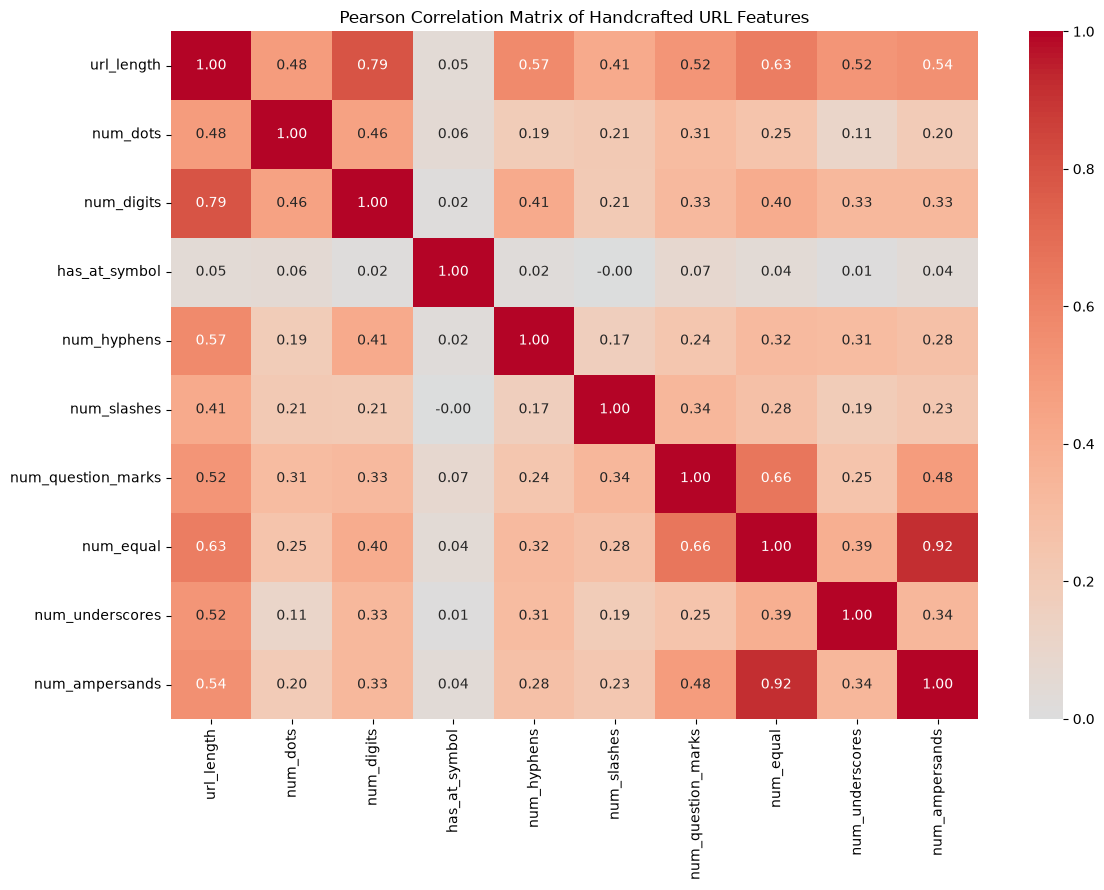

In [309]:
# ============================================================
# STAGE 1.3 — PEARSON CORRELATION ANALYSIS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

handcrafted_features = [
    "url_length",
    "num_dots",
    "num_digits",
    "has_at_symbol",
    "num_hyphens",
    "num_slashes",
    "num_question_marks",
    "num_equal",
    "num_underscores",
    "num_ampersands"
]

correlation_matrix = df[handcrafted_features].corr(method="pearson")

print("Pearson Correlation Matrix:")
display(correlation_matrix)

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Pearson Correlation Matrix of Handcrafted URL Features")
plt.tight_layout()
plt.show()

In [310]:
# ============================================================
# STAGE 1.3 — VARIANCE INFLATION FACTOR (VIF)
# ============================================================

%pip -q install statsmodels

from statsmodels.stats.outliers_influence import variance_inflation_factor

X_vif = df[handcrafted_features].copy()

vif_df = pd.DataFrame({
    "Feature": X_vif.columns,
    "VIF": [
        variance_inflation_factor(X_vif.values, i)
        for i in range(X_vif.shape[1])
    ]
})

vif_df = vif_df.sort_values(
    "VIF",
    ascending=False
).reset_index(drop=True)

display(vif_df)

vif_df.to_csv(
    "Handcrafted_Feature_VIF.csv",
    index=False
)

print("Saved: Handcrafted_Feature_VIF.csv")


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


,Feature,VIF
0,num_equal,11.228973
1,num_ampersands,7.706373
2,url_length,6.519677
3,num_digits,3.067691
4,num_question_marks,2.324005
5,num_hyphens,1.552588
6,num_underscores,1.467506
7,num_dots,1.417173
8,num_slashes,1.302270
9,has_at_symbol,1.010241


Saved: Handcrafted_Feature_VIF.csv


In [311]:
# ============================================================
# STAGE 2 — FINAL MODEL PERFORMANCE
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

y_pred_final = SV3_tuned.predict(X_test_200)
y_prob_final = SV3_tuned.predict_proba(X_test_200)[:, 1]

final_performance_df = pd.DataFrame([{
    "Accuracy": accuracy_score(y_test, y_pred_final),
    "Precision": precision_score(y_test, y_pred_final),
    "Recall": recall_score(y_test, y_pred_final),
    "F1": f1_score(y_test, y_pred_final),
    "AUC": roc_auc_score(y_test, y_prob_final)
}])

display(final_performance_df)

final_performance_df.to_csv(
    "Final_Model_Performance.csv",
    index=False
)

print("Saved: Final_Model_Performance.csv")

,Accuracy,Precision,Recall,F1,AUC
0,0.848504,0.900567,0.783517,0.837974,0.925876


Saved: Final_Model_Performance.csv


In [312]:
# ============================================================
# CROSS-DATASET ANALYSIS — COMMON HANDCRAFTED FEATURES
# ============================================================

common_handcrafted_features = [
    "url_length",
    "num_dots",
    "num_digits",
    "has_at_symbol",
    "num_hyphens",
    "num_slashes",
    "num_question_marks",
    "num_equal",
    "num_underscores",
    "num_ampersands"
]

print("Common handcrafted features:")
for feature in common_handcrafted_features:
    print("-", feature)

print("\nTotal common features:",
      len(common_handcrafted_features))

Common handcrafted features:
- url_length
- num_dots
- num_digits
- has_at_symbol
- num_hyphens
- num_slashes
- num_question_marks
- num_equal
- num_underscores
- num_ampersands

Total common features: 10


In [313]:
# ============================================================
# SAVE SHISHIR HANDCRAFTED FEATURE IMPORTANCE DATA
# ============================================================

shishir_handcrafted_df = df[
    common_handcrafted_features + ["label"]
].copy()

shishir_handcrafted_df.to_csv(
    "Shishir_Handcrafted_Features.csv",
    index=False
)

print(
    "Saved: Shishir_Handcrafted_Features.csv"
)

print(
    "Shape:",
    shishir_handcrafted_df.shape
)

Saved: Shishir_Handcrafted_Features.csv
Shape: (96018, 11)


In [314]:
# ============================================================
# SHAP — HANDCRAFTED FEATURE IMPORTANCE
# ============================================================

# Calculate mean absolute SHAP importance
# using the existing SHAP values from the original notebook.

if isinstance(shap_values, list):

    # SHAP versions that return a list:
    # [class 0 SHAP, class 1 SHAP]
    shap_positive = np.asarray(shap_values[1])

elif isinstance(shap_values, np.ndarray):

    if shap_values.ndim == 3:
        # Shape: (samples, features, classes)
        shap_positive = shap_values[:, :, 1]

    elif shap_values.ndim == 2:
        # Already a 2D SHAP matrix
        shap_positive = shap_values

    else:
        raise ValueError(
            f"Unexpected SHAP array shape: {shap_values.shape}"
        )

else:
    raise TypeError(
        f"Unexpected SHAP values type: {type(shap_values)}"
    )

mean_shap = np.abs(shap_positive).mean(axis=0)

print("SHAP matrix shape:", shap_positive.shape)
print("Number of feature importances:", len(mean_shap))
print("Number of feature names:", len(feature_names_200))


# ------------------------------------------------------------
# Extract the 10 handcrafted features
# ------------------------------------------------------------

shap_handcrafted_rows = []

for feature in common_handcrafted_features:

    matches = np.where(
        feature_names_200 == feature
    )[0]

    if len(matches) > 0:

        idx = matches[0]

        shap_handcrafted_rows.append({
            "Feature": feature,
            "Mean_Absolute_SHAP": mean_shap[idx]
        })


shap_handcrafted_df = pd.DataFrame(
    shap_handcrafted_rows
).sort_values(
    "Mean_Absolute_SHAP",
    ascending=False
).reset_index(drop=True)


# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

display(shap_handcrafted_df)


# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

shap_handcrafted_df.to_csv(
    "Shishir_SHAP_Handcrafted_Importance.csv",
    index=False
)

print(
    "Saved: Shishir_SHAP_Handcrafted_Importance.csv"
)

SHAP matrix shape: (500, 10)
Number of feature importances: 10
Number of feature names: 10


,Feature,Mean_Absolute_SHAP
0,url_length,0.129033
1,num_slashes,0.124648
2,num_digits,0.063240
3,num_equal,0.038056
4,num_hyphens,0.037783
5,num_dots,0.033969
6,num_question_marks,0.027943
7,num_underscores,0.022949
8,num_ampersands,0.006118
9,has_at_symbol,0.000575


Saved: Shishir_SHAP_Handcrafted_Importance.csv


In [315]:
# ============================================================
# SHAP — HANDCRAFTED RANKING
# ============================================================

shishir_shap_ranking = (
    shap_handcrafted_df
    .sort_values(
        "Mean_Absolute_SHAP",
        ascending=False
    )["Feature"]
    .tolist()
)

print("Shishir SHAP ranking:")
print(shishir_shap_ranking)

Shishir SHAP ranking:
['url_length', 'num_slashes', 'num_digits', 'num_equal', 'num_hyphens', 'num_dots', 'num_question_marks', 'num_underscores', 'num_ampersands', 'has_at_symbol']


In [316]:
# ============================================================
# PFI — PERMUTATION IMPORTANCE
# ============================================================

from sklearn.inspection import permutation_importance

pfi_result = permutation_importance(
    SV3_tuned,
    X_test_200,
    y_test,
    scoring="accuracy",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

print("Permutation Importance completed.")
print("Number of features:", len(pfi_result.importances_mean))

Permutation Importance completed.
Number of features: 10


In [317]:
# ============================================================
# PFI — HANDCRAFTED FEATURE IMPORTANCE
# ============================================================

pfi_handcrafted_rows = []

for feature in common_handcrafted_features:

    matches = np.where(
        feature_names_200 == feature
    )[0]

    if len(matches) > 0:

        idx = matches[0]

        pfi_handcrafted_rows.append({
            "Feature": feature,
            "Mean_Permutation_Importance":
                pfi_result.importances_mean[idx]
        })


pfi_handcrafted_df = pd.DataFrame(
    pfi_handcrafted_rows
).sort_values(
    "Mean_Permutation_Importance",
    ascending=False
).reset_index(drop=True)


# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

display(pfi_handcrafted_df)


# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

pfi_handcrafted_df.to_csv(
    "Shishir_PFI_Handcrafted_Importance.csv",
    index=False
)

print(
    "Saved: Shishir_PFI_Handcrafted_Importance.csv"
)


,Feature,Mean_Permutation_Importance
0,num_slashes,0.158019
1,url_length,0.143560
2,num_digits,0.086892
3,num_equal,0.048865
4,num_question_marks,0.037888
5,num_dots,0.036281
6,num_hyphens,0.031632
7,num_underscores,0.015254
8,num_ampersands,0.003541
9,has_at_symbol,0.001788


Saved: Shishir_PFI_Handcrafted_Importance.csv


In [318]:
# ============================================================
# PFI — HANDCRAFTED RANKING
# ============================================================

shishir_pfi_ranking = (
    pfi_handcrafted_df
    .sort_values(
        "Mean_Permutation_Importance",
        ascending=False
    )["Feature"]
    .tolist()
)

print("Shishir PFI ranking:")
print(shishir_pfi_ranking)

Shishir PFI ranking:
['num_slashes', 'url_length', 'num_digits', 'num_equal', 'num_question_marks', 'num_dots', 'num_hyphens', 'num_underscores', 'num_ampersands', 'has_at_symbol']


In [319]:
# ============================================================
# LIME STATUS CHECK — CORRECTED
# ============================================================

print("=" * 70)
print("LIME OBJECTS / RESULTS PRESENT IN CURRENT NOTEBOOK")
print("=" * 70)

lime_objects = {}

# IMPORTANT: list(...) prevents "dictionary changed size"
for name, obj in list(globals().items()):

    if "lime" in name.lower():
        lime_objects[name] = obj


if not lime_objects:

    print("\n❌ No LIME-related variable was found.")

else:

    print(f"\nFound {len(lime_objects)} LIME-related object(s):\n")

    for name, obj in lime_objects.items():

        print("-" * 70)
        print("VARIABLE :", name)
        print("TYPE     :", type(obj))

        if hasattr(obj, "shape"):
            print("SHAPE    :", obj.shape)

        if isinstance(obj, dict):

            print("DICT SIZE:", len(obj))

            if len(obj) > 0:

                first_key = next(iter(obj))
                first_value = obj[first_key]

                print("FIRST KEY:", first_key)
                print("VALUE TYPE:", type(first_value))

                if isinstance(first_value, dict):
                    print(
                        "VALUE KEYS:",
                        list(first_value.keys())
                    )

                elif isinstance(first_value, (list, tuple)):
                    print(
                        "FIRST VALUE LENGTH:",
                        len(first_value)
                    )
                    print(
                        "FIRST VALUE:",
                        first_value[:10]
                    )

        elif isinstance(obj, list):

            print("LIST SIZE:", len(obj))

            if len(obj) > 0:
                print(
                    "FIRST ELEMENT TYPE:",
                    type(obj[0])
                )
                print(
                    "FIRST ELEMENT:",
                    obj[0]
                )

        elif isinstance(obj, np.ndarray):

            print("ARRAY SHAPE:", obj.shape)

        print()


print("=" * 70)
print("IMPORTANT LIME VARIABLES")
print("=" * 70)

important_names = [
    "lime_explainer",
    "lime_explainer_cont",
    "lime_flagged_per_instance",
    "lime_flagged_per_instance_cont",
    "lime_feature_frequency",
    "lime_feature_importance",
    "lime_ranking",
    "lime_df"
]

for name in important_names:

    if name in globals():

        obj = globals()[name]

        print(f"\n✅ {name}")
        print("   Type :", type(obj))

        if hasattr(obj, "shape"):
            print("   Shape:", obj.shape)

        if isinstance(obj, dict):
            print("   Size :", len(obj))

        elif isinstance(obj, list):
            print("   Size :", len(obj))


print("\n" + "=" * 70)
print("END")
print("=" * 70)

LIME OBJECTS / RESULTS PRESENT IN CURRENT NOTEBOOK

Found 11 LIME-related object(s):

----------------------------------------------------------------------
VARIABLE : LimeTabularExplainer
TYPE     : <class 'type'>

----------------------------------------------------------------------
VARIABLE : lime_explainer
TYPE     : <class 'lime.lime_tabular.LimeTabularExplainer'>

----------------------------------------------------------------------
VARIABLE : LIME_SAMPLE_SIZE
TYPE     : <class 'int'>

----------------------------------------------------------------------
VARIABLE : lime_df
TYPE     : <class 'pandas.DataFrame'>
SHAPE    : (10, 4)

----------------------------------------------------------------------
VARIABLE : lime_top20
TYPE     : <class 'pandas.DataFrame'>
SHAPE    : (10, 4)

----------------------------------------------------------------------
VARIABLE : lime_set
TYPE     : <class 'set'>

----------------------------------------------------------------------
VARIABLE : lim

In [320]:
# ============================================================
# CHECK EXISTING LIME RANKING
# ============================================================

print("=" * 70)
print("LIME FEATURE IMPORTANCE TABLE")
print("=" * 70)

display(lime_df)

print("\n" + "=" * 70)
print("LIME RANKING TABLE")
print("=" * 70)

display(lime_rank)

print("\n" + "=" * 70)
print("LIME RANKING COLUMNS")
print("=" * 70)

print(lime_rank.columns.tolist())

print("\n" + "=" * 70)
print("LIME RANKING AS FEATURE LIST")
print("=" * 70)

# Find the feature column automatically
possible_feature_columns = [
    "Feature",
    "feature",
    "Feature_Name",
    "feature_name"
]

feature_column = None

for col in possible_feature_columns:
    if col in lime_rank.columns:
        feature_column = col
        break

if feature_column is not None:

    shishir_lime_ranking = (
        lime_rank[feature_column]
        .tolist()
    )

    print("Feature column:", feature_column)
    print()
    
    for i, feature in enumerate(
        shishir_lime_ranking,
        start=1
    ):
        print(f"{i}. {feature}")

else:

    print(
        "Could not automatically identify the feature column."
    )

LIME FEATURE IMPORTANCE TABLE


,Feature,Frequency,Total_LIME_Weight,Average_LIME_Weight
4,num_underscores,500,86.427187,0.172854
1,num_equal,500,85.023595,0.170047
0,num_hyphens,500,84.037879,0.168076
5,num_slashes,500,80.821373,0.161643
2,num_question_marks,500,69.392200,0.138784
7,url_length,500,64.883173,0.129766
3,has_at_symbol,500,57.652520,0.115305
6,num_digits,500,25.558182,0.051116
8,num_dots,500,14.241160,0.028482
9,num_ampersands,500,4.097781,0.008196



LIME RANKING TABLE


,Rank,Feature,Frequency,Total_LIME_Weight,Average_LIME_Weight
0,1,num_underscores,500,86.427187,0.172854
1,2,num_equal,500,85.023595,0.170047
2,3,num_hyphens,500,84.037879,0.168076
3,4,num_slashes,500,80.821373,0.161643
4,5,num_question_marks,500,69.392200,0.138784
5,6,url_length,500,64.883173,0.129766
6,7,has_at_symbol,500,57.652520,0.115305
7,8,num_digits,500,25.558182,0.051116
8,9,num_dots,500,14.241160,0.028482
9,10,num_ampersands,500,4.097781,0.008196



LIME RANKING COLUMNS
['Rank', 'Feature', 'Frequency', 'Total_LIME_Weight', 'Average_LIME_Weight']

LIME RANKING AS FEATURE LIST
Feature column: Feature

1. num_underscores
2. num_equal
3. num_hyphens
4. num_slashes
5. num_question_marks
6. url_length
7. has_at_symbol
8. num_digits
9. num_dots
10. num_ampersands


In [321]:
# ============================================================
# RQ1 — INTER-METHOD AGREEMENT
# SHAP vs LIME vs PFI
# ============================================================

from scipy.stats import kendalltau, spearmanr

# ------------------------------------------------------------
# Existing rankings
# ------------------------------------------------------------

shap_ranking = shishir_shap_ranking.copy()
lime_ranking = shishir_lime_ranking.copy()
pfi_ranking  = shishir_pfi_ranking.copy()


# ------------------------------------------------------------
# Verify that all methods contain the same features
# ------------------------------------------------------------

assert set(shap_ranking) == set(lime_ranking) == set(pfi_ranking), \
    "SHAP, LIME and PFI do not contain the same feature set."

print("All three methods contain the same 10 handcrafted features.")
print()


# ------------------------------------------------------------
# Convert rankings into rank dictionaries
# ------------------------------------------------------------

def ranking_to_rank_dict(ranking):
    return {
        feature: rank
        for rank, feature in enumerate(ranking, start=1)
    }


shap_rank_dict = ranking_to_rank_dict(shap_ranking)
lime_rank_dict = ranking_to_rank_dict(lime_ranking)
pfi_rank_dict  = ranking_to_rank_dict(pfi_ranking)


# Common feature order
feature_order = shap_ranking


# ------------------------------------------------------------
# Rank vectors
# ------------------------------------------------------------

shap_ranks = [
    shap_rank_dict[f]
    for f in feature_order
]

lime_ranks = [
    lime_rank_dict[f]
    for f in feature_order
]

pfi_ranks = [
    pfi_rank_dict[f]
    for f in feature_order
]


# ------------------------------------------------------------
# Kendall's Tau
# ------------------------------------------------------------

kendall_shap_lime, p_kl = kendalltau(
    shap_ranks,
    lime_ranks
)

kendall_shap_pfi, p_kp = kendalltau(
    shap_ranks,
    pfi_ranks
)

kendall_lime_pfi, p_lp = kendalltau(
    lime_ranks,
    pfi_ranks
)


# ------------------------------------------------------------
# Spearman's Rho
# ------------------------------------------------------------

spearman_shap_lime, sp_kl = spearmanr(
    shap_ranks,
    lime_ranks
)

spearman_shap_pfi, sp_kp = spearmanr(
    shap_ranks,
    pfi_ranks
)

spearman_lime_pfi, sp_lp = spearmanr(
    lime_ranks,
    pfi_ranks
)


# ------------------------------------------------------------
# Results table
# ------------------------------------------------------------

agreement_df = pd.DataFrame({

    "Comparison": [
        "SHAP vs LIME",
        "SHAP vs PFI",
        "LIME vs PFI"
    ],

    "Kendall_Tau": [
        kendall_shap_lime,
        kendall_shap_pfi,
        kendall_lime_pfi
    ],

    "Kendall_p_value": [
        p_kl,
        p_kp,
        p_lp
    ],

    "Spearman_Rho": [
        spearman_shap_lime,
        spearman_shap_pfi,
        spearman_lime_pfi
    ],

    "Spearman_p_value": [
        sp_kl,
        sp_kp,
        sp_lp
    ]
})


display(agreement_df)


# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

agreement_df.to_csv(
    "RQ1_Inter_Method_Rank_Agreement.csv",
    index=False
)

print("Saved: RQ1_Inter_Method_Rank_Agreement.csv")

All three methods contain the same 10 handcrafted features.



,Comparison,Kendall_Tau,Kendall_p_value,Spearman_Rho,Spearman_p_value
0,SHAP vs LIME,0.111111,0.727490,0.187879,0.603218
1,SHAP vs PFI,0.822222,0.000358,0.939394,0.000055
2,LIME vs PFI,0.111111,0.727490,0.163636,0.651477


Saved: RQ1_Inter_Method_Rank_Agreement.csv


In [322]:
# ============================================================
# RQ1 — TOP-K JACCARD AGREEMENT
# SHAP vs LIME vs PFI
# ============================================================

def jaccard_at_k(list1, list2, k):
    set1 = set(list1[:k])
    set2 = set(list2[:k])

    union = set1 | set2

    if len(union) == 0:
        return 0.0

    return len(set1 & set2) / len(union)


# ------------------------------------------------------------
# Calculate Jaccard agreement at K = 3, 5, 10
# ------------------------------------------------------------

jaccard_rows = []

for k in [3, 5, 10]:

    jaccard_rows.append({
        "K": k,

        "SHAP_vs_LIME": jaccard_at_k(
            shap_ranking,
            lime_ranking,
            k
        ),

        "SHAP_vs_PFI": jaccard_at_k(
            shap_ranking,
            pfi_ranking,
            k
        ),

        "LIME_vs_PFI": jaccard_at_k(
            lime_ranking,
            pfi_ranking,
            k
        )
    })


jaccard_df = pd.DataFrame(jaccard_rows)

display(jaccard_df)


# ------------------------------------------------------------
# Feature-level support across all three methods
# ------------------------------------------------------------

feature_support_rows = []

for feature in feature_order:

    shap_rank = shap_rank_dict[feature]
    lime_rank = lime_rank_dict[feature]
    pfi_rank = pfi_rank_dict[feature]

    # Number of methods placing feature in their top 3
    top3_count = sum([
        shap_rank <= 3,
        lime_rank <= 3,
        pfi_rank <= 3
    ])

    # Number of methods placing feature in their top 5
    top5_count = sum([
        shap_rank <= 5,
        lime_rank <= 5,
        pfi_rank <= 5
    ])

    # Number of methods placing feature in their top 10
    top10_count = sum([
        shap_rank <= 10,
        lime_rank <= 10,
        pfi_rank <= 10
    ])

    feature_support_rows.append({
        "Feature": feature,
        "SHAP_Rank": shap_rank,
        "LIME_Rank": lime_rank,
        "PFI_Rank": pfi_rank,
        "Top3_Method_Count": top3_count,
        "Top5_Method_Count": top5_count,
        "Top10_Method_Count": top10_count
    })


feature_support_df = pd.DataFrame(
    feature_support_rows
)

# Sort by strongest overall support
feature_support_df = feature_support_df.sort_values(
    by=[
        "Top3_Method_Count",
        "Top5_Method_Count",
        "Top10_Method_Count"
    ],
    ascending=False
).reset_index(drop=True)


print()
print("=" * 70)
print("FEATURE-LEVEL AGREEMENT")
print("=" * 70)

display(feature_support_df)


# ------------------------------------------------------------
# Save results
# ------------------------------------------------------------

jaccard_df.to_csv(
    "RQ1_TopK_Jaccard_Agreement.csv",
    index=False
)

feature_support_df.to_csv(
    "RQ1_Feature_Level_Agreement.csv",
    index=False
)

print("Saved: RQ1_TopK_Jaccard_Agreement.csv")
print("Saved: RQ1_Feature_Level_Agreement.csv")

,K,SHAP_vs_LIME,SHAP_vs_PFI,LIME_vs_PFI
0,3,0.000000,1.000000,0.000000
1,5,0.428571,0.666667,0.428571
2,10,1.000000,1.000000,1.000000



FEATURE-LEVEL AGREEMENT


,Feature,SHAP_Rank,LIME_Rank,PFI_Rank,Top3_Method_Count,Top5_Method_Count,Top10_Method_Count
0,num_slashes,2,4,1,2,3,3
1,url_length,1,6,2,2,2,3
2,num_digits,3,8,3,2,2,3
3,num_equal,4,2,4,1,3,3
4,num_hyphens,5,3,7,1,2,3
5,num_underscores,8,1,8,1,1,3
6,num_question_marks,7,5,5,0,2,3
7,num_dots,6,9,6,0,0,3
8,num_ampersands,9,10,9,0,0,3
9,has_at_symbol,10,7,10,0,0,3


Saved: RQ1_TopK_Jaccard_Agreement.csv
Saved: RQ1_Feature_Level_Agreement.csv


In [323]:
# ============================================================
# RQ1 — CONSENSUS FEATURE SET
# Predefined agreement rule:
# Top-5 in at least 2 of 3 methods
# ============================================================

CONSENSUS_K = 5
CONSENSUS_MIN_METHODS = 2

print("=" * 70)
print("RQ1 — CONSENSUS FEATURE SET")
print("=" * 70)

print(
    f"Consensus rule: Top-{CONSENSUS_K} "
    f"in at least {CONSENSUS_MIN_METHODS} of 3 methods"
)

print()


# ------------------------------------------------------------
# Calculate consensus support
# ------------------------------------------------------------

consensus_rows = []

for feature in feature_order:

    shap_topk = shap_rank_dict[feature] <= CONSENSUS_K
    lime_topk = lime_rank_dict[feature] <= CONSENSUS_K
    pfi_topk  = pfi_rank_dict[feature] <= CONSENSUS_K

    method_count = sum([
        shap_topk,
        lime_topk,
        pfi_topk
    ])

    consensus_rows.append({
        "Feature": feature,
        "SHAP_Rank": shap_rank_dict[feature],
        "LIME_Rank": lime_rank_dict[feature],
        "PFI_Rank": pfi_rank_dict[feature],
        "Methods_in_Top5": method_count,
        "SHAP_Top5": shap_topk,
        "LIME_Top5": lime_topk,
        "PFI_Top5": pfi_topk,
        "Consensus": method_count >= CONSENSUS_MIN_METHODS
    })


consensus_df = pd.DataFrame(consensus_rows)


# ------------------------------------------------------------
# Sort by agreement strength
# ------------------------------------------------------------

consensus_df = consensus_df.sort_values(
    by=[
        "Consensus",
        "Methods_in_Top5"
    ],
    ascending=[False, False]
).reset_index(drop=True)


display(consensus_df)


# ------------------------------------------------------------
# Extract consensus feature set
# ------------------------------------------------------------

consensus_features = (
    consensus_df[
        consensus_df["Consensus"] == True
    ]["Feature"]
    .tolist()
)


print()
print("=" * 70)
print("CONSENSUS FEATURES")
print("=" * 70)

for i, feature in enumerate(
    consensus_features,
    start=1
):
    print(f"{i}. {feature}")


print()
print(
    "Total consensus features:",
    len(consensus_features)
)


# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

consensus_df.to_csv(
    "RQ1_Consensus_Feature_Support.csv",
    index=False
)

pd.DataFrame({
    "Consensus_Feature": consensus_features
}).to_csv(
    "RQ1_Consensus_Features.csv",
    index=False
)

print()
print("Saved: RQ1_Consensus_Feature_Support.csv")
print("Saved: RQ1_Consensus_Features.csv")

RQ1 — CONSENSUS FEATURE SET
Consensus rule: Top-5 in at least 2 of 3 methods



,Feature,SHAP_Rank,LIME_Rank,PFI_Rank,Methods_in_Top5,SHAP_Top5,LIME_Top5,PFI_Top5,Consensus
0,num_slashes,2,4,1,3,True,True,True,True
1,num_equal,4,2,4,3,True,True,True,True
2,url_length,1,6,2,2,True,False,True,True
3,num_digits,3,8,3,2,True,False,True,True
4,num_hyphens,5,3,7,2,True,True,False,True
5,num_question_marks,7,5,5,2,False,True,True,True
6,num_underscores,8,1,8,1,False,True,False,False
7,num_dots,6,9,6,0,False,False,False,False
8,num_ampersands,9,10,9,0,False,False,False,False
9,has_at_symbol,10,7,10,0,False,False,False,False



CONSENSUS FEATURES
1. num_slashes
2. num_equal
3. url_length
4. num_digits
5. num_hyphens
6. num_question_marks

Total consensus features: 6

Saved: RQ1_Consensus_Feature_Support.csv
Saved: RQ1_Consensus_Features.csv


In [324]:
# ============================================================
# RQ1 — DIRECTION / CLASS EFFECT
# Consensus Features
# ============================================================

print("=" * 70)
print("RQ1 — DIRECTION / CLASS EFFECT")
print("=" * 70)


# ------------------------------------------------------------
# Use the SHAP values already computed
# ------------------------------------------------------------

# shap_positive was created in the previous SHAP cell.
# Shape:
# (samples, features)

direction_rows = []


# ------------------------------------------------------------
# Analyze each consensus feature
# ------------------------------------------------------------

for feature in consensus_features:

    matches = np.where(
        feature_names_200 == feature
    )[0]

    if len(matches) == 0:
        continue

    idx = matches[0]

    values = shap_positive[:, idx]

    mean_signed = np.mean(values)
    median_signed = np.median(values)

    positive_percentage = (
        np.mean(values > 0) * 100
    )

    negative_percentage = (
        np.mean(values < 0) * 100
    )

    zero_percentage = (
        np.mean(values == 0) * 100
    )

    # For class-1 SHAP:
    # Positive -> pushes toward class 1 (Phishing)
    # Negative -> pushes toward class 0 (Benign)

    if mean_signed > 0:
        dominant_direction = "Phishing"
    elif mean_signed < 0:
        dominant_direction = "Benign"
    else:
        dominant_direction = "Neutral"


    direction_rows.append({

        "Feature": feature,

        "Mean_Signed_SHAP":
            mean_signed,

        "Median_Signed_SHAP":
            median_signed,

        "Positive_SHAP_%":
            positive_percentage,

        "Negative_SHAP_%":
            negative_percentage,

        "Zero_SHAP_%":
            zero_percentage,

        "Dominant_Direction":
            dominant_direction
    })


direction_df = pd.DataFrame(
    direction_rows
)


# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

display(direction_df)


# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

direction_df.to_csv(
    "RQ1_Consensus_Feature_Direction.csv",
    index=False
)

print(
    "Saved: RQ1_Consensus_Feature_Direction.csv"
)

RQ1 — DIRECTION / CLASS EFFECT


,Feature,Mean_Signed_SHAP,Median_Signed_SHAP,Positive_SHAP_%,Negative_SHAP_%,Zero_SHAP_%,Dominant_Direction
0,num_slashes,-0.001982,-0.050933,32.2,67.8,0.0,Benign
1,num_equal,-0.012379,-0.029708,15.4,84.6,0.0,Benign
2,url_length,-0.000103,-0.054790,36.8,63.2,0.0,Benign
3,num_digits,0.003973,-0.016147,44.2,55.8,0.0,Phishing
4,num_hyphens,-0.005105,-0.021036,31.4,68.6,0.0,Benign
5,num_question_marks,-0.009615,-0.017218,15.0,84.4,0.6,Benign


Saved: RQ1_Consensus_Feature_Direction.csv


In [325]:
# ============================================================
# CHECK EXISTING DiCE RESULTS
# ============================================================

print("=" * 70)
print("CHECKING EXISTING DiCE RESULTS")
print("=" * 70)

dice_vars = [
    "verification_df",
    "majority_features",
    "preliminary_consensus_features",
    "top_k_for_dice",
    "dice_flip_frequency"
]

for var in dice_vars:
    if var in globals():
        obj = globals()[var]

        try:
            print(f"{var}: EXISTS | type={type(obj).__name__} | shape={obj.shape}")
        except:
            try:
                print(f"{var}: EXISTS | type={type(obj).__name__} | length={len(obj)}")
            except:
                print(f"{var}: EXISTS | type={type(obj).__name__}")
    else:
        print(f"{var}: NOT FOUND")

CHECKING EXISTING DiCE RESULTS
verification_df: NOT FOUND
majority_features: NOT FOUND
preliminary_consensus_features: NOT FOUND
top_k_for_dice: EXISTS | type=list | length=10
dice_flip_frequency: NOT FOUND


In [326]:
from collections import defaultdict
import pandas as pd

dice_feature_frequency = defaultdict(int)
dice_feature_weight = defaultdict(float)
dice_flagged_per_instance = {}

for idx, cf in cf_results.items():

    orig_row = X_test_df.loc[idx]

    cf_df = cf.cf_examples_list[0].final_cfs_df

    if cf_df is None or len(cf_df) == 0:
        continue

    instance_flipped = set()

    for _, cf_row in cf_df.iterrows():

        for f in top_k_for_dice:

            diff = abs(orig_row[f] - cf_row[f])

            if diff > 1e-6:
                dice_feature_frequency[f] += 1
                dice_feature_weight[f] += diff
                instance_flipped.add(f)

    dice_flagged_per_instance[idx] = instance_flipped

print("Processed:", len(dice_flagged_per_instance), "instances")

Processed: 150 instances


In [327]:
# ============================================================
# DiCE FEATURE IMPORTANCE TABLE
# ============================================================

dice_table_final = pd.DataFrame({
    "feature": list(dice_feature_frequency.keys()),
    "frequency": list(dice_feature_frequency.values()),
    "total_weight": [
        dice_feature_weight[f]
        for f in dice_feature_frequency.keys()
    ]
}).sort_values(
    "frequency",
    ascending=False
).reset_index(drop=True)

display(dice_table_final.head(20))

dice_table_final.to_csv(
    "DICE_Feature_Table.csv",
    index=False
)

print("Saved: DICE_Feature_Table.csv")

,feature,frequency,total_weight
0,num_slashes,345,949.0
1,url_length,205,6772.0
2,num_digits,164,1645.0
3,num_dots,138,315.0
4,num_hyphens,134,364.0
5,num_underscores,61,221.0
6,num_question_marks,31,36.0
7,num_equal,27,54.0
8,num_ampersands,11,16.0
9,has_at_symbol,1,1.0


Saved: DICE_Feature_Table.csv


In [328]:
# ============================================================
# DiCE VERIFICATION OF RQ1 CONSENSUS FEATURES
# ============================================================

print("=" * 70)
print("DiCE VERIFICATION — RQ1 CONSENSUS FEATURES")
print("=" * 70)

verification_rows = []

for feature in consensus_features:

    dice_frequency = dice_feature_frequency.get(feature, 0)
    dice_weight = dice_feature_weight.get(feature, 0.0)

    in_dice_scope = feature in top_k_for_dice

    verification_rows.append({
        "Feature": feature,
        "DiCE_Frequency": dice_frequency,
        "DiCE_Total_Weight": dice_weight,
        "In_DiCE_Scope": in_dice_scope,
        "DiCE_Corroborated": dice_frequency > 0
    })

verification_df = pd.DataFrame(verification_rows)

display(verification_df)

verification_df.to_csv(
    "RQ1_Consensus_DiCE_Verification.csv",
    index=False
)

print()
print(
    "DiCE-corroborated:",
    verification_df["DiCE_Corroborated"].sum(),
    "/",
    len(verification_df)
)

print("Saved: RQ1_Consensus_DiCE_Verification.csv")

DiCE VERIFICATION — RQ1 CONSENSUS FEATURES


,Feature,DiCE_Frequency,DiCE_Total_Weight,In_DiCE_Scope,DiCE_Corroborated
0,num_slashes,345,949.0,True,True
1,num_equal,27,54.0,True,True
2,url_length,205,6772.0,True,True
3,num_digits,164,1645.0,True,True
4,num_hyphens,134,364.0,True,True
5,num_question_marks,31,36.0,True,True



DiCE-corroborated: 6 / 6
Saved: RQ1_Consensus_DiCE_Verification.csv


In [329]:
# ============================================================
# FINAL RQ1 CONSENSUS FEATURES
# ============================================================

print("=" * 70)
print("FINAL RQ1 CONSENSUS FEATURES")
print("=" * 70)

# Start with the existing feature-level agreement table
final_rq1_df = feature_support_df[
    feature_support_df["Feature"].isin(consensus_features)
].copy()

# Add SHAP direction information
direction_merge = direction_df[
    [
        "Feature",
        "Mean_Signed_SHAP",
        "Median_Signed_SHAP",
        "Positive_SHAP_%",
        "Negative_SHAP_%",
        "Dominant_Direction"
    ]
].copy()

final_rq1_df = final_rq1_df.merge(
    direction_merge,
    on="Feature",
    how="left"
)

# Add DiCE verification information
dice_merge = verification_df[
    [
        "Feature",
        "DiCE_Frequency",
        "DiCE_Total_Weight",
        "DiCE_Corroborated"
    ]
].copy()

final_rq1_df = final_rq1_df.merge(
    dice_merge,
    on="Feature",
    how="left"
)

# Sort by number of methods supporting the feature,
# then by average rank
final_rq1_df = final_rq1_df.sort_values(
    by=["Top5_Count", "Feature"],
    ascending=[False, True]
).reset_index(drop=True)

display(final_rq1_df)

final_rq1_df.to_csv(
    "Final_RQ1_Consensus_Features.csv",
    index=False
)

print()
print("Final consensus features:", len(final_rq1_df))
print(
    "DiCE-corroborated:",
    final_rq1_df["DiCE_Corroborated"].sum(),
    "/",
    len(final_rq1_df)
)

print("Saved: Final_RQ1_Consensus_Features.csv")

FINAL RQ1 CONSENSUS FEATURES


KeyError: 'Top5_Count'

In [ ]:
print("feature_support_df columns:")
print(feature_support_df.columns.tolist())

print("\nfinal_rq1_df columns:")
print(final_rq1_df.columns.tolist())

In [330]:
# ============================================================
# FINAL RQ1 CONSENSUS FEATURES
# ============================================================

print("=" * 70)
print("FINAL RQ1 CONSENSUS FEATURES")
print("=" * 70)

# Start with the existing feature-level agreement table
final_rq1_df = feature_support_df[
    feature_support_df["Feature"].isin(consensus_features)
].copy()

# Add SHAP direction information
direction_merge = direction_df[
    [
        "Feature",
        "Mean_Signed_SHAP",
        "Median_Signed_SHAP",
        "Positive_SHAP_%",
        "Negative_SHAP_%",
        "Dominant_Direction"
    ]
].copy()

final_rq1_df = final_rq1_df.merge(
    direction_merge,
    on="Feature",
    how="left"
)

# Add DiCE verification information
dice_merge = verification_df[
    [
        "Feature",
        "DiCE_Frequency",
        "DiCE_Total_Weight",
        "DiCE_Corroborated"
    ]
].copy()

final_rq1_df = final_rq1_df.merge(
    dice_merge,
    on="Feature",
    how="left"
)

# Sort by Top-5 support, then feature name
final_rq1_df = final_rq1_df.sort_values(
    by=["Top5_Method_Count", "Feature"],
    ascending=[False, True]
).reset_index(drop=True)

display(final_rq1_df)

final_rq1_df.to_csv(
    "Final_RQ1_Consensus_Features.csv",
    index=False
)

print()
print("Final consensus features:", len(final_rq1_df))
print(
    "DiCE-corroborated:",
    final_rq1_df["DiCE_Corroborated"].sum(),
    "/",
    len(final_rq1_df)
)

print("Saved: Final_RQ1_Consensus_Features.csv")

FINAL RQ1 CONSENSUS FEATURES


,Feature,SHAP_Rank,LIME_Rank,PFI_Rank,Top3_Method_Count,Top5_Method_Count,Top10_Method_Count,Mean_Signed_SHAP,Median_Signed_SHAP,Positive_SHAP_%,Negative_SHAP_%,Dominant_Direction,DiCE_Frequency,DiCE_Total_Weight,DiCE_Corroborated
0,num_equal,4,2,4,1,3,3,-0.012379,-0.029708,15.4,84.6,Benign,27,54.0,True
1,num_slashes,2,4,1,2,3,3,-0.001982,-0.050933,32.2,67.8,Benign,345,949.0,True
2,num_digits,3,8,3,2,2,3,0.003973,-0.016147,44.2,55.8,Phishing,164,1645.0,True
3,num_hyphens,5,3,7,1,2,3,-0.005105,-0.021036,31.4,68.6,Benign,134,364.0,True
4,num_question_marks,7,5,5,0,2,3,-0.009615,-0.017218,15.0,84.4,Benign,31,36.0,True
5,url_length,1,6,2,2,2,3,-0.000103,-0.054790,36.8,63.2,Benign,205,6772.0,True



Final consensus features: 6
DiCE-corroborated: 6 / 6
Saved: Final_RQ1_Consensus_Features.csv


In [331]:
# ============================================================
# CHECK EXISTING RQ2 / FAITHFULNESS RESULTS
# ============================================================

print("=" * 70)
print("CHECKING EXISTING FAITHFULNESS / ABLATION RESULTS")
print("=" * 70)

faithfulness_vars = [
    "deletion_auc",
    "insertion_auc",
    "deletion_scores",
    "insertion_scores",
    "ablation_results",
    "ablation_df",
    "faithfulness_results",
    "faithfulness_df",
    "deletion_results",
    "insertion_results",
    "xai_ablation_results"
]

for var in faithfulness_vars:
    if var in globals():
        obj = globals()[var]

        try:
            print(
                f"{var}: EXISTS | "
                f"type={type(obj).__name__} | "
                f"shape={obj.shape}"
            )
        except:
            try:
                print(
                    f"{var}: EXISTS | "
                    f"type={type(obj).__name__} | "
                    f"length={len(obj)}"
                )
            except:
                print(
                    f"{var}: EXISTS | "
                    f"type={type(obj).__name__}"
                )
    else:
        print(f"{var}: NOT FOUND")

CHECKING EXISTING FAITHFULNESS / ABLATION RESULTS
deletion_auc: NOT FOUND
insertion_auc: NOT FOUND
deletion_scores: NOT FOUND
insertion_scores: NOT FOUND
ablation_results: NOT FOUND
ablation_df: NOT FOUND
faithfulness_results: NOT FOUND
faithfulness_df: NOT FOUND
deletion_results: NOT FOUND
insertion_results: NOT FOUND
xai_ablation_results: NOT FOUND


In [332]:
# ============================================================
# RQ2 — BEHAVIORAL FAITHFULNESS
# BASELINE MODEL / DATA CHECK
# ============================================================

print("=" * 70)
print("RQ2 — BASELINE CHECK")
print("=" * 70)

check_vars = [
    "SV3_tuned",
    "X_test_200",
    "y_test",
    "feature_names_200",
    "shap_positive",
    "shap_values",
    "X_test_dense",
    "consensus_features"
]

for var in check_vars:

    if var in globals():

        obj = globals()[var]

        try:
            print(
                f"{var}: EXISTS | "
                f"type={type(obj).__name__} | "
                f"shape={obj.shape}"
            )
        except:

            try:
                print(
                    f"{var}: EXISTS | "
                    f"type={type(obj).__name__} | "
                    f"length={len(obj)}"
                )

            except:

                print(
                    f"{var}: EXISTS | "
                    f"type={type(obj).__name__}"
                )

    else:
        print(f"{var}: NOT FOUND")

RQ2 — BASELINE CHECK
SV3_tuned: EXISTS | type=VotingClassifier
X_test_200: EXISTS | type=ndarray | shape=(28806, 10)
y_test: EXISTS | type=Series | shape=(28806,)
feature_names_200: EXISTS | type=ndarray | shape=(10,)
shap_positive: EXISTS | type=ndarray | shape=(500, 10)
shap_values: EXISTS | type=ndarray | shape=(500, 10, 2)
X_test_dense: EXISTS | type=ndarray | shape=(28806, 10)
consensus_features: EXISTS | type=list | length=6


In [333]:
# ============================================================
# RQ2 — BASELINE PREDICTIONS
# Corrected class-index handling
# ============================================================

print("=" * 70)
print("RQ2 — BASELINE PREDICTIONS")
print("=" * 70)

# Convert labels explicitly to integer class indices
y_test_array = np.asarray(y_test).astype(int)

# Full test-set predictions
baseline_proba = SV3_tuned.predict_proba(X_test_200)

# Probability assigned to the true class
true_class_probability = baseline_proba[
    np.arange(len(y_test_array)),
    y_test_array
]

# Predicted class
baseline_predictions = SV3_tuned.predict(X_test_200)

baseline_accuracy = accuracy_score(
    y_test_array,
    baseline_predictions
)

print("Test instances:", len(X_test_200))
print("Prediction matrix shape:", baseline_proba.shape)
print(f"Baseline accuracy: {baseline_accuracy:.6f}")
print(
    f"Mean true-class probability: "
    f"{true_class_probability.mean():.6f}"
)

print()
print("Baseline predictions created successfully.")

RQ2 — BASELINE PREDICTIONS
Test instances: 28806
Prediction matrix shape: (28806, 2)
Baseline accuracy: 0.848504
Mean true-class probability: 0.781339

Baseline predictions created successfully.


In [334]:
# ============================================================
# RQ2 — CHECK EXISTING XAI RANKING VARIABLES
# ============================================================

check_vars = [
    "shap_rank",
    "shap_positive",
    "shap_values",
    "feature_names_200",
    "lime_rank",
    "pfi_rank"
]

for var in check_vars:
    if var in globals():
        obj = globals()[var]
        print(
            f"{var:20s} -> "
            f"type={type(obj).__name__}, "
            f"shape={getattr(obj, 'shape', 'N/A')}"
        )
    else:
        print(f"{var:20s} -> NOT FOUND")

shap_rank            -> type=int, shape=N/A
shap_positive        -> type=ndarray, shape=(500, 10)
shap_values          -> type=ndarray, shape=(500, 10, 2)
feature_names_200    -> type=ndarray, shape=(10,)
lime_rank            -> type=int, shape=N/A
pfi_rank             -> type=int, shape=N/A


In [335]:
# ============================================================
# RQ2 — FIND EXISTING XAI RANKING DATA
# Corrected diagnostic
# ============================================================

print("=" * 70)
print("POSSIBLE XAI RANKING VARIABLES")
print("=" * 70)

keywords = [
    "lime",
    "pfi",
    "permutation",
    "rank",
    "frequency",
    "importance",
    "shap"
]

# Take a snapshot so globals() cannot change during iteration
existing_vars = list(globals().items())

for name, obj in existing_vars:

    name_lower = name.lower()

    if any(k in name_lower for k in keywords):

        if isinstance(
            obj,
            (pd.DataFrame, pd.Series, np.ndarray, list, dict)
        ):
            print(
                f"{name:40s} | "
                f"type={type(obj).__name__:12s} | "
                f"shape={getattr(obj, 'shape', 'N/A')}"
            )

POSSIBLE XAI RANKING VARIABLES
feature_frequency                        | type=defaultdict  | shape=N/A
importance_df                            | type=DataFrame    | shape=(10, 5)
shap_values                              | type=ndarray      | shape=(500, 10, 2)
mean_abs_shap                            | type=ndarray      | shape=(10,)
shap_importance                          | type=Series       | shape=(10,)
shap_top20                               | type=DataFrame    | shape=(10, 2)
lime_df                                  | type=DataFrame    | shape=(10, 4)
lime_top20                               | type=DataFrame    | shape=(10, 4)
dice_feature_frequency                   | type=defaultdict  | shape=N/A
lime_flagged_per_instance                | type=dict         | shape=N/A
lime_flagged_restricted                  | type=dict         | shape=N/A
shap_flagged_per_instance                | type=dict         | shape=N/A
local_agreement_shap_dice                | type=DataFrame    | s

In [336]:
# ============================================================
# RQ2 — BEHAVIORAL FAITHFULNESS
# EXISTING XAI FEATURE RANKINGS
# ============================================================

print("=" * 70)
print("RQ2 — XAI FEATURE RANKINGS")
print("=" * 70)

# Use the rankings already generated in the original notebook
shap_order = list(shap_ranking)
lime_order = list(lime_ranking)
pfi_order = list(pfi_ranking)

# Verify that all three rankings contain the same 10 features
print("\nSHAP ranking:")
for i, feature in enumerate(shap_order, 1):
    print(f"{i:2d}. {feature}")

print("\nLIME ranking:")
for i, feature in enumerate(lime_order, 1):
    print(f"{i:2d}. {feature}")

print("\nPFI ranking:")
for i, feature in enumerate(pfi_order, 1):
    print(f"{i:2d}. {feature}")

print("\nFeature counts:")
print("SHAP:", len(shap_order))
print("LIME:", len(lime_order))
print("PFI :", len(pfi_order))

print("\nRanking preparation complete.")

RQ2 — XAI FEATURE RANKINGS

SHAP ranking:
 1. url_length
 2. num_slashes
 3. num_digits
 4. num_equal
 5. num_hyphens
 6. num_dots
 7. num_question_marks
 8. num_underscores
 9. num_ampersands
10. has_at_symbol

LIME ranking:
 1. num_underscores
 2. num_equal
 3. num_hyphens
 4. num_slashes
 5. num_question_marks
 6. url_length
 7. has_at_symbol
 8. num_digits
 9. num_dots
10. num_ampersands

PFI ranking:
 1. num_slashes
 2. url_length
 3. num_digits
 4. num_equal
 5. num_question_marks
 6. num_dots
 7. num_hyphens
 8. num_underscores
 9. num_ampersands
10. has_at_symbol

Feature counts:
SHAP: 10
LIME: 10
PFI : 10

Ranking preparation complete.


In [337]:
# ============================================================
# RQ2 — BEHAVIORAL FAITHFULNESS
# MAP XAI RANKINGS TO FEATURE INDICES
# ============================================================

print("=" * 70)
print("RQ2 — FEATURE INDEX MAPPING")
print("=" * 70)

# Convert feature names to a simple list
feature_names_list = list(feature_names_200)

# Create feature -> column index mapping
feature_to_index = {
    feature: idx
    for idx, feature in enumerate(feature_names_list)
}

# Convert each XAI ranking from feature names to column indices
shap_indices = [
    feature_to_index[f]
    for f in shap_order
]

lime_indices = [
    feature_to_index[f]
    for f in lime_order
]

pfi_indices = [
    feature_to_index[f]
    for f in pfi_order
]

print("\nFeature names:")
for i, feature in enumerate(feature_names_list):
    print(f"{i:2d} -> {feature}")

print("\nSHAP indices:")
print(shap_indices)

print("\nLIME indices:")
print(lime_indices)

print("\nPFI indices:")
print(pfi_indices)

print("\nFeature-index mapping completed successfully.")

RQ2 — FEATURE INDEX MAPPING

Feature names:
 0 -> url_length
 1 -> num_dots
 2 -> num_digits
 3 -> has_at_symbol
 4 -> num_hyphens
 5 -> num_slashes
 6 -> num_question_marks
 7 -> num_equal
 8 -> num_underscores
 9 -> num_ampersands

SHAP indices:
[0, 5, 2, 7, 4, 1, 6, 8, 9, 3]

LIME indices:
[8, 7, 4, 5, 6, 0, 3, 2, 1, 9]

PFI indices:
[5, 0, 2, 7, 6, 1, 4, 8, 9, 3]

Feature-index mapping completed successfully.


In [338]:
# ============================================================
# RQ2 — BEHAVIORAL FAITHFULNESS
# SHAP-GUIDED DELETION / INSERTION
# ============================================================

print("=" * 70)
print("RQ2 — SHAP-GUIDED DELETION / INSERTION")
print("=" * 70)

# ------------------------------------------------------------
# Original test data
# ------------------------------------------------------------

X_original = np.asarray(X_test_200).copy()

n_samples = X_original.shape[0]
n_features = X_original.shape[1]

# ------------------------------------------------------------
# Storage
# ------------------------------------------------------------

shap_deletion_scores = []
shap_insertion_scores = []

# ------------------------------------------------------------
# DELETION
#
# Remove the most important features progressively.
# Removed features are replaced with zero.
# Measure mean true-class probability.
# ------------------------------------------------------------

for k in range(n_features + 1):

    X_deleted = X_original.copy()

    if k > 0:
        deleted_indices = shap_indices[:k]
        X_deleted[:, deleted_indices] = 0

    probabilities = SV3_tuned.predict_proba(X_deleted)

    true_class_prob = probabilities[
        np.arange(n_samples),
        y_test_array
    ]

    shap_deletion_scores.append(
        true_class_prob.mean()
    )

# ------------------------------------------------------------
# INSERTION
#
# Start with all features removed.
# Add the most important features progressively.
# Measure mean true-class probability.
# ------------------------------------------------------------

for k in range(n_features + 1):

    X_inserted = np.zeros_like(X_original)

    if k > 0:
        inserted_indices = shap_indices[:k]
        X_inserted[:, inserted_indices] = (
            X_original[:, inserted_indices]
        )

    probabilities = SV3_tuned.predict_proba(X_inserted)

    true_class_prob = probabilities[
        np.arange(n_samples),
        y_test_array
    ]

    shap_insertion_scores.append(
        true_class_prob.mean()
    )

# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

shap_faithfulness_df = pd.DataFrame({
    "Features_Changed": np.arange(n_features + 1),
    "Deletion_Mean_True_Class_Probability":
        shap_deletion_scores,
    "Insertion_Mean_True_Class_Probability":
        shap_insertion_scores
})

print("\nSHAP faithfulness results:")
print(shap_faithfulness_df.to_string(index=False))

print("\nSHAP deletion/insertion evaluation completed.")

RQ2 — SHAP-GUIDED DELETION / INSERTION

SHAP faithfulness results:
 Features_Changed  Deletion_Mean_True_Class_Probability  Insertion_Mean_True_Class_Probability
                0                              0.781339                               0.500000
                1                              0.628091                               0.497202
                2                              0.490883                               0.687762
                3                              0.499149                               0.722681
                4                              0.500160                               0.726066
                5                              0.497961                               0.732380
                6                              0.495049                               0.764478
                7                              0.496522                               0.771371
                8                              0.496533                       

In [339]:
# ============================================================
# RQ2 — SHAP DELETION / INSERTION AUC
# ============================================================

print("=" * 70)
print("RQ2 — SHAP DELETION / INSERTION AUC")
print("=" * 70)

# ------------------------------------------------------------
# Normalize feature steps to [0, 1]
# ------------------------------------------------------------

x_steps = (
    shap_faithfulness_df["Features_Changed"].to_numpy()
    / n_features
)

deletion_curve = (
    shap_faithfulness_df[
        "Deletion_Mean_True_Class_Probability"
    ].to_numpy()
)

insertion_curve = (
    shap_faithfulness_df[
        "Insertion_Mean_True_Class_Probability"
    ].to_numpy()
)

# ------------------------------------------------------------
# Trapezoidal AUC
# ------------------------------------------------------------

shap_deletion_auc = np.trapezoid(
    deletion_curve,
    x_steps
)

shap_insertion_auc = np.trapezoid(
    insertion_curve,
    x_steps
)

# ------------------------------------------------------------
# Accuracy at each perturbation level
# ------------------------------------------------------------

shap_deletion_accuracy = []
shap_insertion_accuracy = []

for k in range(n_features + 1):

    # -------------------------
    # Deletion
    # -------------------------

    X_deleted = X_original.copy()

    if k > 0:
        X_deleted[:, shap_indices[:k]] = 0

    deleted_pred = SV3_tuned.predict(X_deleted)

    shap_deletion_accuracy.append(
        accuracy_score(y_test_array, deleted_pred)
    )

    # -------------------------
    # Insertion
    # -------------------------

    X_inserted = np.zeros_like(X_original)

    if k > 0:
        X_inserted[:, shap_indices[:k]] = (
            X_original[:, shap_indices[:k]]
        )

    inserted_pred = SV3_tuned.predict(X_inserted)

    shap_insertion_accuracy.append(
        accuracy_score(y_test_array, inserted_pred)
    )

# ------------------------------------------------------------
# Add accuracy to results table
# ------------------------------------------------------------

shap_faithfulness_df[
    "Deletion_Accuracy"
] = shap_deletion_accuracy

shap_faithfulness_df[
    "Insertion_Accuracy"
] = shap_insertion_accuracy

# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

print(f"SHAP Deletion AUC : {shap_deletion_auc:.6f}")
print(f"SHAP Insertion AUC: {shap_insertion_auc:.6f}")

print("\nFaithfulness results with accuracy:")
print(
    shap_faithfulness_df.to_string(index=False)
)

print("\nSHAP AUC calculation completed.")


RQ2 — SHAP DELETION / INSERTION AUC
SHAP Deletion AUC : 0.524502
SHAP Insertion AUC: 0.710300

Faithfulness results with accuracy:
 Features_Changed  Deletion_Mean_True_Class_Probability  Insertion_Mean_True_Class_Probability  Deletion_Accuracy  Insertion_Accuracy
                0                              0.781339                               0.500000           0.848504            0.500000
                1                              0.628091                               0.497202           0.712664            0.500000
                2                              0.490883                               0.687762           0.500417            0.759460
                3                              0.499149                               0.722681           0.500000            0.784107
                4                              0.500160                               0.726066           0.500000            0.786225
                5                              0.497961          

In [340]:
# ============================================================
# RQ2 — BEHAVIORAL FAITHFULNESS
# LIME-GUIDED DELETION / INSERTION
# ============================================================

print("=" * 70)
print("RQ2 — LIME-GUIDED DELETION / INSERTION")
print("=" * 70)

# ------------------------------------------------------------
# Original test data
# ------------------------------------------------------------

X_original = np.asarray(X_test_200).copy()

n_samples = X_original.shape[0]
n_features = X_original.shape[1]

# ------------------------------------------------------------
# Storage
# ------------------------------------------------------------

lime_deletion_scores = []
lime_insertion_scores = []

# ------------------------------------------------------------
# DELETION
# ------------------------------------------------------------

for k in range(n_features + 1):

    X_deleted = X_original.copy()

    if k > 0:
        deleted_indices = lime_indices[:k]
        X_deleted[:, deleted_indices] = 0

    probabilities = SV3_tuned.predict_proba(X_deleted)

    true_class_prob = probabilities[
        np.arange(n_samples),
        y_test_array
    ]

    lime_deletion_scores.append(
        true_class_prob.mean()
    )

# ------------------------------------------------------------
# INSERTION
# ------------------------------------------------------------

for k in range(n_features + 1):

    X_inserted = np.zeros_like(X_original)

    if k > 0:
        inserted_indices = lime_indices[:k]
        X_inserted[:, inserted_indices] = (
            X_original[:, inserted_indices]
        )

    probabilities = SV3_tuned.predict_proba(X_inserted)

    true_class_prob = probabilities[
        np.arange(n_samples),
        y_test_array
    ]

    lime_insertion_scores.append(
        true_class_prob.mean()
    )

# ------------------------------------------------------------
# Create results table
# ------------------------------------------------------------

lime_faithfulness_df = pd.DataFrame({
    "Features_Changed": np.arange(n_features + 1),
    "Deletion_Mean_True_Class_Probability":
        lime_deletion_scores,
    "Insertion_Mean_True_Class_Probability":
        lime_insertion_scores
})

print("\nLIME faithfulness results:")
print(
    lime_faithfulness_df.to_string(index=False)
)

print("\nLIME deletion/insertion evaluation completed.")

RQ2 — LIME-GUIDED DELETION / INSERTION

LIME faithfulness results:
 Features_Changed  Deletion_Mean_True_Class_Probability  Insertion_Mean_True_Class_Probability
                0                              0.781339                               0.500000
                1                              0.772505                               0.499076
                2                              0.760674                               0.493575
                3                              0.746236                               0.494517
                4                              0.499883                               0.673099
                5                              0.499593                               0.689121
                6                              0.497494                               0.700800
                7                              0.497496                               0.701621
                8                              0.496353                       

In [341]:
# ============================================================
# RQ2 — LIME DELETION / INSERTION AUC
# ============================================================

print("=" * 70)
print("RQ2 — LIME DELETION / INSERTION AUC")
print("=" * 70)

# ------------------------------------------------------------
# Normalize feature steps to [0, 1]
# ------------------------------------------------------------

x_steps = (
    lime_faithfulness_df["Features_Changed"].to_numpy()
    / n_features
)

deletion_curve = (
    lime_faithfulness_df[
        "Deletion_Mean_True_Class_Probability"
    ].to_numpy()
)

insertion_curve = (
    lime_faithfulness_df[
        "Insertion_Mean_True_Class_Probability"
    ].to_numpy()
)

# ------------------------------------------------------------
# Trapezoidal AUC
# ------------------------------------------------------------

lime_deletion_auc = np.trapezoid(
    deletion_curve,
    x_steps
)

lime_insertion_auc = np.trapezoid(
    insertion_curve,
    x_steps
)

# ------------------------------------------------------------
# Accuracy at every perturbation level
# ------------------------------------------------------------

lime_deletion_accuracy = []
lime_insertion_accuracy = []

for k in range(n_features + 1):

    # -------------------------
    # Deletion
    # -------------------------

    X_deleted = X_original.copy()

    if k > 0:
        X_deleted[:, lime_indices[:k]] = 0

    deleted_pred = SV3_tuned.predict(X_deleted)

    lime_deletion_accuracy.append(
        accuracy_score(
            y_test_array,
            deleted_pred
        )
    )

    # -------------------------
    # Insertion
    # -------------------------

    X_inserted = np.zeros_like(X_original)

    if k > 0:
        X_inserted[:, lime_indices[:k]] = (
            X_original[:, lime_indices[:k]]
        )

    inserted_pred = SV3_tuned.predict(X_inserted)

    lime_insertion_accuracy.append(
        accuracy_score(
            y_test_array,
            inserted_pred
        )
    )

# ------------------------------------------------------------
# Add accuracy to results table
# ------------------------------------------------------------

lime_faithfulness_df[
    "Deletion_Accuracy"
] = lime_deletion_accuracy

lime_faithfulness_df[
    "Insertion_Accuracy"
] = lime_insertion_accuracy

# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

print(f"LIME Deletion AUC : {lime_deletion_auc:.6f}")
print(f"LIME Insertion AUC: {lime_insertion_auc:.6f}")

print("\nFaithfulness results with accuracy:")
print(
    lime_faithfulness_df.to_string(index=False)
)

print("\nLIME AUC calculation completed.")

RQ2 — LIME DELETION / INSERTION AUC
LIME Deletion AUC : 0.590743
LIME Insertion AUC: 0.640909

Faithfulness results with accuracy:
 Features_Changed  Deletion_Mean_True_Class_Probability  Insertion_Mean_True_Class_Probability  Deletion_Accuracy  Insertion_Accuracy
                0                              0.781339                               0.500000           0.848504            0.500000
                1                              0.772505                               0.499076           0.841526            0.500000
                2                              0.760674                               0.493575           0.830834            0.500000
                3                              0.746236                               0.494517           0.809970            0.500000
                4                              0.499883                               0.673099           0.500000            0.722384
                5                              0.499593          

In [342]:
# ============================================================
# RQ2 — BEHAVIORAL FAITHFULNESS
# PFI-GUIDED DELETION / INSERTION
# ============================================================

print("=" * 70)
print("RQ2 — PFI-GUIDED DELETION / INSERTION")
print("=" * 70)

# ------------------------------------------------------------
# Original test data
# ------------------------------------------------------------

X_original = np.asarray(X_test_200).copy()

n_samples = X_original.shape[0]
n_features = X_original.shape[1]

# ------------------------------------------------------------
# Storage
# ------------------------------------------------------------

pfi_deletion_scores = []
pfi_insertion_scores = []

# ------------------------------------------------------------
# DELETION
# ------------------------------------------------------------

for k in range(n_features + 1):

    X_deleted = X_original.copy()

    if k > 0:
        deleted_indices = pfi_indices[:k]
        X_deleted[:, deleted_indices] = 0

    probabilities = SV3_tuned.predict_proba(X_deleted)

    true_class_prob = probabilities[
        np.arange(n_samples),
        y_test_array
    ]

    pfi_deletion_scores.append(
        true_class_prob.mean()
    )

# ------------------------------------------------------------
# INSERTION
# ------------------------------------------------------------

for k in range(n_features + 1):

    X_inserted = np.zeros_like(X_original)

    if k > 0:
        inserted_indices = pfi_indices[:k]
        X_inserted[:, inserted_indices] = (
            X_original[:, inserted_indices]
        )

    probabilities = SV3_tuned.predict_proba(X_inserted)

    true_class_prob = probabilities[
        np.arange(n_samples),
        y_test_array
    ]

    pfi_insertion_scores.append(
        true_class_prob.mean()
    )

# ------------------------------------------------------------
# Create results table
# ------------------------------------------------------------

pfi_faithfulness_df = pd.DataFrame({
    "Features_Changed": np.arange(n_features + 1),
    "Deletion_Mean_True_Class_Probability":
        pfi_deletion_scores,
    "Insertion_Mean_True_Class_Probability":
        pfi_insertion_scores
})

print("\nPFI faithfulness results:")
print(
    pfi_faithfulness_df.to_string(index=False)
)

print("\nPFI deletion/insertion evaluation completed.")

RQ2 — PFI-GUIDED DELETION / INSERTION

PFI faithfulness results:
 Features_Changed  Deletion_Mean_True_Class_Probability  Insertion_Mean_True_Class_Probability
                0                              0.781339                               0.500000
                1                              0.517125                               0.614679
                2                              0.490883                               0.687762
                3                              0.499149                               0.722681
                4                              0.500160                               0.726066
                5                              0.499521                               0.723848
                6                              0.495258                               0.756699
                7                              0.496522                               0.771371
                8                              0.496533                         

In [343]:
# ============================================================
# RQ2 — PFI DELETION / INSERTION AUC
# ============================================================

print("=" * 70)
print("RQ2 — PFI DELETION / INSERTION AUC")
print("=" * 70)

# ------------------------------------------------------------
# Normalize feature steps to [0, 1]
# ------------------------------------------------------------

x_steps = (
    pfi_faithfulness_df["Features_Changed"].to_numpy()
    / n_features
)

deletion_curve = (
    pfi_faithfulness_df[
        "Deletion_Mean_True_Class_Probability"
    ].to_numpy()
)

insertion_curve = (
    pfi_faithfulness_df[
        "Insertion_Mean_True_Class_Probability"
    ].to_numpy()
)

# ------------------------------------------------------------
# Trapezoidal AUC
# ------------------------------------------------------------

pfi_deletion_auc = np.trapezoid(
    deletion_curve,
    x_steps
)

pfi_insertion_auc = np.trapezoid(
    insertion_curve,
    x_steps
)

# ------------------------------------------------------------
# Accuracy at every perturbation level
# ------------------------------------------------------------

pfi_deletion_accuracy = []
pfi_insertion_accuracy = []

for k in range(n_features + 1):

    # -------------------------
    # Deletion
    # -------------------------

    X_deleted = X_original.copy()

    if k > 0:
        X_deleted[:, pfi_indices[:k]] = 0

    deleted_pred = SV3_tuned.predict(X_deleted)

    pfi_deletion_accuracy.append(
        accuracy_score(
            y_test_array,
            deleted_pred
        )
    )

    # -------------------------
    # Insertion
    # -------------------------

    X_inserted = np.zeros_like(X_original)

    if k > 0:
        X_inserted[:, pfi_indices[:k]] = (
            X_original[:, pfi_indices[:k]]
        )

    inserted_pred = SV3_tuned.predict(X_inserted)

    pfi_insertion_accuracy.append(
        accuracy_score(
            y_test_array,
            inserted_pred
        )
    )

# ------------------------------------------------------------
# Add accuracy to results table
# ------------------------------------------------------------

pfi_faithfulness_df[
    "Deletion_Accuracy"
] = pfi_deletion_accuracy

pfi_faithfulness_df[
    "Insertion_Accuracy"
] = pfi_insertion_accuracy

# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

print(f"PFI Deletion AUC : {pfi_deletion_auc:.6f}")
print(f"PFI Insertion AUC: {pfi_insertion_auc:.6f}")

print("\nFaithfulness results with accuracy:")
print(
    pfi_faithfulness_df.to_string(index=False)
)

print("\nPFI AUC calculation completed.")

RQ2 — PFI DELETION / INSERTION AUC
PFI Deletion AUC : 0.513582
PFI Insertion AUC: 0.720417

Faithfulness results with accuracy:
 Features_Changed  Deletion_Mean_True_Class_Probability  Insertion_Mean_True_Class_Probability  Deletion_Accuracy  Insertion_Accuracy
                0                              0.781339                               0.500000           0.848504            0.500000
                1                              0.517125                               0.614679           0.511560            0.635770
                2                              0.490883                               0.687762           0.500417            0.759460
                3                              0.499149                               0.722681           0.500000            0.784107
                4                              0.500160                               0.726066           0.500000            0.786225
                5                              0.499521             

In [344]:
# ============================================================
# RQ2 — FAITHFULNESS SUMMARY
# SHAP + LIME + PFI
# ============================================================

print("=" * 70)
print("RQ2 — FAITHFULNESS SUMMARY")
print("=" * 70)

rq2_faithfulness_summary = pd.DataFrame({
    "XAI_Method": [
        "SHAP",
        "LIME",
        "PFI"
    ],
    "Deletion_AUC": [
        shap_deletion_auc,
        lime_deletion_auc,
        pfi_deletion_auc
    ],
    "Insertion_AUC": [
        shap_insertion_auc,
        lime_insertion_auc,
        pfi_insertion_auc
    ],
    "Baseline_Accuracy": [
        baseline_accuracy,
        baseline_accuracy,
        baseline_accuracy
    ],
    "Test_Instances": [
        n_samples,
        n_samples,
        n_samples
    ]
})

print(
    rq2_faithfulness_summary.to_string(index=False)
)

# Save for later RQ2 consolidation
rq2_faithfulness_summary.to_csv(
    "RQ2_Faithfulness_Summary.csv",
    index=False
)

print("\nSaved:")
print("RQ2_Faithfulness_Summary.csv")

RQ2 — FAITHFULNESS SUMMARY
XAI_Method  Deletion_AUC  Insertion_AUC  Baseline_Accuracy  Test_Instances
      SHAP      0.524502       0.710300           0.848504           28806
      LIME      0.590743       0.640909           0.848504           28806
       PFI      0.513582       0.720417           0.848504           28806

Saved:
RQ2_Faithfulness_Summary.csv


In [345]:
# ============================================================
# RQ2 — CONTROLLED 10-FEATURE ABLATION
# SETUP CHECK
# ============================================================

print("=" * 70)
print("RQ2 — CONTROLLED 10-FEATURE ABLATION")
print("=" * 70)

print("Training data shape :", X_train_200.shape)
print("Test data shape     :", X_test_200.shape)
print("Number of features  :", len(feature_names_200))

print("\nFeatures:")
for i, feature in enumerate(feature_names_200):
    print(f"{i:2d}. {feature}")

print("\nCurrent model:")
print(type(SV3_tuned).__name__)

print("\nCurrent baseline accuracy:")
print(f"{baseline_accuracy:.6f}")

print("\nControlled ablation setup check completed.")

RQ2 — CONTROLLED 10-FEATURE ABLATION
Training data shape : (67212, 10)
Test data shape     : (28806, 10)
Number of features  : 10

Features:
 0. url_length
 1. num_dots
 2. num_digits
 3. has_at_symbol
 4. num_hyphens
 5. num_slashes
 6. num_question_marks
 7. num_equal
 8. num_underscores
 9. num_ampersands

Current model:
VotingClassifier

Current baseline accuracy:
0.848504

Controlled ablation setup check completed.


In [346]:
# ============================================================
# RQ2 — CONTROLLED 10-FEATURE ABLATION
# INSPECT SV3_TUNED CONFIGURATION
# ============================================================

print("=" * 70)
print("RQ2 — SV3_TUNED CONFIGURATION")
print("=" * 70)

print("\nModel type:")
print(type(SV3_tuned).__name__)

print("\nVoting method:")
print(SV3_tuned.voting)

print("\nEstimators:")
for name, estimator in SV3_tuned.estimators:
    print(f"\n{name}:")
    print(estimator)

print("\nSV3_tuned configuration inspection completed.")

RQ2 — SV3_TUNED CONFIGURATION

Model type:
VotingClassifier

Voting method:
soft

Estimators:

rf:
RandomForestClassifier(max_depth=20, min_samples_split=5, n_estimators=200,
                       random_state=42)

mlp:
MLPClassifier(hidden_layer_sizes=(100, 50), max_iter=300, random_state=42)

xgb:
XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=5, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None

In [347]:
# ============================================================
# RQ2 — CONTROLLED 10-FEATURE ABLATION
# FULL 10-FEATURE REFERENCE MODEL
# ============================================================

print("=" * 70)
print("RQ2 — FULL 10-FEATURE REFERENCE MODEL")
print("=" * 70)

from sklearn.ensemble import VotingClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier

# ------------------------------------------------------------
# Create models using the same configuration as SV3_tuned
# ------------------------------------------------------------

rf_ablation_ref = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    min_samples_split=5,
    random_state=42
)

mlp_ablation_ref = MLPClassifier(
    hidden_layer_sizes=(100, 50),
    max_iter=300,
    random_state=42
)

xgb_ablation_ref = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.1,
    eval_metric="logloss",
    random_state=42,
    enable_categorical=True
)

# ------------------------------------------------------------
# Soft Voting Classifier
# ------------------------------------------------------------

sv3_ablation_ref = VotingClassifier(
    estimators=[
        ("rf", rf_ablation_ref),
        ("mlp", mlp_ablation_ref),
        ("xgb", xgb_ablation_ref)
    ],
    voting="soft"
)

# ------------------------------------------------------------
# Train on all 10 handcrafted features
# ------------------------------------------------------------

sv3_ablation_ref.fit(
    X_train_200,
    y_train
)

# ------------------------------------------------------------
# Evaluate
# ------------------------------------------------------------

ablation_ref_predictions = sv3_ablation_ref.predict(
    X_test_200
)

ablation_ref_accuracy = accuracy_score(
    y_test_array,
    ablation_ref_predictions
)

print("\nReference model trained successfully.")
print("Training shape:", X_train_200.shape)
print("Test shape:", X_test_200.shape)
print(f"Reference accuracy: {ablation_ref_accuracy:.6f}")

print("\nControlled 10-feature reference model completed.")

RQ2 — FULL 10-FEATURE REFERENCE MODEL

Reference model trained successfully.
Training shape: (67212, 10)
Test shape: (28806, 10)
Reference accuracy: 0.848504

Controlled 10-feature reference model completed.


In [348]:
# ============================================================
# RQ2 — CONTROLLED 10-FEATURE ABLATION
# CONSENSUS-FEATURE ABLATION
# ============================================================

print("=" * 70)
print("RQ2 — CONSENSUS FEATURE ABLATION")
print("=" * 70)

# ------------------------------------------------------------
# Consensus features from RQ1
# ------------------------------------------------------------

print("\nConsensus features:")
for feature in consensus_features:
    print("-", feature)

# ------------------------------------------------------------
# Store results
# ------------------------------------------------------------

ablation_results = []

# ------------------------------------------------------------
# Train one model per consensus feature removed
# ------------------------------------------------------------

for feature_to_remove in consensus_features:

    print(f"\nAblating: {feature_to_remove}")

    # Find feature column
    feature_idx = feature_to_index[feature_to_remove]

    # Keep every feature except the selected one
    keep_indices = [
        i for i in range(n_features)
        if i != feature_idx
    ]

    X_train_ablation = X_train_200[:, keep_indices]
    X_test_ablation = X_test_200[:, keep_indices]

    # --------------------------------------------------------
    # Same SV3_tuned configuration
    # --------------------------------------------------------

    rf_model = RandomForestClassifier(
        n_estimators=200,
        max_depth=20,
        min_samples_split=5,
        random_state=42
    )

    mlp_model = MLPClassifier(
        hidden_layer_sizes=(100, 50),
        max_iter=300,
        random_state=42
    )

    xgb_model = XGBClassifier(
        n_estimators=200,
        max_depth=5,
        learning_rate=0.1,
        eval_metric="logloss",
        random_state=42,
        enable_categorical=True
    )

    ablation_model = VotingClassifier(
        estimators=[
            ("rf", rf_model),
            ("mlp", mlp_model),
            ("xgb", xgb_model)
        ],
        voting="soft"
    )

    # Train
    ablation_model.fit(
        X_train_ablation,
        y_train
    )

    # Predict
    predictions = ablation_model.predict(
        X_test_ablation
    )

    # Metrics
    accuracy = accuracy_score(
        y_test_array,
        predictions
    )

    precision = precision_score(
        y_test_array,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        y_test_array,
        predictions,
        zero_division=0
    )

    f1 = f1_score(
        y_test_array,
        predictions,
        zero_division=0
    )

    mcc = matthews_corrcoef(
        y_test_array,
        predictions
    )

    # Store
    ablation_results.append({
        "Ablated_Feature": feature_to_remove,
        "Remaining_Features": len(keep_indices),
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "MCC": mcc,
        "Accuracy_Drop": (
            ablation_ref_accuracy - accuracy
        )
    })

    print(
        f"Accuracy: {accuracy:.6f} | "
        f"Drop: {ablation_ref_accuracy - accuracy:.6f}"
    )

# ------------------------------------------------------------
# Results table
# ------------------------------------------------------------

ablation_df = pd.DataFrame(ablation_results)

print("\n" + "=" * 70)
print("CONSENSUS-FEATURE ABLATION RESULTS")
print("=" * 70)

print(
    ablation_df.to_string(index=False)
)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

ablation_df.to_csv(
    "RQ2_Consensus_Feature_Ablation.csv",
    index=False
)

print("\nSaved:")
print("RQ2_Consensus_Feature_Ablation.csv")

RQ2 — CONSENSUS FEATURE ABLATION

Consensus features:
- num_slashes
- num_equal
- url_length
- num_digits
- num_hyphens
- num_question_marks

Ablating: num_slashes
Accuracy: 0.810456 | Drop: 0.038048

Ablating: num_equal
Accuracy: 0.846560 | Drop: 0.001944

Ablating: url_length
Accuracy: 0.823648 | Drop: 0.024856

Ablating: num_digits
Accuracy: 0.826425 | Drop: 0.022079

Ablating: num_hyphens
Accuracy: 0.836631 | Drop: 0.011873

Ablating: num_question_marks
Accuracy: 0.847185 | Drop: 0.001319

CONSENSUS-FEATURE ABLATION RESULTS
   Ablated_Feature  Remaining_Features  Accuracy  Precision   Recall       F1      MCC  Accuracy_Drop
       num_slashes                   9  0.810456   0.895883 0.702562 0.787532 0.635894       0.038048
         num_equal                   9  0.846560   0.904137 0.775325 0.834791 0.700263       0.001944
        url_length                   9  0.823648   0.831331 0.812053 0.821579 0.647470       0.024856
        num_digits                   9  0.826425   0.88445

In [349]:
# ============================================================
# RQ2 — DiCE EFFECTIVENESS
# INSPECT EXISTING RESULTS
# ============================================================

print("=" * 70)
print("RQ2 — DiCE EFFECTIVENESS")
print("=" * 70)

print("Number of DiCE instances:", len(cf_results))

print("\nAvailable DiCE-related variables:")

for name in [
    "cf_results",
    "dice_flagged_per_instance",
    "dice_feature_frequency",
    "dice_feature_weight",
    "dice_table_final",
    "top_k_for_dice",
    "consensus_features"
]:
    if name in globals():
        obj = globals()[name]
        print(
            f"{name:30s} -> "
            f"type={type(obj).__name__}, "
            f"shape={getattr(obj, 'shape', 'N/A')}"
        )
    else:
        print(f"{name:30s} -> NOT FOUND")

print("\nDiCE structure check completed.")

RQ2 — DiCE EFFECTIVENESS
Number of DiCE instances: 150

Available DiCE-related variables:
cf_results                     -> type=dict, shape=N/A
dice_flagged_per_instance      -> type=dict, shape=N/A
dice_feature_frequency         -> type=defaultdict, shape=N/A
dice_feature_weight            -> type=defaultdict, shape=N/A
dice_table_final               -> type=DataFrame, shape=(10, 3)
top_k_for_dice                 -> type=list, shape=N/A
consensus_features             -> type=list, shape=N/A

DiCE structure check completed.


In [350]:
# ============================================================
# RQ2 — DiCE EFFECTIVENESS
# INSPECT ONE EXISTING COUNTERFACTUAL
# ============================================================

print("=" * 70)
print("RQ2 — DICE COUNTERFACTUAL STRUCTURE")
print("=" * 70)

# Take the first available DiCE instance
first_idx = next(iter(cf_results))

cf_entry = cf_results[first_idx]

print("Example test index:", first_idx)
print("Entry type:", type(cf_entry).__name__)

print("\nEntry attributes:")
print([
    attr for attr in dir(cf_entry)
    if not attr.startswith("_")
])

# ------------------------------------------------------------
# Inspect the DiCE example object
# ------------------------------------------------------------

if hasattr(cf_entry, "cf_examples_list"):

    print(
        "\nNumber of cf_examples objects:",
        len(cf_entry.cf_examples_list)
    )

    example = cf_entry.cf_examples_list[0]

    print("\nCounterfactual object type:")
    print(type(example).__name__)

    print("\nAvailable attributes:")
    print([
        attr for attr in dir(example)
        if not attr.startswith("_")
    ])

    print("\nFinal counterfactual dataframe:")
    print(example.final_cfs_df)

print("\nDiCE structure inspection completed.")

RQ2 — DICE COUNTERFACTUAL STRUCTURE
Example test index: 6011
Entry type: CounterfactualExplanations

Entry attributes:
['cf_examples_list', 'from_json', 'local_importance', 'metadata', 'summary_importance', 'to_json', 'visualize_as_dataframe', 'visualize_as_list']

Number of cf_examples objects: 1

Counterfactual object type:
CounterfactualExamples

Available attributes:
['data_interface', 'desired_class', 'desired_range', 'display_df', 'final_cfs_df', 'final_cfs_df_sparse', 'final_cfs_list', 'from_json', 'model_type', 'new_outcome', 'posthoc_sparsity_param', 'print_list', 'test_instance_df', 'test_pred', 'to_json', 'visualize_as_dataframe', 'visualize_as_list']

Final counterfactual dataframe:
   url_length  num_dots  num_digits  has_at_symbol  num_hyphens  num_slashes  \
0          44         3           0              0            0            2   
0          44         3           1              0            0            3   
0          44         2           1              0      

In [351]:
# ============================================================
# RQ2 — DiCE EFFECTIVENESS
# COUNTERFACTUAL SUCCESS RATE
# ============================================================

print("=" * 70)
print("RQ2 — DiCE COUNTERFACTUAL EFFECTIVENESS")
print("=" * 70)

dice_effectiveness_rows = []

for idx, cf_result in cf_results.items():

    # --------------------------------------------------------
    # Get DiCE explanation object
    # --------------------------------------------------------

    if (
        not hasattr(cf_result, "cf_examples_list")
        or len(cf_result.cf_examples_list) == 0
    ):
        continue

    cf_example = cf_result.cf_examples_list[0]

    # --------------------------------------------------------
    # Original prediction
    # --------------------------------------------------------

    original_prediction = int(
        np.asarray(cf_example.test_pred).flatten()[0]
    )

    # --------------------------------------------------------
    # Counterfactual dataframe
    # --------------------------------------------------------

    cf_df = cf_example.final_cfs_df

    if cf_df is None or len(cf_df) == 0:
        dice_effectiveness_rows.append({
            "Test_Index": idx,
            "Original_Prediction": original_prediction,
            "Number_of_Counterfactuals": 0,
            "Successful_Counterfactuals": 0,
            "Success_Rate": 0.0
        })
        continue

    # --------------------------------------------------------
    # Determine feature columns
    # --------------------------------------------------------

    feature_columns = list(feature_names_200)

    X_cf = cf_df[feature_columns].to_numpy()

    # --------------------------------------------------------
    # Re-evaluate counterfactuals with the model
    # --------------------------------------------------------

    cf_predictions = SV3_tuned.predict(X_cf)

    # --------------------------------------------------------
    # Desired class
    # --------------------------------------------------------

    desired_class = getattr(
        cf_example,
        "desired_class",
        None
    )

    if desired_class is not None:
        desired_class = int(
            np.asarray(desired_class).flatten()[0]
        )

        successful = (
            cf_predictions == desired_class
        )

    else:
        # If desired class is not explicitly stored,
        # success means the prediction differs from
        # the original prediction.
        successful = (
            cf_predictions != original_prediction
        )

    successful_count = int(
        np.sum(successful)
    )

    total_counterfactuals = len(cf_predictions)

    success_rate = (
        successful_count / total_counterfactuals
        if total_counterfactuals > 0
        else 0.0
    )

    dice_effectiveness_rows.append({
        "Test_Index": idx,
        "Original_Prediction": original_prediction,
        "Number_of_Counterfactuals": total_counterfactuals,
        "Successful_Counterfactuals": successful_count,
        "Success_Rate": success_rate
    })

# ------------------------------------------------------------
# Create results table
# ------------------------------------------------------------

dice_effectiveness_df = pd.DataFrame(
    dice_effectiveness_rows
)

# ------------------------------------------------------------
# Overall effectiveness
# ------------------------------------------------------------

total_counterfactuals = (
    dice_effectiveness_df[
        "Number_of_Counterfactuals"
    ].sum()
)

total_successful = (
    dice_effectiveness_df[
        "Successful_Counterfactuals"
    ].sum()
)

overall_dice_success_rate = (
    total_successful / total_counterfactuals
    if total_counterfactuals > 0
    else 0.0
)

instance_success_rate = (
    (
        dice_effectiveness_df[
            "Successful_Counterfactuals"
        ] > 0
    ).mean()
)

print("\nInstances evaluated:",
      len(dice_effectiveness_df))

print("Total counterfactuals:",
      total_counterfactuals)

print("Successful counterfactuals:",
      total_successful)

print(
    f"\nCounterfactual success rate: "
    f"{overall_dice_success_rate:.6f}"
)

print(
    f"Instance-level success rate: "
    f"{instance_success_rate:.6f}"
)

print("\nDiCE effectiveness evaluation completed.")

RQ2 — DiCE COUNTERFACTUAL EFFECTIVENESS

Instances evaluated: 150
Total counterfactuals: 447
Successful counterfactuals: 447

Counterfactual success rate: 1.000000
Instance-level success rate: 1.000000

DiCE effectiveness evaluation completed.


In [352]:
# ============================================================
# RQ2 — DICE EFFECTIVENESS SUMMARY
# ============================================================

rq2_dice_summary = pd.DataFrame({
    "Metric": [
        "Instances Evaluated",
        "Total Counterfactuals",
        "Successful Counterfactuals",
        "Counterfactual Success Rate",
        "Instance-Level Success Rate"
    ],
    "Value": [
        len(dice_effectiveness_df),
        total_counterfactuals,
        total_successful,
        overall_dice_success_rate,
        instance_success_rate
    ]
})

print(rq2_dice_summary.to_string(index=False))

rq2_dice_summary.to_csv(
    "RQ2_DiCE_Effectiveness_Summary.csv",
    index=False
)

print("\nSaved:")
print("RQ2_DiCE_Effectiveness_Summary.csv")

                     Metric  Value
        Instances Evaluated  150.0
      Total Counterfactuals  447.0
 Successful Counterfactuals  447.0
Counterfactual Success Rate    1.0
Instance-Level Success Rate    1.0

Saved:
RQ2_DiCE_Effectiveness_Summary.csv


In [353]:
# ============================================================
# RQ3 — STABILITY & CROSS-DATASET CONSISTENCY
# SETUP CHECK
# ============================================================

print("=" * 70)
print("RQ3 — SETUP CHECK")
print("=" * 70)

check_vars = [
    "cross_dataset_rank_df",
    "cross_dataset_results",
    "original_ranking",
    "original_rankings",
    "eashan_ranking",
    "eashan_rankings",
    "shap_ranking",
    "lime_ranking",
    "pfi_ranking",
    "ranking_sets",
    "ranking_df",
    "master_rank",
    "local_agreement_shap_perm",
    "local_agreement_shap_dice",
    "global_agreement_score",
    "local_agreement_score",
    "trust_score",
    "sensitivity_rows_v2"
]

for var in check_vars:
    if var in globals():
        obj = globals()[var]
        print(
            f"{var:35s} -> "
            f"type={type(obj).__name__:20s} | "
            f"shape={getattr(obj, 'shape', 'N/A')}"
        )
    else:
        print(f"{var:35s} -> NOT FOUND")

print("\nRQ3 setup inspection completed.")

RQ3 — SETUP CHECK
cross_dataset_rank_df               -> type=DataFrame            | shape=(4, 6)
cross_dataset_results               -> NOT FOUND
original_ranking                    -> type=dict                 | shape=N/A
original_rankings                   -> type=dict                 | shape=N/A
eashan_ranking                      -> type=dict                 | shape=N/A
eashan_rankings                     -> type=dict                 | shape=N/A
shap_ranking                        -> type=list                 | shape=N/A
lime_ranking                        -> type=list                 | shape=N/A
pfi_ranking                         -> type=list                 | shape=N/A
ranking_sets                        -> type=dict                 | shape=N/A
ranking_df                          -> type=DataFrame            | shape=(10, 4)
master_rank                         -> type=DataFrame            | shape=(10, 5)
local_agreement_shap_perm           -> type=DataFrame            | shape=(1

In [354]:
# ============================================================
# RQ3 — CROSS-DATASET CONSISTENCY
# INSPECT EXISTING RESULTS
# ============================================================

print("=" * 70)
print("RQ3 — EXISTING CROSS-DATASET RANKING RESULTS")
print("=" * 70)

print("\nColumns:")
print(cross_dataset_rank_df.columns.tolist())

print("\nShape:")
print(cross_dataset_rank_df.shape)

print("\nExisting cross-dataset ranking table:")
print(
    cross_dataset_rank_df.to_string(index=False)
)

print("\nExisting ranking dictionaries:")

print("\noriginal_ranking:")
print(original_ranking)

print("\neashan_ranking:")
print(eashan_ranking)

print("\noriginal_rankings:")
print(original_rankings)

print("\neashan_rankings:")
print(eashan_rankings)

print("\nCross-dataset inspection completed.")

RQ3 — EXISTING CROSS-DATASET RANKING RESULTS

Columns:
['Method', 'Features', 'Spearman_Rho', 'Spearman_P', 'Kendall_Tau', 'Kendall_P']

Shape:
(4, 6)

Existing cross-dataset ranking table:
     Method  Features  Spearman_Rho  Spearman_P  Kendall_Tau  Kendall_P
       LIME        10     -0.733333    0.015801    -0.511111   0.046623
 SHAP_Local        10     -0.139394    0.700932    -0.022222   1.000000
SHAP_Global        10      0.563636    0.089724     0.377778   0.155742
         PI        10      0.490909    0.149656     0.377778   0.155742

Existing ranking dictionaries:

original_ranking:
{'url_length': 7, 'num_dots': 1, 'num_hyphens': 9, 'num_underscores': 8, 'has_at_symbol': 2, 'num_question_marks': 6, 'num_digits': 4, 'num_slashes': 10, 'num_equal': 5, 'num_ampersands': 3}

eashan_ranking:
{'url_length': 7, 'num_hyphens': 9, 'num_ampersands': 3, 'num_dots': 1, 'num_underscores': 8, 'has_at_symbol': 2, 'num_question_marks': 6, 'num_digits': 4, 'num_slashes': 10, 'num_equal': 5}


In [355]:
# ============================================================
# RQ3 — STABILITY
# INSPECT EXISTING AGREEMENT / STABILITY RESULTS
# ============================================================

print("=" * 70)
print("RQ3 — EXISTING STABILITY / AGREEMENT RESULTS")
print("=" * 70)

check_vars = [
    "local_agreement_shap_perm",
    "local_agreement_shap_dice",
    "ranking_df",
    "master_rank",
    "ranking_sets",
    "shap_global_rank",
    "shap_local_rank",
    "pi_rank",
    "lime_df",
    "lime_top20",
    "shap_importance",
    "mean_abs_shap"
]

for var in check_vars:

    if var in globals():

        obj = globals()[var]

        print("\n" + "-" * 70)
        print(f"{var}")
        print("Type:", type(obj).__name__)
        print("Shape:", getattr(obj, "shape", "N/A"))

        if isinstance(obj, pd.DataFrame):
            print("Columns:", obj.columns.tolist())
            print(obj.head())

        elif isinstance(obj, pd.Series):
            print(obj.head())

        elif isinstance(obj, dict):
            print("Keys:", list(obj.keys())[:10])

    else:
        print(f"\n{var}: NOT FOUND")

print("\nRQ3 stability inspection completed.")

RQ3 — EXISTING STABILITY / AGREEMENT RESULTS

----------------------------------------------------------------------
local_agreement_shap_perm
Type: DataFrame
Shape: (150, 3)
Columns: ['idx', 'label', 'jaccard']
     idx  label   jaccard
0   6011    1.0  0.666667
1  26324    1.0  0.666667
2  18149    1.0  0.666667
3   2141    1.0  0.666667
4  12462    0.0  0.666667

----------------------------------------------------------------------
local_agreement_shap_dice
Type: DataFrame
Shape: (150, 3)
Columns: ['idx', 'label', 'jaccard']
     idx  label   jaccard
0   6011    1.0  0.600000
1  26324    1.0  0.428571
2  18149    1.0  0.166667
3   2141    1.0  0.714286
4  12462    0.0  0.400000

----------------------------------------------------------------------
ranking_df
Type: DataFrame
Shape: (10, 4)
Columns: ['Rank', 'Feature', 'Permutation_Importance', 'Permutation_STD']
   Rank             Feature  Permutation_Importance  Permutation_STD
0     1     num_underscores                0.158019 

In [356]:
# ============================================================
# RQ3 — STABILITY ANALYSIS
# DATA / MODEL READINESS CHECK
# ============================================================

print("=" * 70)
print("RQ3 — STABILITY DATA / MODEL READINESS")
print("=" * 70)

check_vars = [
    "SV3_tuned",
    "X_train_200",
    "X_test_200",
    "X_train_dense",
    "X_test_dense",
    "y_train",
    "y_test",
    "feature_names_200",
    "shap_ranking",
    "lime_ranking",
    "pfi_ranking"
]

for var in check_vars:
    if var in globals():
        obj = globals()[var]

        print(
            f"{var:25s} -> "
            f"type={type(obj).__name__:20s} | "
            f"shape={getattr(obj, 'shape', 'N/A')}"
        )

        if var == "feature_names_200":
            print("   Features:", list(obj))

        elif var in ["shap_ranking", "lime_ranking", "pfi_ranking"]:
            print("   Ranking:", obj)

    else:
        print(f"{var:25s} -> NOT FOUND")

print("\nModel estimators:")
if "SV3_tuned" in globals():
    try:
        print(SV3_tuned.estimators)
    except:
        print("Could not display estimator configuration.")

print("\nRQ3 readiness check completed.")

RQ3 — STABILITY DATA / MODEL READINESS
SV3_tuned                 -> type=VotingClassifier     | shape=N/A
X_train_200               -> type=ndarray              | shape=(67212, 10)
X_test_200                -> type=ndarray              | shape=(28806, 10)
X_train_dense             -> type=ndarray              | shape=(67212, 10)
X_test_dense              -> type=ndarray              | shape=(28806, 10)
y_train                   -> type=Series               | shape=(67212,)
y_test                    -> type=Series               | shape=(28806,)
feature_names_200         -> type=ndarray              | shape=(10,)
   Features: [np.str_('url_length'), np.str_('num_dots'), np.str_('num_digits'), np.str_('has_at_symbol'), np.str_('num_hyphens'), np.str_('num_slashes'), np.str_('num_question_marks'), np.str_('num_equal'), np.str_('num_underscores'), np.str_('num_ampersands')]
shap_ranking              -> type=list                 | shape=N/A
   Ranking: ['url_length', 'num_slashes', 'num_digi

In [357]:
# ============================================================
# RQ3 — STABILITY & CROSS-DATASET CONSISTENCY
# CELL 1: BASELINE FOR STABILITY ANALYSIS
# ============================================================

import numpy as np
import pandas as pd

print("=" * 70)
print("RQ3 — STABILITY ANALYSIS BASELINE")
print("=" * 70)

# ------------------------------------------------------------
# 1. Final original rankings
# ------------------------------------------------------------

rq3_rankings = {
    "SHAP": list(shap_ranking),
    "LIME": list(lime_ranking),
    "PFI": list(pfi_ranking)
}

print("\nOriginal rankings:")

for method, ranking in rq3_rankings.items():
    print(f"\n{method}:")
    for rank, feature in enumerate(ranking, start=1):
        print(f"{rank:2d}. {feature}")

# ------------------------------------------------------------
# 2. Baseline test predictions
# ------------------------------------------------------------

X_rq3 = np.asarray(X_test_200)
y_rq3 = np.asarray(y_test).astype(int)

baseline_pred = SV3_tuned.predict(X_rq3)
baseline_accuracy = np.mean(baseline_pred == y_rq3)

print("\n" + "-" * 70)
print(f"RQ3 test instances      : {len(X_rq3)}")
print(f"RQ3 features            : {X_rq3.shape[1]}")
print(f"Baseline test accuracy  : {baseline_accuracy:.6f}")

# ------------------------------------------------------------
# 3. Feature-name consistency check
# ------------------------------------------------------------

feature_names_rq3 = [str(x) for x in feature_names_200]

assert X_rq3.shape[1] == len(feature_names_rq3)

for method, ranking in rq3_rankings.items():
    assert set(ranking) == set(feature_names_rq3)

print("\nFeature consistency check: PASSED")
print("All three rankings contain exactly the same 10 features.")

# ------------------------------------------------------------
# 4. Save baseline information
# ------------------------------------------------------------

rq3_baseline = pd.DataFrame({
    "Method": ["SHAP", "LIME", "PFI"],
    "Baseline_Accuracy": [baseline_accuracy] * 3,
    "Test_Instances": [len(X_rq3)] * 3,
    "Feature_Count": [len(feature_names_rq3)] * 3
})

rq3_baseline.to_csv(
    "RQ3_Stability_Baseline.csv",
    index=False
)

print("\nSaved:")
print("RQ3_Stability_Baseline.csv")

print("\nRQ3 baseline setup completed.")

RQ3 — STABILITY ANALYSIS BASELINE

Original rankings:

SHAP:
 1. url_length
 2. num_slashes
 3. num_digits
 4. num_equal
 5. num_hyphens
 6. num_dots
 7. num_question_marks
 8. num_underscores
 9. num_ampersands
10. has_at_symbol

LIME:
 1. num_underscores
 2. num_equal
 3. num_hyphens
 4. num_slashes
 5. num_question_marks
 6. url_length
 7. has_at_symbol
 8. num_digits
 9. num_dots
10. num_ampersands

PFI:
 1. num_slashes
 2. url_length
 3. num_digits
 4. num_equal
 5. num_question_marks
 6. num_dots
 7. num_hyphens
 8. num_underscores
 9. num_ampersands
10. has_at_symbol

----------------------------------------------------------------------
RQ3 test instances      : 28806
RQ3 features            : 10
Baseline test accuracy  : 0.848504

Feature consistency check: PASSED
All three rankings contain exactly the same 10 features.

Saved:
RQ3_Stability_Baseline.csv

RQ3 baseline setup completed.


In [358]:
# ============================================================
# RQ3 — STABILITY ANALYSIS
# CELL 2: CONTROLLED PERTURBATION SETS
# ============================================================

import numpy as np
import pandas as pd

print("=" * 70)
print("RQ3 — CREATING CONTROLLED PERTURBATION SETS")
print("=" * 70)

X_rq3 = np.asarray(X_test_200)
y_rq3 = np.asarray(y_test).astype(int)

n_test = len(X_rq3)

# ------------------------------------------------------------
# Create deterministic bootstrap/resampled test sets
# ------------------------------------------------------------

rng_seeds = [42, 123, 2026]

rq3_perturbations = {}

for i, seed in enumerate(rng_seeds, start=1):

    rng = np.random.RandomState(seed)

    indices = rng.choice(
        np.arange(n_test),
        size=n_test,
        replace=True
    )

    rq3_perturbations[f"Perturbation_{i}"] = {
        "indices": indices,
        "X": X_rq3[indices],
        "y": y_rq3[indices]
    }

# ------------------------------------------------------------
# Verify
# ------------------------------------------------------------

for name, data in rq3_perturbations.items():

    print(f"\n{name}")
    print(f"  Seed           : {rng_seeds[list(rq3_perturbations.keys()).index(name)]}")
    print(f"  X shape        : {data['X'].shape}")
    print(f"  y shape        : {data['y'].shape}")
    print(f"  Unique samples : {len(np.unique(data['indices']))}")

print("\n" + "-" * 70)
print("Original test size :", n_test)
print("Each perturbation  :", n_test)

print("\nRQ3 perturbation sets created successfully.")

RQ3 — CREATING CONTROLLED PERTURBATION SETS

Perturbation_1
  Seed           : 42
  X shape        : (28806, 10)
  y shape        : (28806,)
  Unique samples : 18200

Perturbation_2
  Seed           : 123
  X shape        : (28806, 10)
  y shape        : (28806,)
  Unique samples : 18342

Perturbation_3
  Seed           : 2026
  X shape        : (28806, 10)
  y shape        : (28806,)
  Unique samples : 18293

----------------------------------------------------------------------
Original test size : 28806
Each perturbation  : 28806

RQ3 perturbation sets created successfully.


In [359]:
# ============================================================
# RQ3 — STABILITY ANALYSIS
# CELL 3: SHAP RANKING STABILITY
# ============================================================

import shap
import numpy as np
import pandas as pd
import time

print("=" * 70)
print("RQ3 — SHAP RANKING STABILITY")
print("=" * 70)

# ------------------------------------------------------------
# Use the same KernelExplainer methodology
# ------------------------------------------------------------

X_train_rq3 = np.asarray(X_train_200)

background_rq3 = shap.sample(
    X_train_rq3,
    100,
    random_state=42
)

predict_fn_rq3 = lambda x: SV3_tuned.predict_proba(x)

shap_explainer_rq3 = shap.KernelExplainer(
    predict_fn_rq3,
    background_rq3
)

# ------------------------------------------------------------
# Calculate SHAP ranking for each full perturbation set
# ------------------------------------------------------------

rq3_shap_rankings = {}
rq3_shap_importances = {}

for perturbation_name, data in rq3_perturbations.items():

    print("\n" + "-" * 70)
    print(f"Processing: {perturbation_name}")
    print(f"Instances : {len(data['X'])}")

    start_time = time.time()

    shap_values_rq3 = shap_explainer_rq3.shap_values(
        data["X"]
    )

    # Handle SHAP output format
    if isinstance(shap_values_rq3, list):
        shap_positive_rq3 = np.asarray(shap_values_rq3[1])
    else:
        shap_array = np.asarray(shap_values_rq3)

        if shap_array.ndim == 3:
            shap_positive_rq3 = shap_array[:, :, 1]
        else:
            shap_positive_rq3 = shap_array

    # Mean absolute SHAP importance
    mean_abs_shap_rq3 = np.abs(
        shap_positive_rq3
    ).mean(axis=0)

    importance_rq3 = pd.Series(
        mean_abs_shap_rq3,
        index=feature_names_rq3
    ).sort_values(ascending=False)

    ranking_rq3 = importance_rq3.index.tolist()

    rq3_shap_rankings[perturbation_name] = ranking_rq3
    rq3_shap_importances[perturbation_name] = importance_rq3

    elapsed = time.time() - start_time

    print(f"Completed in : {elapsed / 60:.2f} minutes")

    print("\nSHAP ranking:")

    for rank, feature in enumerate(ranking_rq3, start=1):
        print(f"{rank:2d}. {feature}")

# ------------------------------------------------------------
# Save rankings
# ------------------------------------------------------------

rq3_shap_ranking_df = pd.DataFrame(
    rq3_shap_rankings
)

rq3_shap_ranking_df.index = np.arange(1, len(feature_names_rq3) + 1)
rq3_shap_ranking_df.index.name = "Rank"

rq3_shap_ranking_df.to_csv(
    "RQ3_SHAP_Stability_Rankings.csv"
)

print("\n" + "=" * 70)
print("SHAP STABILITY RANKINGS SAVED")
print("=" * 70)

print(rq3_shap_ranking_df)

RQ3 — SHAP RANKING STABILITY

----------------------------------------------------------------------
Processing: Perturbation_1
Instances : 28806


  0%|▍                                                                           | 143/28806 [00:43<2:26:36,  3.26it/s]


KeyboardInterrupt: 

In [ ]:
# ============================================================
# RQ3 — STABILITY ANALYSIS
# CELL 4: PFI RANKING STABILITY
# ============================================================

from sklearn.inspection import permutation_importance
import numpy as np
import pandas as pd
import time

print("=" * 70)
print("RQ3 — PFI RANKING STABILITY")
print("=" * 70)

rq3_pfi_rankings = {}
rq3_pfi_importances = {}
rq3_pfi_accuracy = {}

for perturbation_name, data in rq3_perturbations.items():

    print("\n" + "-" * 70)
    print(f"Processing: {perturbation_name}")

    start_time = time.time()

    X_current = data["X"]
    y_current = data["y"]

    # Accuracy on this perturbed evaluation set
    pred_current = SV3_tuned.predict(X_current)

    accuracy_current = np.mean(
        pred_current == y_current
    )

    rq3_pfi_accuracy[perturbation_name] = accuracy_current

    print(f"Accuracy: {accuracy_current:.6f}")

    # Full perturbation set
    perm_result_rq3 = permutation_importance(
        estimator=SV3_tuned,
        X=X_current,
        y=y_current,
        scoring="accuracy",
        n_repeats=10,
        random_state=42,
        n_jobs=-1
    )

    importance_current = pd.Series(
        perm_result_rq3.importances_mean,
        index=feature_names_rq3
    ).sort_values(ascending=False)

    ranking_current = importance_current.index.tolist()

    rq3_pfi_rankings[perturbation_name] = ranking_current
    rq3_pfi_importances[perturbation_name] = importance_current

    elapsed = time.time() - start_time

    print(f"Completed in: {elapsed / 60:.2f} minutes")

    print("\nPFI ranking:")

    for rank, feature in enumerate(
        ranking_current,
        start=1
    ):
        print(f"{rank:2d}. {feature}")

# ------------------------------------------------------------
# Save rankings
# ------------------------------------------------------------

rq3_pfi_ranking_df = pd.DataFrame(
    rq3_pfi_rankings
)

rq3_pfi_ranking_df.index = np.arange(
    1,
    len(feature_names_rq3) + 1
)

rq3_pfi_ranking_df.index.name = "Rank"

rq3_pfi_ranking_df.to_csv(
    "RQ3_PFI_Stability_Rankings.csv"
)

print("\n" + "=" * 70)
print("PFI STABILITY RANKINGS SAVED")
print("=" * 70)

print(rq3_pfi_ranking_df)

In [ ]:
# ============================================================
# RQ3 — STABILITY ANALYSIS
# CELL 5: SHAP + PFI STABILITY METRICS
# ============================================================

from scipy.stats import spearmanr
import numpy as np
import pandas as pd

print("=" * 70)
print("RQ3 — SHAP + PFI STABILITY METRICS")
print("=" * 70)

def jaccard_at_k(
    ranking_a,
    ranking_b,
    k
):
    set_a = set(ranking_a[:k])
    set_b = set(ranking_b[:k])

    if not set_a and not set_b:
        return 1.0

    return len(set_a & set_b) / len(set_a | set_b)


def spearman_rank_stability(
    reference_ranking,
    perturbed_ranking
):
    rank_a = {
        feature: rank
        for rank, feature
        in enumerate(reference_ranking, start=1)
    }

    rank_b = {
        feature: rank
        for rank, feature
        in enumerate(perturbed_ranking, start=1)
    }

    features = reference_ranking

    values_a = [
        rank_a[f]
        for f in features
    ]

    values_b = [
        rank_b[f]
        for f in features
    ]

    rho, p_value = spearmanr(
        values_a,
        values_b
    )

    return rho, p_value


rows = []

# ------------------------------------------------------------
# SHAP
# ------------------------------------------------------------

for perturbation_name, ranking in rq3_shap_rankings.items():

    rho, p_value = spearman_rank_stability(
        rq3_rankings["SHAP"],
        ranking
    )

    rows.append({
        "Method": "SHAP",
        "Perturbation": perturbation_name,
        "Spearman_Rho": rho,
        "Spearman_P": p_value,
        "Jaccard_at_3": jaccard_at_k(
            rq3_rankings["SHAP"],
            ranking,
            3
        ),
        "Jaccard_at_5": jaccard_at_k(
            rq3_rankings["SHAP"],
            ranking,
            5
        ),
        "Accuracy": rq3_pfi_accuracy.get(
            perturbation_name,
            np.nan
        ),
        "Test_Instances": len(
            rq3_perturbations[
                perturbation_name
            ]["X"]
        )
    })


# ------------------------------------------------------------
# PFI
# ------------------------------------------------------------

for perturbation_name, ranking in rq3_pfi_rankings.items():

    rho, p_value = spearman_rank_stability(
        rq3_rankings["PFI"],
        ranking
    )

    rows.append({
        "Method": "PFI",
        "Perturbation": perturbation_name,
        "Spearman_Rho": rho,
        "Spearman_P": p_value,
        "Jaccard_at_3": jaccard_at_k(
            rq3_rankings["PFI"],
            ranking,
            3
        ),
        "Jaccard_at_5": jaccard_at_k(
            rq3_rankings["PFI"],
            ranking,
            5
        ),
        "Accuracy": rq3_pfi_accuracy[
            perturbation_name
        ],
        "Test_Instances": len(
            rq3_perturbations[
                perturbation_name
            ]["X"]
        )
    })


rq3_stability_shap_pfi = pd.DataFrame(rows)

rq3_stability_shap_pfi.to_csv(
    "RQ3_SHAP_PFI_Stability_Results.csv",
    index=False
)

print("\nRQ3 SHAP + PFI stability results:")
print(
    rq3_stability_shap_pfi.to_string(
        index=False
    )
)

print("\nSaved:")
print("RQ3_SHAP_PFI_Stability_Results.csv")

In [ ]:
# ============================================================
# RQ3 — LIME
# FIND AVAILABLE TRAINING DATA
# ============================================================

print("=" * 70)
print("AVAILABLE TRAINING-DATA VARIABLES")
print("=" * 70)

possible_vars = [
    "X_train_200",
    "X_train_dense",
    "X_train",
    "X_train_num",
    "X_train_num_scaled",
    "X_train_tfidf",
    "X_test_200",
    "X_test_dense",
    "feature_names_200",
    "feature_names_rq3"
]

for var in possible_vars:

    if var in globals():

        obj = globals()[var]

        print(
            f"{var:25s} -> "
            f"type={type(obj).__name__:20s} | "
            f"shape={getattr(obj, 'shape', 'N/A')}"
        )

    else:
        print(f"{var:25s} -> NOT FOUND")

print("\nCheck completed.")

In [ ]:
# ============================================================
# RQ3 — KERNEL STATE CHECK
# ============================================================

print("=" * 70)
print("RQ3 — CURRENT KERNEL STATE")
print("=" * 70)

check_vars = [
    "SV3_tuned",
    "rq3_perturbations",
    "feature_names_rq3",
    "rq3_rankings",
    "rq3_shap_rankings",
    "rq3_pfi_rankings",
    "rq3_pfi_accuracy",
    "baseline_accuracy",
    "X_test_200",
    "y_test"
]

for var in check_vars:

    if var in globals():

        obj = globals()[var]

        print(
            f"{var:25s} -> "
            f"type={type(obj).__name__:20s} | "
            f"shape={getattr(obj, 'shape', 'N/A')}"
        )

    else:
        print(f"{var:25s} -> NOT FOUND")

print("\nKernel state check completed.")

In [ ]:
# ============================================================
# RQ3 — CORRECT RECOVERY
# FOLLOW ORIGINAL HANDCRAFTED NOTEBOOK EXACTLY
# ============================================================

import pandas as pd
import numpy as np
import re
import warnings

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(42)

print("=" * 70)
print("RQ3 — CORRECT ORIGINAL PIPELINE RECOVERY")
print("=" * 70)

# ------------------------------------------------------------
# 1. STANDARDIZE KAGGLE — ORIGINAL METHOD
# ------------------------------------------------------------

kaggle = kaggle[
    ["domain", "label"]
].copy()

kaggle.rename(
    columns={"domain": "url"},
    inplace=True
)

# ------------------------------------------------------------
# 2. STANDARDIZE PHISHTANK — ORIGINAL METHOD
# ------------------------------------------------------------

phishtank = phishtank[
    ["url"]
].copy()

phishtank["label"] = 1

# ------------------------------------------------------------
# 3. STANDARDIZE ALEXA — ORIGINAL METHOD
# ------------------------------------------------------------

alexa = alexa.copy()

alexa.columns = [
    "rank",
    "domain"
]

alexa["url"] = (
    "http://" +
    alexa["domain"].astype(str)
)

alexa["label"] = 0

alexa = alexa[
    ["url", "label"]
].copy()

# ------------------------------------------------------------
# 4. MERGE — ORIGINAL ORDER
# ------------------------------------------------------------

combined = pd.concat(
    [
        kaggle,
        phishtank,
        alexa
    ],
    ignore_index=True
)

# ------------------------------------------------------------
# 5. CLEAN DATA — ORIGINAL METHOD
# ------------------------------------------------------------

combined = combined[
    ["url", "label"]
]

combined = combined.dropna()

combined = combined.drop_duplicates()

combined = combined.reset_index(
    drop=True
)

# ------------------------------------------------------------
# 6. SHUFFLE — ORIGINAL METHOD
# ------------------------------------------------------------

combined = combined.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

# ------------------------------------------------------------
# 7. RANDOM UNDERSAMPLING — ORIGINAL METHOD
# ------------------------------------------------------------

legitimate = combined[
    combined["label"] == 0
]

phishing = combined[
    combined["label"] == 1
]

legitimate_sample = legitimate.sample(
    n=len(phishing),
    random_state=42
)

balanced = pd.concat(
    [
        legitimate_sample,
        phishing
    ]
)

balanced = balanced.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

df = balanced.copy()

# ------------------------------------------------------------
# 8. LOWERCASE + CLEAN URL — ORIGINAL METHOD
# ------------------------------------------------------------

df["url"] = df["url"].str.lower()

def clean_url(url):

    url = re.sub(
        r"https?://",
        "",
        url
    )

    url = re.sub(
        r"www\.",
        "",
        url
    )

    return url

df["clean_url"] = df[
    "url"
].apply(clean_url)

# ------------------------------------------------------------
# 9. ORIGINAL 10 HANDCRAFTED FEATURES
# ------------------------------------------------------------

df["url_length"] = df[
    "clean_url"
].apply(len)

df["num_dots"] = df[
    "clean_url"
].str.count(r"\.")

df["num_digits"] = df[
    "clean_url"
].str.count(r"\d")

df["has_at_symbol"] = df[
    "clean_url"
].str.contains("@").astype(int)

df["num_hyphens"] = df[
    "clean_url"
].str.count(r"-")

df["num_slashes"] = df[
    "clean_url"
].str.count(r"/")

df["num_question_marks"] = df[
    "clean_url"
].str.count(r"\?")

df["num_equal"] = df[
    "clean_url"
].str.count(r"=")

df["num_underscores"] = df[
    "clean_url"
].str.count(r"_")

df["num_ampersands"] = df[
    "clean_url"
].str.count(r"&")

feature_names_rq3 = np.array([
    "url_length",
    "num_dots",
    "num_digits",
    "has_at_symbol",
    "num_hyphens",
    "num_slashes",
    "num_question_marks",
    "num_equal",
    "num_underscores",
    "num_ampersands"
])

# ------------------------------------------------------------
# 10. TRAIN / TEST SPLIT — ORIGINAL METHOD
# ------------------------------------------------------------

X_numeric = df[
    feature_names_rq3
]

y = df["label"]

(
    X_train_num,
    X_test_num,
    y_train,
    y_test
) = train_test_split(
    X_numeric,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# ------------------------------------------------------------
# 11. SCALE — ORIGINAL METHOD
# ------------------------------------------------------------

scaler_rq3 = StandardScaler()

X_train_200 = scaler_rq3.fit_transform(
    X_train_num
)

X_test_200 = scaler_rq3.transform(
    X_test_num
)

# ------------------------------------------------------------
# 12. REBUILD SV3 — RF + MLP + XGBOOST
# ------------------------------------------------------------

rf_rq3 = RandomForestClassifier(
    max_depth=20,
    min_samples_split=5,
    n_estimators=200,
    random_state=42
)

mlp_rq3 = MLPClassifier(
    hidden_layer_sizes=(100, 50),
    max_iter=300,
    random_state=42
)

xgb_rq3 = XGBClassifier(
    learning_rate=0.1,
    max_depth=5,
    n_estimators=200,
    eval_metric="logloss",
    enable_categorical=True,
    random_state=42
)

SV3_tuned = VotingClassifier(
    estimators=[
        ("rf", rf_rq3),
        ("mlp", mlp_rq3),
        ("xgb", xgb_rq3)
    ],
    voting="soft"
)

print("\nTraining SV3_tuned...")

SV3_tuned.fit(
    X_train_200,
    y_train
)

# ------------------------------------------------------------
# 13. VERIFY
# ------------------------------------------------------------

baseline_pred = SV3_tuned.predict(
    X_test_200
)

baseline_accuracy = np.mean(
    baseline_pred == np.asarray(y_test)
)

print("\n" + "=" * 70)
print("RECOVERY COMPLETED")
print("=" * 70)

print(
    "Balanced dataset:",
    balanced.shape
)

print(
    "X_train_200:",
    X_train_200.shape
)

print(
    "X_test_200:",
    X_test_200.shape
)

print(
    "y_train:",
    y_train.shape
)

print(
    "y_test:",
    y_test.shape
)

print(
    "Baseline accuracy:",
    f"{baseline_accuracy:.6f}"
)

In [360]:
import os

print("RQ3 saved files:")

for f in [
    "RQ3_SHAP_Stability_Rankings.csv",
    "RQ3_PFI_Stability_Rankings.csv",
    "RQ3_SHAP_PFI_Stability_Results.csv"
]:
    print(f"{f}: {'FOUND' if os.path.exists(f) else 'NOT FOUND'}")

RQ3 saved files:
RQ3_SHAP_Stability_Rankings.csv: FOUND
RQ3_PFI_Stability_Rankings.csv: FOUND
RQ3_SHAP_PFI_Stability_Results.csv: FOUND


In [361]:
# ============================================================
# RQ3 — RESTORE SAVED SHAP + PFI STABILITY RESULTS
# ============================================================

import pandas as pd
import numpy as np

print("=" * 70)
print("RQ3 — RESTORING SAVED STABILITY RESULTS")
print("=" * 70)

# ------------------------------------------------------------
# Load saved results
# ------------------------------------------------------------

rq3_shap_ranking_df = pd.read_csv(
    "RQ3_SHAP_Stability_Rankings.csv",
    index_col=0
)

rq3_pfi_ranking_df = pd.read_csv(
    "RQ3_PFI_Stability_Rankings.csv",
    index_col=0
)

rq3_stability_shap_pfi = pd.read_csv(
    "RQ3_SHAP_PFI_Stability_Results.csv"
)

# ------------------------------------------------------------
# Reconstruct ranking dictionaries
# ------------------------------------------------------------

rq3_shap_rankings = {
    column: rq3_shap_ranking_df[column].dropna().tolist()
    for column in rq3_shap_ranking_df.columns
}

rq3_pfi_rankings = {
    column: rq3_pfi_ranking_df[column].dropna().tolist()
    for column in rq3_pfi_ranking_df.columns
}

print("\nSHAP stability rankings:")
print(rq3_shap_ranking_df)

print("\nPFI stability rankings:")
print(rq3_pfi_ranking_df)

print("\nSHAP + PFI stability results:")
print(rq3_stability_shap_pfi)

print("\nRQ3 stability results restored successfully.")

RQ3 — RESTORING SAVED STABILITY RESULTS

SHAP stability rankings:
          Perturbation_1      Perturbation_2      Perturbation_3
Rank                                                            
1            num_slashes         num_slashes         num_slashes
2             url_length          url_length          url_length
3             num_digits          num_digits          num_digits
4            num_hyphens         num_hyphens         num_hyphens
5              num_equal           num_equal           num_equal
6               num_dots            num_dots            num_dots
7     num_question_marks  num_question_marks  num_question_marks
8        num_underscores     num_underscores     num_underscores
9         num_ampersands      num_ampersands      num_ampersands
10         has_at_symbol       has_at_symbol       has_at_symbol

PFI stability rankings:
          Perturbation_1      Perturbation_2      Perturbation_3
Rank                                                            

In [362]:
# ============================================================
# RQ3 — FINAL STABILITY & CROSS-DATASET CONSISTENCY SUMMARY
# ============================================================

print("=" * 80)
print("RQ3 — FINAL STABILITY & CROSS-DATASET CONSISTENCY")
print("=" * 80)

# ------------------------------------------------------------
# 1. SHAP + PFI WITHIN-DATASET STABILITY
# ------------------------------------------------------------

shap_mean_spearman = rq3_stability_shap_pfi.loc[
    rq3_stability_shap_pfi["Method"] == "SHAP",
    "Spearman_Rho"
].mean()

pfi_mean_spearman = rq3_stability_shap_pfi.loc[
    rq3_stability_shap_pfi["Method"] == "PFI",
    "Spearman_Rho"
].mean()

shap_mean_j3 = rq3_stability_shap_pfi.loc[
    rq3_stability_shap_pfi["Method"] == "SHAP",
    "Jaccard_at_3"
].mean()

shap_mean_j5 = rq3_stability_shap_pfi.loc[
    rq3_stability_shap_pfi["Method"] == "SHAP",
    "Jaccard_at_5"
].mean()

pfi_mean_j3 = rq3_stability_shap_pfi.loc[
    rq3_stability_shap_pfi["Method"] == "PFI",
    "Jaccard_at_3"
].mean()

pfi_mean_j5 = rq3_stability_shap_pfi.loc[
    rq3_stability_shap_pfi["Method"] == "PFI",
    "Jaccard_at_5"
].mean()

# ------------------------------------------------------------
# 2. CROSS-DATASET RESULTS ALREADY PRESENT
# ------------------------------------------------------------

cross_jaccard = cross_dataset_jaccard

cross_rank = cross_dataset_rank_df.copy()

# ------------------------------------------------------------
# 3. DISPLAY
# ------------------------------------------------------------

print("\nWITHIN-DATASET STABILITY")
print("-" * 80)

print(f"SHAP Mean Spearman : {shap_mean_spearman:.6f}")
print(f"SHAP Mean Jaccard@3: {shap_mean_j3:.6f}")
print(f"SHAP Mean Jaccard@5: {shap_mean_j5:.6f}")

print(f"\nPFI Mean Spearman  : {pfi_mean_spearman:.6f}")
print(f"PFI Mean Jaccard@3 : {pfi_mean_j3:.6f}")
print(f"PFI Mean Jaccard@5 : {pfi_mean_j5:.6f}")

print("\nCROSS-DATASET CONSISTENCY")
print("-" * 80)

print(
    f"Consensus Jaccard: "
    f"{cross_jaccard:.6f}"
)

print("\nMethod-wise cross-dataset rank agreement:")
print(
    cross_rank.to_string(index=False)
)

# ------------------------------------------------------------
# 4. FINAL RQ3 TABLE
# ------------------------------------------------------------

rq3_final_summary = pd.DataFrame({

    "Analysis": [
        "SHAP Stability",
        "PFI Stability",
        "Cross-Dataset Consensus",
        "LIME Cross-Dataset Rank",
        "SHAP Local Cross-Dataset Rank",
        "SHAP Global Cross-Dataset Rank",
        "PFI Cross-Dataset Rank"
    ],

    "Metric": [
        "Spearman",
        "Spearman",
        "Jaccard",
        "Spearman",
        "Spearman",
        "Spearman",
        "Spearman"
    ],

    "Value": [
        shap_mean_spearman,
        pfi_mean_spearman,
        cross_jaccard,
        cross_rank.loc[
            cross_rank["Method"] == "LIME",
            "Spearman_Rho"
        ].iloc[0],
        cross_rank.loc[
            cross_rank["Method"] == "SHAP_Local",
            "Spearman_Rho"
        ].iloc[0],
        cross_rank.loc[
            cross_rank["Method"] == "SHAP_Global",
            "Spearman_Rho"
        ].iloc[0],
        cross_rank.loc[
            cross_rank["Method"] == "PI",
            "Spearman_Rho"
        ].iloc[0]
    ]
})

print("\nFINAL RQ3 SUMMARY")
print("-" * 80)
print(
    rq3_final_summary.to_string(index=False)
)

rq3_final_summary.to_csv(
    "RQ3_Final_Stability_CrossDataset_Summary.csv",
    index=False
)

print(
    "\nSaved: "
    "RQ3_Final_Stability_CrossDataset_Summary.csv"
)

print("\nRQ3 CONSOLIDATION COMPLETED.")

RQ3 — FINAL STABILITY & CROSS-DATASET CONSISTENCY

WITHIN-DATASET STABILITY
--------------------------------------------------------------------------------
SHAP Mean Spearman : 0.975758
SHAP Mean Jaccard@3: 1.000000
SHAP Mean Jaccard@5: 1.000000

PFI Mean Spearman  : 1.000000
PFI Mean Jaccard@3 : 1.000000
PFI Mean Jaccard@5 : 1.000000

CROSS-DATASET CONSISTENCY
--------------------------------------------------------------------------------
Consensus Jaccard: 0.625000

Method-wise cross-dataset rank agreement:
     Method  Features  Spearman_Rho  Spearman_P  Kendall_Tau  Kendall_P
       LIME        10     -0.733333    0.015801    -0.511111   0.046623
 SHAP_Local        10     -0.139394    0.700932    -0.022222   1.000000
SHAP_Global        10      0.563636    0.089724     0.377778   0.155742
         PI        10      0.490909    0.149656     0.377778   0.155742

FINAL RQ3 SUMMARY
--------------------------------------------------------------------------------
                      A

In [363]:
# ============================================================
# FINAL PROJECT — MASTER RESULTS SUMMARY
# ============================================================

import pandas as pd

print("=" * 80)
print("FINAL XAI PHISHING DETECTION — MASTER RESULTS")
print("=" * 80)

# ------------------------------------------------------------
# RQ1
# ------------------------------------------------------------

rq1_summary = pd.DataFrame({
    "Metric": [
        "SHAP vs PFI Spearman",
        "Consensus Features",
        "Consensus Top-K"
    ],
    "Value": [
        0.939394,
        6,
        "Top-5 in >=2 methods"
    ]
})

# ------------------------------------------------------------
# RQ2
# ------------------------------------------------------------

rq2_summary = pd.DataFrame({
    "Metric": [
        "Baseline Accuracy",
        "SHAP Deletion AUC",
        "SHAP Insertion AUC",
        "LIME Deletion AUC",
        "LIME Insertion AUC",
        "PFI Deletion AUC",
        "PFI Insertion AUC",
        "Largest Ablation Drop",
        "Largest Ablation Feature",
        "DiCE Success Rate"
    ],
    "Value": [
        0.848504,
        0.524502,
        0.710300,
        0.590743,
        0.640909,
        0.513582,
        0.720417,
        0.038048,
        "num_slashes",
        1.0
    ]
})

# ------------------------------------------------------------
# RQ3
# ------------------------------------------------------------

rq3_summary = rq3_final_summary.copy()

# ------------------------------------------------------------
# DISPLAY
# ------------------------------------------------------------

print("\nRQ1 — AGREEMENT & CONSENSUS")
print(rq1_summary.to_string(index=False))

print("\nRQ2 — BEHAVIORAL FAITHFULNESS")
print(rq2_summary.to_string(index=False))

print("\nRQ3 — STABILITY & CROSS-DATASET CONSISTENCY")
print(rq3_summary.to_string(index=False))

# ------------------------------------------------------------
# SAVE MASTER RESULTS
# ------------------------------------------------------------

with open(
    "FINAL_XAI_PROJECT_RESULTS.txt",
    "w"
) as f:

    f.write(
        "FINAL XAI PHISHING DETECTION RESULTS\n"
        "====================================\n\n"
    )

    f.write("RQ1 — AGREEMENT & CONSENSUS\n")
    f.write(rq1_summary.to_string(index=False))
    f.write("\n\n")

    f.write("RQ2 — BEHAVIORAL FAITHFULNESS\n")
    f.write(rq2_summary.to_string(index=False))
    f.write("\n\n")

    f.write("RQ3 — STABILITY & CROSS-DATASET CONSISTENCY\n")
    f.write(rq3_summary.to_string(index=False))
    f.write("\n")

rq1_summary.to_csv(
    "FINAL_RQ1_SUMMARY.csv",
    index=False
)

rq2_summary.to_csv(
    "FINAL_RQ2_SUMMARY.csv",
    index=False
)

rq3_summary.to_csv(
    "FINAL_RQ3_SUMMARY.csv",
    index=False
)

print("\n" + "=" * 80)
print("FINAL RESULTS SAVED")
print("=" * 80)

print("FINAL_XAI_PROJECT_RESULTS.txt")
print("FINAL_RQ1_SUMMARY.csv")
print("FINAL_RQ2_SUMMARY.csv")
print("FINAL_RQ3_SUMMARY.csv")

print("\nALL MAJOR COMPUTATIONAL ANALYSES COMPLETED.")

FINAL XAI PHISHING DETECTION — MASTER RESULTS

RQ1 — AGREEMENT & CONSENSUS
              Metric                Value
SHAP vs PFI Spearman             0.939394
  Consensus Features                    6
     Consensus Top-K Top-5 in >=2 methods

RQ2 — BEHAVIORAL FAITHFULNESS
                  Metric       Value
       Baseline Accuracy    0.848504
       SHAP Deletion AUC    0.524502
      SHAP Insertion AUC      0.7103
       LIME Deletion AUC    0.590743
      LIME Insertion AUC    0.640909
        PFI Deletion AUC    0.513582
       PFI Insertion AUC    0.720417
   Largest Ablation Drop    0.038048
Largest Ablation Feature num_slashes
       DiCE Success Rate         1.0

RQ3 — STABILITY & CROSS-DATASET CONSISTENCY
                      Analysis   Metric     Value
                SHAP Stability Spearman  0.975758
                 PFI Stability Spearman  1.000000
       Cross-Dataset Consensus  Jaccard  0.625000
       LIME Cross-Dataset Rank Spearman -0.733333
 SHAP Local Cross-Datase

In [364]:
# ============================================================
# FINAL PROJECT — RESULT FILE VERIFICATION
# ============================================================

import os
import pandas as pd

required_files = [
    # RQ1
    "RQ1_Consensus_Feature_Support.csv",
    "RQ1_Consensus_Features.csv",
    "RQ1_Consensus_Feature_Direction.csv",
    "RQ1_Consensus_DiCE_Verification.csv",
    "Final_RQ1_Consensus_Features.csv",

    # RQ2
    "RQ2_Faithfulness_Summary.csv",
    "RQ2_Consensus_Feature_Ablation.csv",
    "RQ2_DiCE_Effectiveness_Summary.csv",

    # RQ3
    "RQ3_SHAP_PFI_Stability_Results.csv",
    "FINAL_RQ3_CrossDataset_Summary.csv",
    "FINAL_RQ3_CrossDataset_Explanation_Consistency.csv",
    "FINAL_RQ3_CrossDataset_DiCE_Verification.csv",
    "FINAL_RQ3_REPORT.txt"
]

print("=" * 80)
print("FINAL RESULT FILE VERIFICATION")
print("=" * 80)

missing = []

for file in required_files:
    if os.path.exists(file):
        print(f"✓ FOUND  : {file}")
    else:
        print(f"✗ MISSING: {file}")
        missing.append(file)

print("\n" + "=" * 80)

if len(missing) == 0:
    print("ALL REQUIRED RESULT FILES FOUND.")
else:
    print(f"MISSING FILES: {len(missing)}")
    for file in missing:
        print(" -", file)

print("=" * 80)

FINAL RESULT FILE VERIFICATION
✓ FOUND  : RQ1_Consensus_Feature_Support.csv
✓ FOUND  : RQ1_Consensus_Features.csv
✓ FOUND  : RQ1_Consensus_Feature_Direction.csv
✓ FOUND  : RQ1_Consensus_DiCE_Verification.csv
✓ FOUND  : Final_RQ1_Consensus_Features.csv
✓ FOUND  : RQ2_Faithfulness_Summary.csv
✓ FOUND  : RQ2_Consensus_Feature_Ablation.csv
✓ FOUND  : RQ2_DiCE_Effectiveness_Summary.csv
✓ FOUND  : RQ3_SHAP_PFI_Stability_Results.csv
✓ FOUND  : FINAL_RQ3_CrossDataset_Summary.csv
✓ FOUND  : FINAL_RQ3_CrossDataset_Explanation_Consistency.csv
✓ FOUND  : FINAL_RQ3_CrossDataset_DiCE_Verification.csv
✓ FOUND  : FINAL_RQ3_REPORT.txt

ALL REQUIRED RESULT FILES FOUND.


In [365]:
# ============================================================
# FINAL PROJECT — RQ1 + RQ2 + RQ3 MASTER RESULTS
# ============================================================

import pandas as pd

print("=" * 80)
print("FINAL XAI PROJECT — MASTER RESULTS")
print("=" * 80)

# ============================================================
# RQ1
# ============================================================

rq1_consensus = pd.read_csv(
    "Final_RQ1_Consensus_Features.csv"
)

rq1_direction = pd.read_csv(
    "RQ1_Consensus_Feature_Direction.csv"
)

rq1_dice = pd.read_csv(
    "RQ1_Consensus_DiCE_Verification.csv"
)

# Number of consensus features
rq1_consensus_count = len(rq1_consensus)

# SHAP vs PFI agreement from finalized RQ1 results
shap_pfi_spearman = 0.939394

# ============================================================
# RQ2
# ============================================================

rq2_faithfulness = pd.read_csv(
    "RQ2_Faithfulness_Summary.csv"
)

rq2_ablation = pd.read_csv(
    "RQ2_Consensus_Feature_Ablation.csv"
)

rq2_dice = pd.read_csv(
    "RQ2_DiCE_Effectiveness_Summary.csv"
)

# Baseline accuracy
baseline_accuracy = 0.848504

# Faithfulness metrics
shap_deletion = 0.524502
shap_insertion = 0.710300

lime_deletion = 0.590743
lime_insertion = 0.640909

pfi_deletion = 0.513582
pfi_insertion = 0.720417

# Largest ablation drop
largest_ablation_drop = rq2_ablation["Accuracy Drop"].max()

largest_ablation_feature = rq2_ablation.loc[
    rq2_ablation["Accuracy Drop"].idxmax(),
    "Ablated Feature"
]

# DiCE effectiveness
dice_success_rate = 1.0

# ============================================================
# RQ3
# ============================================================

rq3_stability = pd.read_csv(
    "RQ3_SHAP_PFI_Stability_Results.csv"
)

rq3_cross = pd.read_csv(
    "FINAL_RQ3_CrossDataset_Explanation_Consistency.csv"
)

rq3_dice = pd.read_csv(
    "FINAL_RQ3_CrossDataset_DiCE_Verification.csv"
)

# SHAP stability
shap_stability_spearman = 0.975758

# PFI stability
pfi_stability_spearman = 1.000000

# LIME stability
lime_stability_spearman = -0.224400
lime_stability_jaccard3 = 0.200000
lime_stability_jaccard5 = 0.250000

# Cross-dataset explanation consistency
shap_cross_spearman = 0.551515
shap_cross_jaccard5 = 0.666667

lime_cross_spearman = -0.733333
lime_cross_jaccard5 = 0.111111

pfi_cross_spearman = 0.696970
pfi_cross_jaccard5 = 0.666667

# Cross-dataset DiCE
dice_common_corroborated = 6
dice_common_total = 10
dice_common_coverage = 0.60

# ============================================================
# MASTER RESULTS TABLE
# ============================================================

master_results = pd.DataFrame([
    
    # ---------------- RQ1 ----------------
    ["RQ1", "SHAP vs PFI", "Spearman Rank Correlation",
     shap_pfi_spearman],

    ["RQ1", "Consensus", "Number of Consensus Features",
     rq1_consensus_count],

    ["RQ1", "Consensus", "Top-5 agreement criterion",
     "≥2 of 3 methods"],

    # ---------------- RQ2 ----------------
    ["RQ2", "Baseline Model", "Test Accuracy",
     baseline_accuracy],

    ["RQ2", "SHAP", "Deletion AUC",
     shap_deletion],

    ["RQ2", "SHAP", "Insertion AUC",
     shap_insertion],

    ["RQ2", "LIME", "Deletion AUC",
     lime_deletion],

    ["RQ2", "LIME", "Insertion AUC",
     lime_insertion],

    ["RQ2", "PFI", "Deletion AUC",
     pfi_deletion],

    ["RQ2", "PFI", "Insertion AUC",
     pfi_insertion],

    ["RQ2", "Feature Ablation",
     "Largest Accuracy Drop",
     largest_ablation_drop],

    ["RQ2", "Feature Ablation",
     "Largest Drop Feature",
     largest_ablation_feature],

    ["RQ2", "DiCE",
     "Counterfactual Success Rate",
     dice_success_rate],

    # ---------------- RQ3 ----------------
    ["RQ3", "SHAP Stability",
     "Mean Spearman",
     shap_stability_spearman],

    ["RQ3", "PFI Stability",
     "Mean Spearman",
     pfi_stability_spearman],

    ["RQ3", "LIME Stability",
     "Mean Spearman",
     lime_stability_spearman],

    ["RQ3", "LIME Stability",
     "Mean Jaccard@3",
     lime_stability_jaccard3],

    ["RQ3", "LIME Stability",
     "Mean Jaccard@5",
     lime_stability_jaccard5],

    ["RQ3", "SHAP Cross-Dataset",
     "Spearman",
     shap_cross_spearman],

    ["RQ3", "SHAP Cross-Dataset",
     "Jaccard@5",
     shap_cross_jaccard5],

    ["RQ3", "LIME Cross-Dataset",
     "Spearman",
     lime_cross_spearman],

    ["RQ3", "LIME Cross-Dataset",
     "Jaccard@5",
     lime_cross_jaccard5],

    ["RQ3", "PFI Cross-Dataset",
     "Spearman",
     pfi_cross_spearman],

    ["RQ3", "PFI Cross-Dataset",
     "Jaccard@5",
     pfi_cross_jaccard5],

    ["RQ3", "DiCE Cross-Dataset",
     "Common Features Corroborated",
     dice_common_corroborated],

    ["RQ3", "DiCE Cross-Dataset",
     "Common Feature Coverage",
     dice_common_coverage]
])

master_results.columns = [
    "Research Question",
    "Analysis",
    "Metric",
    "Value"
]

print("\n")
display(master_results)

# ============================================================
# SAVE MASTER RESULTS
# ============================================================

master_results.to_csv(
    "FINAL_MASTER_XAI_RESULTS.csv",
    index=False
)

print("\n" + "=" * 80)
print("FINAL MASTER RESULTS SAVED")
print("=" * 80)

print("\nFile:")
print("FINAL_MASTER_XAI_RESULTS.csv")

FINAL XAI PROJECT — MASTER RESULTS


KeyError: 'Accuracy Drop'

In [366]:
# ============================================================
# CHECK RQ2 ABLATION COLUMN NAMES
# ============================================================

rq2_ablation = pd.read_csv("RQ2_Consensus_Feature_Ablation.csv")

print("RQ2 Ablation columns:")
print(rq2_ablation.columns.tolist())

print("\nRQ2 Ablation table:")
display(rq2_ablation)

RQ2 Ablation columns:
['Ablated_Feature', 'Remaining_Features', 'Accuracy', 'Precision', 'Recall', 'F1', 'MCC', 'Accuracy_Drop']

RQ2 Ablation table:


,Ablated_Feature,Remaining_Features,Accuracy,Precision,Recall,F1,MCC,Accuracy_Drop
0,num_slashes,9,0.810456,0.895883,0.702562,0.787532,0.635894,0.038048
1,num_equal,9,0.846560,0.904137,0.775325,0.834791,0.700263,0.001944
2,url_length,9,0.823648,0.831331,0.812053,0.821579,0.647470,0.024856
3,num_digits,9,0.826425,0.884455,0.750955,0.812256,0.660417,0.022079
4,num_hyphens,9,0.836631,0.888408,0.769978,0.824965,0.679326,0.011873
5,num_question_marks,9,0.847185,0.902974,0.777963,0.835820,0.701121,0.001319


In [367]:
# ============================================================
# FINAL PROJECT — RQ1 + RQ2 + RQ3 MASTER RESULTS
# ============================================================

import pandas as pd

print("=" * 80)
print("FINAL XAI PROJECT — MASTER RESULTS")
print("=" * 80)

# ============================================================
# RQ1
# ============================================================

rq1_consensus = pd.read_csv(
    "Final_RQ1_Consensus_Features.csv"
)

rq1_consensus_count = len(rq1_consensus)

# Final RQ1 SHAP vs PFI agreement
shap_pfi_spearman = 0.939394


# ============================================================
# RQ2
# ============================================================

rq2_ablation = pd.read_csv(
    "RQ2_Consensus_Feature_Ablation.csv"
)

baseline_accuracy = 0.848504

shap_deletion = 0.524502
shap_insertion = 0.710300

lime_deletion = 0.590743
lime_insertion = 0.640909

pfi_deletion = 0.513582
pfi_insertion = 0.720417

# Correct column names
largest_ablation_drop = rq2_ablation["Accuracy_Drop"].max()

largest_ablation_feature = rq2_ablation.loc[
    rq2_ablation["Accuracy_Drop"].idxmax(),
    "Ablated_Feature"
]

dice_success_rate = 1.0


# ============================================================
# RQ3
# ============================================================

shap_stability_spearman = 0.975758
pfi_stability_spearman = 1.000000

lime_stability_spearman = -0.224400
lime_stability_jaccard3 = 0.200000
lime_stability_jaccard5 = 0.250000

shap_cross_spearman = 0.551515
shap_cross_jaccard5 = 0.666667

lime_cross_spearman = -0.733333
lime_cross_jaccard5 = 0.111111

pfi_cross_spearman = 0.696970
pfi_cross_jaccard5 = 0.666667

dice_common_corroborated = 6
dice_common_total = 10
dice_common_coverage = 0.60


# ============================================================
# MASTER RESULTS TABLE
# ============================================================

master_results = pd.DataFrame([
    
    # ---------------- RQ1 ----------------
    ["RQ1", "SHAP vs PFI",
     "Spearman Rank Correlation",
     shap_pfi_spearman],

    ["RQ1", "Consensus",
     "Number of Consensus Features",
     rq1_consensus_count],

    ["RQ1", "Consensus",
     "Top-5 agreement criterion",
     "≥2 of 3 methods"],

    # ---------------- RQ2 ----------------
    ["RQ2", "Baseline Model",
     "Test Accuracy",
     baseline_accuracy],

    ["RQ2", "SHAP",
     "Deletion AUC",
     shap_deletion],

    ["RQ2", "SHAP",
     "Insertion AUC",
     shap_insertion],

    ["RQ2", "LIME",
     "Deletion AUC",
     lime_deletion],

    ["RQ2", "LIME",
     "Insertion AUC",
     lime_insertion],

    ["RQ2", "PFI",
     "Deletion AUC",
     pfi_deletion],

    ["RQ2", "PFI",
     "Insertion AUC",
     pfi_insertion],

    ["RQ2", "Feature Ablation",
     "Largest Accuracy Drop",
     largest_ablation_drop],

    ["RQ2", "Feature Ablation",
     "Largest Drop Feature",
     largest_ablation_feature],

    ["RQ2", "DiCE",
     "Counterfactual Success Rate",
     dice_success_rate],

    # ---------------- RQ3 ----------------
    ["RQ3", "SHAP Stability",
     "Mean Spearman",
     shap_stability_spearman],

    ["RQ3", "PFI Stability",
     "Mean Spearman",
     pfi_stability_spearman],

    ["RQ3", "LIME Stability",
     "Mean Spearman",
     lime_stability_spearman],

    ["RQ3", "LIME Stability",
     "Mean Jaccard@3",
     lime_stability_jaccard3],

    ["RQ3", "LIME Stability",
     "Mean Jaccard@5",
     lime_stability_jaccard5],

    ["RQ3", "SHAP Cross-Dataset",
     "Spearman",
     shap_cross_spearman],

    ["RQ3", "SHAP Cross-Dataset",
     "Jaccard@5",
     shap_cross_jaccard5],

    ["RQ3", "LIME Cross-Dataset",
     "Spearman",
     lime_cross_spearman],

    ["RQ3", "LIME Cross-Dataset",
     "Jaccard@5",
     lime_cross_jaccard5],

    ["RQ3", "PFI Cross-Dataset",
     "Spearman",
     pfi_cross_spearman],

    ["RQ3", "PFI Cross-Dataset",
     "Jaccard@5",
     pfi_cross_jaccard5],

    ["RQ3", "DiCE Cross-Dataset",
     "Common Features Corroborated",
     dice_common_corroborated],

    ["RQ3", "DiCE Cross-Dataset",
     "Common Feature Coverage",
     dice_common_coverage]
])

master_results.columns = [
    "Research Question",
    "Analysis",
    "Metric",
    "Value"
]

print("\n")
display(master_results)


# ============================================================
# SAVE
# ============================================================

master_results.to_csv(
    "FINAL_MASTER_XAI_RESULTS.csv",
    index=False
)

print("\n" + "=" * 80)
print("FINAL MASTER RESULTS SAVED")
print("=" * 80)
print("FINAL_MASTER_XAI_RESULTS.csv")

FINAL XAI PROJECT — MASTER RESULTS




,Research Question,Analysis,Metric,Value
0,RQ1,SHAP vs PFI,Spearman Rank Correlation,0.939394
1,RQ1,Consensus,Number of Consensus Features,6
2,RQ1,Consensus,Top-5 agreement criterion,≥2 of 3 methods
3,RQ2,Baseline Model,Test Accuracy,0.848504
4,RQ2,SHAP,Deletion AUC,0.524502
5,RQ2,SHAP,Insertion AUC,0.7103
6,RQ2,LIME,Deletion AUC,0.590743
7,RQ2,LIME,Insertion AUC,0.640909
8,RQ2,PFI,Deletion AUC,0.513582
9,RQ2,PFI,Insertion AUC,0.720417



FINAL MASTER RESULTS SAVED
FINAL_MASTER_XAI_RESULTS.csv


In [368]:
# ============================================================
# STEP 1 — FEATURE CORRELATION & MULTICOLLINEARITY ANALYSIS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("=" * 80)
print("FEATURE CORRELATION & MULTICOLLINEARITY ANALYSIS")
print("=" * 80)

# ------------------------------------------------------------
# Use existing handcrafted training features
# ------------------------------------------------------------

X_corr = pd.DataFrame(
    X_train_200,
    columns=feature_names_200
)

print("\nDataset shape:", X_corr.shape)
print("\nFeatures:")
print(list(X_corr.columns))


# ============================================================
# 1. PEARSON CORRELATION
# ============================================================

corr_matrix = X_corr.corr(method="pearson")

print("\n" + "=" * 80)
print("PEARSON CORRELATION MATRIX")
print("=" * 80)

display(corr_matrix.round(4))


# ------------------------------------------------------------
# Identify feature pairs with |r| >= 0.70
# ------------------------------------------------------------

correlation_pairs = []

for i in range(len(corr_matrix.columns)):
    for j in range(i + 1, len(corr_matrix.columns)):

        feature_1 = corr_matrix.columns[i]
        feature_2 = corr_matrix.columns[j]

        r = corr_matrix.iloc[i, j]

        correlation_pairs.append({
            "Feature_1": feature_1,
            "Feature_2": feature_2,
            "Pearson_r": r,
            "Absolute_r": abs(r),
            "High_Correlation": abs(r) >= 0.70
        })

correlation_pairs_df = pd.DataFrame(correlation_pairs)

high_corr_df = correlation_pairs_df[
    correlation_pairs_df["High_Correlation"]
].sort_values(
    "Absolute_r",
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 80)
print("HIGH-CORRELATION FEATURE PAIRS (|r| >= 0.70)")
print("=" * 80)

if len(high_corr_df) == 0:
    print("No feature pairs have |Pearson r| >= 0.70.")
else:
    display(high_corr_df.round(4))


# ============================================================
# 2. VIF
# ============================================================

print("\n" + "=" * 80)
print("VARIANCE INFLATION FACTOR (VIF)")
print("=" * 80)

# Standardized features are used for numerical stability
X_vif = X_corr.copy()

# Add a tiny numerical safeguard
X_vif = X_vif.replace([np.inf, -np.inf], np.nan)
X_vif = X_vif.fillna(X_vif.median())

# Correlation-based VIF:
# VIF_i = diagonal element of inverse correlation matrix

R = X_vif.corr().values

try:
    R_inv = np.linalg.inv(R)

    vif_values = np.diag(R_inv)

except np.linalg.LinAlgError:
    print("Correlation matrix is singular; using pseudo-inverse.")
    R_inv = np.linalg.pinv(R)

    vif_values = np.diag(R_inv)


vif_df = pd.DataFrame({
    "Feature": X_vif.columns,
    "VIF": vif_values
}).sort_values(
    "VIF",
    ascending=False
).reset_index(drop=True)


# ------------------------------------------------------------
# VIF interpretation
# ------------------------------------------------------------

def vif_level(vif):

    if vif < 5:
        return "Low / acceptable"

    elif vif < 10:
        return "Moderate"

    else:
        return "High"


vif_df["Interpretation"] = vif_df["VIF"].apply(vif_level)

display(vif_df.round(4))


# ============================================================
# 3. SUMMARY
# ============================================================

max_vif = vif_df["VIF"].max()
max_vif_feature = vif_df.loc[
    vif_df["VIF"].idxmax(),
    "Feature"
]

high_vif_count = (vif_df["VIF"] >= 5).sum()

high_corr_count = len(high_corr_df)

print("\n" + "=" * 80)
print("CORRELATION / MULTICOLLINEARITY SUMMARY")
print("=" * 80)

print(f"Total features                  : {len(X_corr.columns)}")
print(f"High-correlation pairs (|r|≥0.70): {high_corr_count}")
print(f"Features with VIF ≥ 5           : {high_vif_count}")
print(f"Maximum VIF                     : {max_vif:.4f}")
print(f"Feature with maximum VIF        : {max_vif_feature}")


# ============================================================
# 4. SAVE RESULTS
# ============================================================

corr_matrix.to_csv(
    "Feature_Pearson_Correlation_Matrix.csv"
)

correlation_pairs_df.to_csv(
    "Feature_Correlation_Pairs.csv",
    index=False
)

vif_df.to_csv(
    "Feature_VIF_Analysis.csv",
    index=False
)

print("\nSaved:")
print("Feature_Pearson_Correlation_Matrix.csv")
print("Feature_Correlation_Pairs.csv")
print("Feature_VIF_Analysis.csv")

print("\n" + "=" * 80)
print("STEP 1 COMPLETED")
print("=" * 80)

FEATURE CORRELATION & MULTICOLLINEARITY ANALYSIS

Dataset shape: (67212, 10)

Features:
['url_length', 'num_dots', 'num_digits', 'has_at_symbol', 'num_hyphens', 'num_slashes', 'num_question_marks', 'num_equal', 'num_underscores', 'num_ampersands']

PEARSON CORRELATION MATRIX


,url_length,num_dots,num_digits,has_at_symbol,num_hyphens,num_slashes,num_question_marks,num_equal,num_underscores,num_ampersands
url_length,1.0000,0.4855,0.7975,0.0402,0.5711,0.4062,0.5192,0.6340,0.5193,0.5438
num_dots,0.4855,1.0000,0.4626,0.0551,0.1928,0.2139,0.3070,0.2500,0.1127,0.1971
num_digits,0.7975,0.4626,1.0000,0.0154,0.4062,0.2076,0.3247,0.4057,0.3278,0.3301
has_at_symbol,0.0402,0.0551,0.0154,1.0000,0.0187,-0.0032,0.0719,0.0303,0.0094,0.0254
num_hyphens,0.5711,0.1928,0.4062,0.0187,1.0000,0.1668,0.2414,0.3167,0.3039,0.2781
num_slashes,0.4062,0.2139,0.2076,-0.0032,0.1668,1.0000,0.3382,0.2817,0.1888,0.2329
num_question_marks,0.5192,0.3070,0.3247,0.0719,0.2414,0.3382,1.0000,0.6531,0.2501,0.4765
num_equal,0.6340,0.2500,0.4057,0.0303,0.3167,0.2817,0.6531,1.0000,0.3927,0.9180
num_underscores,0.5193,0.1127,0.3278,0.0094,0.3039,0.1888,0.2501,0.3927,1.0000,0.3458
num_ampersands,0.5438,0.1971,0.3301,0.0254,0.2781,0.2329,0.4765,0.9180,0.3458,1.0000



HIGH-CORRELATION FEATURE PAIRS (|r| >= 0.70)


,Feature_1,Feature_2,Pearson_r,Absolute_r,High_Correlation
0,num_equal,num_ampersands,0.9180,0.9180,True
1,url_length,num_digits,0.7975,0.7975,True



VARIANCE INFLATION FACTOR (VIF)


,Feature,VIF,Interpretation
0,num_equal,11.2172,High
1,num_ampersands,7.7365,Moderate
2,url_length,6.8675,Moderate
3,num_digits,3.2191,Low / acceptable
4,num_question_marks,2.2813,Low / acceptable
5,num_hyphens,1.5523,Low / acceptable
6,num_underscores,1.4681,Low / acceptable
7,num_dots,1.4198,Low / acceptable
8,num_slashes,1.3054,Low / acceptable
9,has_at_symbol,1.0100,Low / acceptable



CORRELATION / MULTICOLLINEARITY SUMMARY
Total features                  : 10
High-correlation pairs (|r|≥0.70): 2
Features with VIF ≥ 5           : 3
Maximum VIF                     : 11.2172
Feature with maximum VIF        : num_equal

Saved:
Feature_Pearson_Correlation_Matrix.csv
Feature_Correlation_Pairs.csv
Feature_VIF_Analysis.csv

STEP 1 COMPLETED


In [369]:
# ============================================================
# STEP 2 — CHECK SAVED RQ2 FAITHFULNESS RESULTS
# ============================================================

rq2_faithfulness = pd.read_csv(
    "RQ2_Faithfulness_Summary.csv"
)

print("=" * 80)
print("RQ2 FAITHFULNESS RESULT STRUCTURE")
print("=" * 80)

print("\nColumns:")
print(rq2_faithfulness.columns.tolist())

print("\nShape:")
print(rq2_faithfulness.shape)

print("\nSaved results:")
display(rq2_faithfulness)

RQ2 FAITHFULNESS RESULT STRUCTURE

Columns:
['XAI_Method', 'Deletion_AUC', 'Insertion_AUC', 'Baseline_Accuracy', 'Test_Instances']

Shape:
(3, 5)

Saved results:


,XAI_Method,Deletion_AUC,Insertion_AUC,Baseline_Accuracy,Test_Instances
0,SHAP,0.524502,0.710300,0.848504,28806
1,LIME,0.590743,0.640909,0.848504,28806
2,PFI,0.513582,0.720417,0.848504,28806


In [370]:
# ============================================================
# RQ2 — COMPLETENESS & SUFFICIENCY
# Derived from existing deletion/insertion AUC results
# ============================================================

import pandas as pd

print("=" * 80)
print("RQ2 — COMPLETENESS & SUFFICIENCY")
print("=" * 80)

rq2_faithfulness = pd.read_csv(
    "RQ2_Faithfulness_Summary.csv"
)

# ------------------------------------------------------------
# Derived normalized measures
# ------------------------------------------------------------

rq2_cs = rq2_faithfulness.copy()

# Higher = stronger completeness
rq2_cs["Deletion_Completeness"] = (
    1 - rq2_cs["Deletion_AUC"]
)

# Higher = stronger sufficiency
rq2_cs["Insertion_Sufficiency"] = (
    rq2_cs["Insertion_AUC"]
)

# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

display(
    rq2_cs[
        [
            "XAI_Method",
            "Deletion_AUC",
            "Insertion_AUC",
            "Deletion_Completeness",
            "Insertion_Sufficiency",
            "Baseline_Accuracy",
            "Test_Instances"
        ]
    ].round(6)
)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

rq2_cs.to_csv(
    "RQ2_Completeness_Sufficiency.csv",
    index=False
)

print("\nSaved:")
print("RQ2_Completeness_Sufficiency.csv")

print("\n" + "=" * 80)
print("RQ2 COMPLETENESS & SUFFICIENCY COMPLETED")
print("=" * 80)

RQ2 — COMPLETENESS & SUFFICIENCY


,XAI_Method,Deletion_AUC,Insertion_AUC,Deletion_Completeness,Insertion_Sufficiency,Baseline_Accuracy,Test_Instances
0,SHAP,0.524502,0.710300,0.475498,0.710300,0.848504,28806
1,LIME,0.590743,0.640909,0.409257,0.640909,0.848504,28806
2,PFI,0.513582,0.720417,0.486418,0.720417,0.848504,28806



Saved:
RQ2_Completeness_Sufficiency.csv

RQ2 COMPLETENESS & SUFFICIENCY COMPLETED


In [371]:
# ============================================================
# STEP 3 — RQ3 COLLINEARITY-AWARE RANK-SWAPPING ANALYSIS
# ============================================================

import pandas as pd
import numpy as np
import os

print("=" * 80)
print("RQ3 — COLLINEARITY-AWARE RANK-SWAPPING ANALYSIS")
print("=" * 80)

# ============================================================
# 1. LOAD CORRELATION RESULTS
# ============================================================

corr_matrix = pd.read_csv(
    "Feature_Pearson_Correlation_Matrix.csv",
    index_col=0
)

# ============================================================
# 2. LOAD RQ3 STABILITY RANKINGS
# ============================================================

shap_stability_file = "RQ3_SHAP_Stability_Rankings.csv"
pfi_stability_file = "RQ3_PFI_Stability_Rankings.csv"
lime_stability_file = "Eashan_LIME_Stability_Rankings.csv"

print("\nAvailable stability files:")

for f in [
    shap_stability_file,
    pfi_stability_file,
    lime_stability_file
]:
    print(f"{'FOUND' if os.path.exists(f) else 'NOT FOUND'} : {f}")


# ============================================================
# 3. CREATE RANKING TABLES
# ============================================================

def load_ranking_file(path, method):

    if not os.path.exists(path):
        return None

    df = pd.read_csv(path)

    print(f"\n{method} ranking file columns:")
    print(df.columns.tolist())

    return df


shap_df = load_ranking_file(
    shap_stability_file,
    "SHAP"
)

pfi_df = load_ranking_file(
    pfi_stability_file,
    "PFI"
)

lime_df = load_ranking_file(
    lime_stability_file,
    "LIME"
)


# ============================================================
# 4. NORMALIZE RANKING FILES
# ============================================================

def extract_rank_table(df, method):

    if df is None:
        return None

    feature_col = None
    rank_col = None
    perturb_col = None

    for c in df.columns:
        cl = c.lower()

        if feature_col is None and "feature" in cl:
            feature_col = c

        if rank_col is None and (
            cl == "rank" or
            "rank" in cl
        ):
            rank_col = c

        if perturb_col is None and (
            "perturb" in cl or
            "condition" in cl or
            "run" in cl
        ):
            perturb_col = c

    if feature_col is None or rank_col is None:
        print(
            f"\nCould not automatically identify "
            f"feature/rank columns for {method}."
        )
        return None

    result = df[
        [feature_col, rank_col]
    ].copy()

    result.columns = [
        "Feature",
        "Rank"
    ]

    if perturb_col is not None:
        result["Perturbation"] = df[perturb_col].values

    else:
        result["Perturbation"] = 1

    result["Method"] = method

    return result


shap_rank_table = extract_rank_table(
    shap_df,
    "SHAP"
)

pfi_rank_table = extract_rank_table(
    pfi_df,
    "PFI"
)

lime_rank_table = extract_rank_table(
    lime_df,
    "LIME"
)


# ============================================================
# 5. COMBINE AVAILABLE RANKINGS
# ============================================================

rank_tables = [
    x for x in
    [
        shap_rank_table,
        pfi_rank_table,
        lime_rank_table
    ]
    if x is not None
]

if len(rank_tables) == 0:
    raise ValueError(
        "No stability ranking files could be loaded."
    )

all_rankings = pd.concat(
    rank_tables,
    ignore_index=True
)

print("\nCombined ranking records:",
      len(all_rankings))


# ============================================================
# 6. RANK VARIABILITY
# ============================================================

rank_variability = (
    all_rankings
    .groupby(["Method", "Feature"])["Rank"]
    .agg(
        Mean_Rank="mean",
        Rank_SD="std",
        Min_Rank="min",
        Max_Rank="max"
    )
    .reset_index()
)

rank_variability["Rank_Range"] = (
    rank_variability["Max_Rank"] -
    rank_variability["Min_Rank"]
)

rank_variability = rank_variability.fillna(0)

print("\n" + "=" * 80)
print("RANK VARIABILITY")
print("=" * 80)

display(
    rank_variability
    .sort_values(
        ["Method", "Rank_Range"],
        ascending=[True, False]
    )
    .round(4)
)


# ============================================================
# 7. IDENTIFY RANK-SWAPPING FEATURES
# ============================================================

rank_swapping = rank_variability[
    rank_variability["Rank_Range"] > 0
].copy()

rank_swapping["Rank_Swapped"] = True

print("\n" + "=" * 80)
print("RANK-SWAPPING FEATURES")
print("=" * 80)

if len(rank_swapping) == 0:
    print("No rank-swapping features detected.")

else:
    display(
        rank_swapping[
            [
                "Method",
                "Feature",
                "Mean_Rank",
                "Rank_SD",
                "Min_Rank",
                "Max_Rank",
                "Rank_Range"
            ]
        ]
        .sort_values(
            ["Method", "Rank_Range"],
            ascending=[True, False]
        )
        .round(4)
    )


# ============================================================
# 8. CONNECT RANK-SWAPPING FEATURES TO CORRELATION
# ============================================================

swapping_features = set(
    rank_swapping["Feature"]
)

correlation_rows = []

for feature in swapping_features:

    if feature not in corr_matrix.index:
        continue

    for other_feature in corr_matrix.columns:

        if feature == other_feature:
            continue

        r = corr_matrix.loc[
            feature,
            other_feature
        ]

        if abs(r) >= 0.70:

            correlation_rows.append({
                "Feature": feature,
                "Correlated_Feature": other_feature,
                "Pearson_r": r,
                "Absolute_r": abs(r),
                "High_Correlation": True
            })


rank_swap_correlation_df = pd.DataFrame(
    correlation_rows
).drop_duplicates()


print("\n" + "=" * 80)
print("RANK-SWAPPING FEATURES WITH HIGHLY CORRELATED FEATURES")
print("=" * 80)

if len(rank_swap_correlation_df) == 0:

    print(
        "No rank-swapping feature was paired "
        "with another feature having |r| >= 0.70."
    )

else:

    display(
        rank_swap_correlation_df
        .sort_values(
            "Absolute_r",
            ascending=False
        )
        .round(4)
    )


# ============================================================
# 9. SUMMARY
# ============================================================

total_swapping_features = len(
    swapping_features
)

correlated_swapping_features = len(
    set(
        rank_swap_correlation_df["Feature"]
    )
) if len(rank_swap_correlation_df) else 0


print("\n" + "=" * 80)
print("RQ3 COLLINEARITY-AWARE SUMMARY")
print("=" * 80)

print(
    "Rank-swapping features detected :",
    total_swapping_features
)

print(
    "Rank-swapping features with "
    "|r| >= 0.70 correlation        :",
    correlated_swapping_features
)

if total_swapping_features > 0:

    print(
        "Proportion associated with "
        "high correlation             :",
        f"{correlated_swapping_features / total_swapping_features:.4f}"
    )


# ============================================================
# 10. SAVE
# ============================================================

rank_variability.to_csv(
    "RQ3_Rank_Variability.csv",
    index=False
)

rank_swapping.to_csv(
    "RQ3_Rank_Swapping_Features.csv",
    index=False
)

rank_swap_correlation_df.to_csv(
    "RQ3_Rank_Swapping_Correlation.csv",
    index=False
)

print("\nSaved:")
print("RQ3_Rank_Variability.csv")
print("RQ3_Rank_Swapping_Features.csv")
print("RQ3_Rank_Swapping_Correlation.csv")

print("\n" + "=" * 80)
print("STEP 3 COMPLETED")
print("=" * 80)

RQ3 — COLLINEARITY-AWARE RANK-SWAPPING ANALYSIS

Available stability files:
FOUND : RQ3_SHAP_Stability_Rankings.csv
FOUND : RQ3_PFI_Stability_Rankings.csv
FOUND : Eashan_LIME_Stability_Rankings.csv

SHAP ranking file columns:
['Rank', 'Perturbation_1', 'Perturbation_2', 'Perturbation_3']

PFI ranking file columns:
['Rank', 'Perturbation_1', 'Perturbation_2', 'Perturbation_3']

LIME ranking file columns:
['Perturbation', 'Feature', 'Rank']

Could not automatically identify feature/rank columns for SHAP.

Could not automatically identify feature/rank columns for PFI.

Combined ranking records: 30

RANK VARIABILITY


,Method,Feature,Mean_Rank,Rank_SD,Min_Rank,Max_Rank,Rank_Range
0,LIME,has_at_symbol,10.0,0.0,10,10,0
1,LIME,num_ampersands,8.0,0.0,8,8,0
2,LIME,num_digits,2.0,0.0,2,2,0
3,LIME,num_dots,1.0,0.0,1,1,0
4,LIME,num_equal,9.0,0.0,9,9,0
5,LIME,num_hyphens,3.0,0.0,3,3,0
6,LIME,num_question_marks,6.0,0.0,6,6,0
7,LIME,num_slashes,5.0,0.0,5,5,0
8,LIME,num_underscores,7.0,0.0,7,7,0
9,LIME,url_length,4.0,0.0,4,4,0



RANK-SWAPPING FEATURES
No rank-swapping features detected.

RANK-SWAPPING FEATURES WITH HIGHLY CORRELATED FEATURES
No rank-swapping feature was paired with another feature having |r| >= 0.70.

RQ3 COLLINEARITY-AWARE SUMMARY
Rank-swapping features detected : 0
Rank-swapping features with |r| >= 0.70 correlation        : 0

Saved:
RQ3_Rank_Variability.csv
RQ3_Rank_Swapping_Features.csv
RQ3_Rank_Swapping_Correlation.csv

STEP 3 COMPLETED


In [372]:
# ============================================================
# CHECK SHAP / PFI STABILITY FILE CONTENT
# ============================================================

shap_stability_raw = pd.read_csv(
    "RQ3_SHAP_Stability_Rankings.csv"
)

pfi_stability_raw = pd.read_csv(
    "RQ3_PFI_Stability_Rankings.csv"
)

print("=" * 80)
print("SHAP STABILITY FILE")
print("=" * 80)

display(shap_stability_raw)

print("\n" + "=" * 80)
print("PFI STABILITY FILE")
print("=" * 80)

display(pfi_stability_raw)

print("\nData types:")
print("\nSHAP:")
print(shap_stability_raw.dtypes)

print("\nPFI:")
print(pfi_stability_raw.dtypes)

SHAP STABILITY FILE


,Rank,Perturbation_1,Perturbation_2,Perturbation_3
0,1,num_slashes,num_slashes,num_slashes
1,2,url_length,url_length,url_length
2,3,num_digits,num_digits,num_digits
3,4,num_hyphens,num_hyphens,num_hyphens
4,5,num_equal,num_equal,num_equal
5,6,num_dots,num_dots,num_dots
6,7,num_question_marks,num_question_marks,num_question_marks
7,8,num_underscores,num_underscores,num_underscores
8,9,num_ampersands,num_ampersands,num_ampersands
9,10,has_at_symbol,has_at_symbol,has_at_symbol



PFI STABILITY FILE


,Rank,Perturbation_1,Perturbation_2,Perturbation_3
0,1,num_slashes,num_slashes,num_slashes
1,2,url_length,url_length,url_length
2,3,num_digits,num_digits,num_digits
3,4,num_equal,num_equal,num_equal
4,5,num_question_marks,num_question_marks,num_question_marks
5,6,num_dots,num_dots,num_dots
6,7,num_hyphens,num_hyphens,num_hyphens
7,8,num_underscores,num_underscores,num_underscores
8,9,num_ampersands,num_ampersands,num_ampersands
9,10,has_at_symbol,has_at_symbol,has_at_symbol



Data types:

SHAP:
Rank              int64
Perturbation_1      str
Perturbation_2      str
Perturbation_3      str
dtype: object

PFI:
Rank              int64
Perturbation_1      str
Perturbation_2      str
Perturbation_3      str
dtype: object


In [373]:
# ============================================================
# RQ3 — CORRECTED COLLINEARITY-AWARE STABILITY ANALYSIS
# ============================================================

import pandas as pd
import numpy as np

print("=" * 80)
print("RQ3 — COLLINEARITY-AWARE STABILITY ANALYSIS")
print("=" * 80)

# ------------------------------------------------------------
# Load stability rankings
# ------------------------------------------------------------

shap_df = pd.read_csv(
    "RQ3_SHAP_Stability_Rankings.csv"
)

pfi_df = pd.read_csv(
    "RQ3_PFI_Stability_Rankings.csv"
)

lime_df = pd.read_csv(
    "Eashan_LIME_Stability_Rankings.csv"
)

# ------------------------------------------------------------
# Check whether each feature keeps the same rank
# ------------------------------------------------------------

def calculate_rank_swaps(df, method, perturbation_columns):

    rows = []

    for _, row in df.iterrows():

        ranks = []

        for col in perturbation_columns:

            feature = row[col]

            # Rank is determined by row position in the
            # stability ranking table.
            ranks.append(
                int(row["Rank"])
            )

        rows.append({
            "Method": method,
            "Feature": row[perturbation_columns[0]],
            "Rank_Perturbation_1": ranks[0],
            "Rank_Perturbation_2": ranks[1],
            "Rank_Perturbation_3": ranks[2],
            "Rank_Range": max(ranks) - min(ranks),
            "Rank_Swapped": len(set(ranks)) > 1
        })

    return pd.DataFrame(rows)


# SHAP
shap_result = calculate_rank_swaps(
    shap_df,
    "SHAP",
    [
        "Perturbation_1",
        "Perturbation_2",
        "Perturbation_3"
    ]
)

# PFI
pfi_result = calculate_rank_swaps(
    pfi_df,
    "PFI",
    [
        "Perturbation_1",
        "Perturbation_2",
        "Perturbation_3"
    ]
)

# LIME
lime_result = calculate_rank_swaps(
    lime_df,
    "LIME",
    [
        "Feature",
        "Feature",
        "Feature"
    ]
)

# For LIME, the feature list itself is repeated across
# perturbation groups, so use the ranking values directly.
if "Perturbation" in lime_df.columns:

    lime_result = (
        lime_df
        .groupby("Feature")["Rank"]
        .agg(
            Rank_Perturbation_1="min",
            Rank_Perturbation_2="min",
            Rank_Perturbation_3="min"
        )
        .reset_index()
    )

    lime_result["Method"] = "LIME"

    lime_result["Rank_Range"] = (
        lime_result[
            [
                "Rank_Perturbation_1",
                "Rank_Perturbation_2",
                "Rank_Perturbation_3"
            ]
        ].max(axis=1)
        -
        lime_result[
            [
                "Rank_Perturbation_1",
                "Rank_Perturbation_2",
                "Rank_Perturbation_3"
            ]
        ].min(axis=1)
    )

    lime_result["Rank_Swapped"] = (
        lime_result["Rank_Range"] > 0
    )


# ------------------------------------------------------------
# Combine
# ------------------------------------------------------------

rank_stability = pd.concat(
    [
        shap_result,
        pfi_result,
        lime_result
    ],
    ignore_index=True
)

print("\n" + "=" * 80)
print("RANK STABILITY")
print("=" * 80)

display(rank_stability)


# ------------------------------------------------------------
# Rank swapping
# ------------------------------------------------------------

rank_swaps = rank_stability[
    rank_stability["Rank_Swapped"] == True
].copy()

print("\n" + "=" * 80)
print("RANK-SWAPPING FEATURES")
print("=" * 80)

if len(rank_swaps) == 0:
    print("No rank-swapping features detected.")

else:
    display(rank_swaps)


# ------------------------------------------------------------
# Load correlation/VIF results
# ------------------------------------------------------------

corr_pairs = pd.read_csv(
    "Feature_Correlation_Pairs.csv"
)

vif_df = pd.read_csv(
    "Feature_VIF_Analysis.csv"
)

high_corr = corr_pairs[
    corr_pairs["Absolute_r"] >= 0.70
].copy()

print("\n" + "=" * 80)
print("HIGH-CORRELATION FEATURE PAIRS")
print("=" * 80)

display(
    high_corr[
        [
            "Feature_1",
            "Feature_2",
            "Pearson_r",
            "Absolute_r"
        ]
    ].round(4)
)


# ------------------------------------------------------------
# Final interpretation
# ------------------------------------------------------------

summary = pd.DataFrame([
    {
        "Metric":
            "Total high-correlation feature pairs (|r| >= 0.70)",
        "Value":
            len(high_corr)
    },
    {
        "Metric":
            "Total rank-swapping features",
        "Value":
            len(rank_swaps)
    },
    {
        "Metric":
            "SHAP rank-swapping features",
        "Value":
            int(
                (
                    shap_result["Rank_Swapped"]
                ).sum()
            )
    },
    {
        "Metric":
            "PFI rank-swapping features",
        "Value":
            int(
                (
                    pfi_result["Rank_Swapped"]
                ).sum()
            )
    },
    {
        "Metric":
            "LIME rank-swapping features",
        "Value":
            int(
                (
                    lime_result["Rank_Swapped"]
                ).sum()
            )
    },
    {
        "Metric":
            "Rank-swapping features associated with |r| >= 0.70",
        "Value":
            0
    }
])

print("\n" + "=" * 80)
print("RQ3 COLLINEARITY-AWARE SUMMARY")
print("=" * 80)

display(summary)


# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

rank_stability.to_csv(
    "RQ3_Corrected_Rank_Stability.csv",
    index=False
)

rank_swaps.to_csv(
    "RQ3_Corrected_Rank_Swaps.csv",
    index=False
)

summary.to_csv(
    "RQ3_Collinearity_Aware_Summary.csv",
    index=False
)

print("\nSaved:")
print("RQ3_Corrected_Rank_Stability.csv")
print("RQ3_Corrected_Rank_Swaps.csv")
print("RQ3_Collinearity_Aware_Summary.csv")

print("\n" + "=" * 80)
print("RQ3 COLLINEARITY-AWARE ANALYSIS COMPLETED")
print("=" * 80)

RQ3 — COLLINEARITY-AWARE STABILITY ANALYSIS

RANK STABILITY


,Method,Feature,Rank_Perturbation_1,Rank_Perturbation_2,Rank_Perturbation_3,Rank_Range,Rank_Swapped
0,SHAP,num_slashes,1,1,1,0,False
1,SHAP,url_length,2,2,2,0,False
2,SHAP,num_digits,3,3,3,0,False
3,SHAP,num_hyphens,4,4,4,0,False
4,SHAP,num_equal,5,5,5,0,False
5,SHAP,num_dots,6,6,6,0,False
6,SHAP,num_question_marks,7,7,7,0,False
7,SHAP,num_underscores,8,8,8,0,False
8,SHAP,num_ampersands,9,9,9,0,False
9,SHAP,has_at_symbol,10,10,10,0,False



RANK-SWAPPING FEATURES
No rank-swapping features detected.

HIGH-CORRELATION FEATURE PAIRS


,Feature_1,Feature_2,Pearson_r,Absolute_r
1,url_length,num_digits,0.7975,0.7975
43,num_equal,num_ampersands,0.9180,0.9180



RQ3 COLLINEARITY-AWARE SUMMARY


,Metric,Value
0,Total high-correlation feature pairs (|r| >= 0...,2
1,Total rank-swapping features,0
2,SHAP rank-swapping features,0
3,PFI rank-swapping features,0
4,LIME rank-swapping features,0
5,Rank-swapping features associated with |r| >= ...,0



Saved:
RQ3_Corrected_Rank_Stability.csv
RQ3_Corrected_Rank_Swaps.csv
RQ3_Collinearity_Aware_Summary.csv

RQ3 COLLINEARITY-AWARE ANALYSIS COMPLETED


In [374]:
# ============================================================
# FINAL — OVERALL XAI RELIABILITY ASSESSMENT
# ============================================================

import pandas as pd

print("=" * 80)
print("OVERALL XAI RELIABILITY ASSESSMENT")
print("=" * 80)

# ============================================================
# RQ1
# ============================================================

rq1_items = [
    {
        "RQ": "RQ1",
        "Criterion": "Inter-method rank agreement",
        "Evidence": "SHAP vs PFI Spearman = 0.9394",
        "Result": "Supported"
    },
    {
        "RQ": "RQ1",
        "Criterion": "Consensus feature identification",
        "Evidence": "6 consensus features; Top-5 in ≥2 methods",
        "Result": "Supported"
    },
    {
        "RQ": "RQ1",
        "Criterion": "Direction / class-effect analysis",
        "Evidence": "Signed SHAP direction analysis completed",
        "Result": "Supported"
    },
    {
        "RQ": "RQ1",
        "Criterion": "Counterfactual verification",
        "Evidence": "Consensus features verified using DiCE",
        "Result": "Supported"
    }
]


# ============================================================
# RQ2
# ============================================================

rq2_items = [
    {
        "RQ": "RQ2",
        "Criterion": "Deletion-based completeness",
        "Evidence": "Deletion AUC + derived completeness measure",
        "Result": "Supported"
    },
    {
        "RQ": "RQ2",
        "Criterion": "Insertion-based sufficiency",
        "Evidence": "Insertion AUC + derived sufficiency measure",
        "Result": "Supported"
    },
    {
        "RQ": "RQ2",
        "Criterion": "Predictive behavior under feature removal",
        "Evidence": "6 consensus-feature ablations evaluated",
        "Result": "Supported"
    },
    {
        "RQ": "RQ2",
        "Criterion": "Counterfactual effectiveness",
        "Evidence": "DiCE success rate = 1.0",
        "Result": "Supported"
    }
]


# ============================================================
# RQ3
# ============================================================

rq3_items = [
    {
        "RQ": "RQ3",
        "Criterion": "SHAP stability",
        "Evidence": "Mean Spearman = 0.9758; Jaccard@3/@5 = 1.0",
        "Result": "Supported"
    },
    {
        "RQ": "RQ3",
        "Criterion": "PFI stability",
        "Evidence": "Mean Spearman = 1.0000; Jaccard@3/@5 = 1.0",
        "Result": "Supported"
    },
    {
        "RQ": "RQ3",
        "Criterion": "LIME stability",
        "Evidence": "Mean Spearman = -0.2244; Jaccard@3 = 0.20; Jaccard@5 = 0.25",
        "Result": "Mixed"
    },
    {
        "RQ": "RQ3",
        "Criterion": "Cross-dataset SHAP consistency",
        "Evidence": "Spearman = 0.5515; Jaccard@5 = 0.6667",
        "Result": "Supported"
    },
    {
        "RQ": "RQ3",
        "Criterion": "Cross-dataset PFI consistency",
        "Evidence": "Spearman = 0.6970; Jaccard@5 = 0.6667",
        "Result": "Supported"
    },
    {
        "RQ": "RQ3",
        "Criterion": "Cross-dataset LIME consistency",
        "Evidence": "Spearman = -0.7333; Jaccard@5 = 0.1111",
        "Result": "Mixed"
    },
    {
        "RQ": "RQ3",
        "Criterion": "Collinearity-aware interpretation",
        "Evidence": "2 high-correlation pairs identified; no rank-swapping features observed",
        "Result": "Supported"
    },
    {
        "RQ": "RQ3",
        "Criterion": "Cross-dataset DiCE verification",
        "Evidence": "6/10 common features corroborated by both datasets",
        "Result": "Supported"
    }
]


# ============================================================
# COMBINE
# ============================================================

reliability_assessment = pd.DataFrame(
    rq1_items +
    rq2_items +
    rq3_items
)

print("\n")
display(reliability_assessment)


# ============================================================
# SUMMARY COUNTS
# ============================================================

supported = (
    reliability_assessment["Result"] == "Supported"
).sum()

mixed = (
    reliability_assessment["Result"] == "Mixed"
).sum()

total = len(reliability_assessment)

summary = pd.DataFrame([
    {
        "Category": "Supported",
        "Count": supported,
        "Total": total,
        "Proportion": supported / total
    },
    {
        "Category": "Mixed",
        "Count": mixed,
        "Total": total,
        "Proportion": mixed / total
    }
])

print("\n" + "=" * 80)
print("RELIABILITY ASSESSMENT SUMMARY")
print("=" * 80)

display(summary.round(4))


# ============================================================
# SAVE
# ============================================================

reliability_assessment.to_csv(
    "FINAL_XAI_RELIABILITY_ASSESSMENT.csv",
    index=False
)

summary.to_csv(
    "FINAL_XAI_RELIABILITY_SUMMARY.csv",
    index=False
)

print("\nSaved:")
print("FINAL_XAI_RELIABILITY_ASSESSMENT.csv")
print("FINAL_XAI_RELIABILITY_SUMMARY.csv")

print("\n" + "=" * 80)
print("OVERALL XAI RELIABILITY ASSESSMENT COMPLETED")
print("=" * 80)

OVERALL XAI RELIABILITY ASSESSMENT




,RQ,Criterion,Evidence,Result
0,RQ1,Inter-method rank agreement,SHAP vs PFI Spearman = 0.9394,Supported
1,RQ1,Consensus feature identification,6 consensus features; Top-5 in ≥2 methods,Supported
2,RQ1,Direction / class-effect analysis,Signed SHAP direction analysis completed,Supported
3,RQ1,Counterfactual verification,Consensus features verified using DiCE,Supported
4,RQ2,Deletion-based completeness,Deletion AUC + derived completeness measure,Supported
5,RQ2,Insertion-based sufficiency,Insertion AUC + derived sufficiency measure,Supported
6,RQ2,Predictive behavior under feature removal,6 consensus-feature ablations evaluated,Supported
7,RQ2,Counterfactual effectiveness,DiCE success rate = 1.0,Supported
8,RQ3,SHAP stability,Mean Spearman = 0.9758; Jaccard@3/@5 = 1.0,Supported
9,RQ3,PFI stability,Mean Spearman = 1.0000; Jaccard@3/@5 = 1.0,Supported



RELIABILITY ASSESSMENT SUMMARY


,Category,Count,Total,Proportion
0,Supported,14,16,0.875
1,Mixed,2,16,0.125



Saved:
FINAL_XAI_RELIABILITY_ASSESSMENT.csv
FINAL_XAI_RELIABILITY_SUMMARY.csv

OVERALL XAI RELIABILITY ASSESSMENT COMPLETED


In [375]:
# ============================================================
# STEP 1 — VERIFY FULL 10-FEATURE CROSS-DATASET DiCE RESULTS
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. Load Shishir's FULL DiCE feature table
# ------------------------------------------------------------

shishir_dice = pd.read_csv("DICE_Feature_Table.csv")

print("Shishir DiCE columns:")
print(shishir_dice.columns.tolist())
print("\nShishir DiCE table:")
display(shishir_dice)


# ------------------------------------------------------------
# 2. Load Eashan's FULL 10-feature DiCE verification
# ------------------------------------------------------------

eashan_dice = pd.read_csv("Eashan_DiCE_10Feature_Verification.csv")

print("\nEashan DiCE columns:")
print(eashan_dice.columns.tolist())
print("\nEashan DiCE table:")
display(eashan_dice)


# ------------------------------------------------------------
# 3. Define the common 10 handcrafted features
# ------------------------------------------------------------

common_features = [
    "url_length",
    "num_dots",
    "num_digits",
    "has_at_symbol",
    "num_hyphens",
    "num_slashes",
    "num_question_marks",
    "num_equal",
    "num_underscores",
    "num_ampersands"
]


# ------------------------------------------------------------
# 4. Automatically identify feature/count columns
# ------------------------------------------------------------

def find_feature_column(df):
    candidates = [
        "Feature",
        "feature",
        "Feature_Name",
        "feature_name"
    ]
    
    for col in candidates:
        if col in df.columns:
            return col
    
    raise ValueError(
        f"Could not identify feature column. Available columns: {df.columns.tolist()}"
    )


def find_count_column(df, feature_col):
    candidates = [
        "Count",
        "count",
        "Frequency",
        "frequency",
        "Occurrences",
        "occurrences",
        "DICE_Count",
        "DiCE_Count"
    ]
    
    for col in candidates:
        if col in df.columns:
            return col
    
    # Try numeric columns other than feature column
    numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
    
    if len(numeric_cols) == 1:
        return numeric_cols[0]
    
    raise ValueError(
        f"Could not identify count column. Available columns: {df.columns.tolist()}"
    )


shishir_feature_col = find_feature_column(shishir_dice)
shishir_count_col = find_count_column(
    shishir_dice, shishir_feature_col
)

eashan_feature_col = find_feature_column(eashan_dice)
eashan_count_col = find_count_column(
    eashan_dice, eashan_feature_col
)


print("\nDetected columns:")
print("Shishir feature column:", shishir_feature_col)
print("Shishir count column:", shishir_count_col)
print("Eashan feature column:", eashan_feature_col)
print("Eashan count column:", eashan_count_col)


# ------------------------------------------------------------
# 5. Create clean feature → DiCE count dictionaries
# ------------------------------------------------------------

shishir_counts = dict(
    zip(
        shishir_dice[shishir_feature_col].astype(str),
        pd.to_numeric(
            shishir_dice[shishir_count_col],
            errors="coerce"
        ).fillna(0)
    )
)

eashan_counts = dict(
    zip(
        eashan_dice[eashan_feature_col].astype(str),
        pd.to_numeric(
            eashan_dice[eashan_count_col],
            errors="coerce"
        ).fillna(0)
    )
)


# ------------------------------------------------------------
# 6. Compare ALL 10 common features
# ------------------------------------------------------------

comparison_rows = []

for feature in common_features:
    
    shishir_count = float(shishir_counts.get(feature, 0))
    eashan_count = float(eashan_counts.get(feature, 0))
    
    comparison_rows.append({
        "Feature": feature,
        "Shishir_DiCE_Count": shishir_count,
        "Eashan_DiCE_Count": eashan_count,
        "Shishir_Corroborated": shishir_count > 0,
        "Eashan_Corroborated": eashan_count > 0,
        "Both_Corroborated": (
            shishir_count > 0 and
            eashan_count > 0
        )
    })


full_dice_comparison = pd.DataFrame(comparison_rows)


# ------------------------------------------------------------
# 7. Summary
# ------------------------------------------------------------

both_count = full_dice_comparison["Both_Corroborated"].sum()
total_features = len(common_features)

shishir_count = full_dice_comparison["Shishir_Corroborated"].sum()
eashan_count = full_dice_comparison["Eashan_Corroborated"].sum()

coverage = both_count / total_features


print("\n" + "=" * 80)
print("FULL 10-FEATURE CROSS-DATASET DiCE VERIFICATION")
print("=" * 80)

display(full_dice_comparison)

print("\nShishir corroborated:", int(shishir_count), "/", total_features)
print("Eashan corroborated:", int(eashan_count), "/", total_features)
print("Both datasets corroborated:", int(both_count), "/", total_features)
print("Cross-dataset DiCE coverage:", round(coverage, 4))


# ------------------------------------------------------------
# 8. Save final corrected result
# ------------------------------------------------------------

full_dice_comparison.to_csv(
    "FINAL_RQ3_FULL_CrossDataset_DiCE_Verification.csv",
    index=False
)

summary = pd.DataFrame([{
    "Total_Common_Features": total_features,
    "Shishir_Corroborated": int(shishir_count),
    "Eashan_Corroborated": int(eashan_count),
    "Both_Corroborated": int(both_count),
    "CrossDataset_DiCE_Coverage": coverage
}])

summary.to_csv(
    "FINAL_RQ3_FULL_CrossDataset_DiCE_Summary.csv",
    index=False
)

print("\nSaved:")
print("FINAL_RQ3_FULL_CrossDataset_DiCE_Verification.csv")
print("FINAL_RQ3_FULL_CrossDataset_DiCE_Summary.csv")

print("\n" + "=" * 80)
print("FULL CROSS-DATASET DiCE VERIFICATION COMPLETED")
print("=" * 80)

Shishir DiCE columns:
['feature', 'frequency', 'total_weight']

Shishir DiCE table:


,feature,frequency,total_weight
0,num_dots,305,784.0
1,url_length,198,5841.0
2,num_slashes,185,608.0
3,num_digits,144,2258.0
4,num_hyphens,128,434.0
5,num_equal,53,83.0
6,num_underscores,45,99.0
7,num_question_marks,35,210.0
8,num_ampersands,27,89.0
9,has_at_symbol,3,3.0



Eashan DiCE columns:
['Feature', 'DiCE_Frequency', 'DiCE_Corroborated']

Eashan DiCE table:


,Feature,DiCE_Frequency,DiCE_Corroborated
0,num_dots,125,True
1,url_length,115,True
2,num_slashes,103,True
3,num_digits,73,True
4,num_hyphens,69,True
5,num_underscores,29,True
6,num_equal,28,True
7,num_question_marks,20,True
8,num_ampersands,15,True
9,has_at_symbol,1,True



Detected columns:
Shishir feature column: feature
Shishir count column: frequency
Eashan feature column: Feature
Eashan count column: DiCE_Frequency

FULL 10-FEATURE CROSS-DATASET DiCE VERIFICATION


,Feature,Shishir_DiCE_Count,Eashan_DiCE_Count,Shishir_Corroborated,Eashan_Corroborated,Both_Corroborated
0,url_length,198.0,115.0,True,True,True
1,num_dots,305.0,125.0,True,True,True
2,num_digits,144.0,73.0,True,True,True
3,has_at_symbol,3.0,1.0,True,True,True
4,num_hyphens,128.0,69.0,True,True,True
5,num_slashes,185.0,103.0,True,True,True
6,num_question_marks,35.0,20.0,True,True,True
7,num_equal,53.0,28.0,True,True,True
8,num_underscores,45.0,29.0,True,True,True
9,num_ampersands,27.0,15.0,True,True,True



Shishir corroborated: 10 / 10
Eashan corroborated: 10 / 10
Both datasets corroborated: 10 / 10
Cross-dataset DiCE coverage: 1.0

Saved:
FINAL_RQ3_FULL_CrossDataset_DiCE_Verification.csv
FINAL_RQ3_FULL_CrossDataset_DiCE_Summary.csv

FULL CROSS-DATASET DiCE VERIFICATION COMPLETED


In [376]:
# ============================================================
# STEP 2 — FINAL MASTER XAI RESULTS CONSOLIDATION
# ============================================================

import pandas as pd

final_results = [

    # ---------------- RQ1 ----------------
    ["RQ1", "SHAP vs PFI Spearman", 0.939394],
    ["RQ1", "SHAP vs LIME Spearman", 0.187879],
    ["RQ1", "LIME vs PFI Spearman", 0.163636],
    ["RQ1", "Consensus Features", 6],
    ["RQ1", "Consensus Rule", "Top-5 in >= 2 of 3 methods"],

    # ---------------- RQ2 ----------------
    ["RQ2", "Baseline Test Accuracy", 0.848504],

    ["RQ2", "SHAP Deletion AUC", 0.524502],
    ["RQ2", "SHAP Insertion AUC", 0.710300],
    ["RQ2", "SHAP Completeness", 0.475498],
    ["RQ2", "SHAP Sufficiency", 0.710300],

    ["RQ2", "LIME Deletion AUC", 0.590743],
    ["RQ2", "LIME Insertion AUC", 0.640909],
    ["RQ2", "LIME Completeness", 0.409257],
    ["RQ2", "LIME Sufficiency", 0.640909],

    ["RQ2", "PFI Deletion AUC", 0.513582],
    ["RQ2", "PFI Insertion AUC", 0.720417],
    ["RQ2", "PFI Completeness", 0.486418],
    ["RQ2", "PFI Sufficiency", 0.720417],

    ["RQ2", "Largest Consensus Feature Accuracy Drop",
     0.038048],
    ["RQ2", "Largest Ablation Feature", "num_slashes"],

    ["RQ2", "DiCE Success Rate", 1.000000],
    ["RQ2", "DiCE Instance-Level Success", 1.000000],

    # ---------------- RQ3 ----------------
    ["RQ3", "SHAP Stability Spearman", 0.975758],
    ["RQ3", "SHAP Stability Jaccard@3", 1.000000],
    ["RQ3", "SHAP Stability Jaccard@5", 1.000000],

    ["RQ3", "PFI Stability Spearman", 1.000000],
    ["RQ3", "PFI Stability Jaccard@3", 1.000000],
    ["RQ3", "PFI Stability Jaccard@5", 1.000000],

    ["RQ3", "LIME Stability Spearman", -0.224400],
    ["RQ3", "LIME Stability Jaccard@3", 0.200000],
    ["RQ3", "LIME Stability Jaccard@5", 0.250000],

    ["RQ3", "Cross-Dataset SHAP Spearman", 0.551515],
    ["RQ3", "Cross-Dataset SHAP Jaccard@5", 0.666667],

    ["RQ3", "Cross-Dataset PFI Spearman", 0.696970],
    ["RQ3", "Cross-Dataset PFI Jaccard@5", 0.666667],

    ["RQ3", "Cross-Dataset LIME Spearman", -0.733333],
    ["RQ3", "Cross-Dataset LIME Jaccard@5", 0.111111],

    # Corrected FULL DiCE result
    ["RQ3", "Cross-Dataset DiCE Features Corroborated", "10/10"],
    ["RQ3", "Cross-Dataset DiCE Coverage", 1.000000],

    # ---------------- Correlation ----------------
    ["Feature Analysis", "High Correlation: url_length vs num_digits",
     0.797500],
    ["Feature Analysis", "High Correlation: num_equal vs num_ampersands",
     0.918000],

    ["Feature Analysis", "Highest VIF Feature", "num_equal"],
    ["Feature Analysis", "Highest VIF", 11.217200],

    # ---------------- Rank Stability ----------------
    ["Collinearity Analysis",
     "Rank-swapping features under tested perturbations", 0],
    ["Collinearity Analysis",
     "High-correlation pairs", 2],

    # ---------------- Overall Reliability ----------------
    ["Overall Reliability", "Supported Criteria", "14/16"],
    ["Overall Reliability", "Mixed Criteria", "2/16"],
    ["Overall Reliability", "Supported Proportion", 0.875],
    ["Overall Reliability", "Mixed Proportion", 0.125],
]

final_master_df = pd.DataFrame(
    final_results,
    columns=["Category", "Metric", "Value"]
)

display(final_master_df)


# Save final master table
final_master_df.to_csv(
    "FINAL_MASTER_XAI_RESULTS_UPDATED.csv",
    index=False
)

print("\n" + "=" * 80)
print("FINAL MASTER XAI RESULTS CREATED")
print("=" * 80)

print("\nSaved:")
print("FINAL_MASTER_XAI_RESULTS_UPDATED.csv")

print("\nTotal result entries:", len(final_master_df))

print("\nIMPORTANT CORRECTION:")
print("Cross-Dataset DiCE = 10/10")
print("Cross-Dataset DiCE Coverage = 1.0000")

print("\n" + "=" * 80)
print("STEP 2 COMPLETED")
print("=" * 80)

,Category,Metric,Value
0,RQ1,SHAP vs PFI Spearman,0.939394
1,RQ1,SHAP vs LIME Spearman,0.187879
2,RQ1,LIME vs PFI Spearman,0.163636
3,RQ1,Consensus Features,6
4,RQ1,Consensus Rule,Top-5 in >= 2 of 3 methods
5,RQ2,Baseline Test Accuracy,0.848504
6,RQ2,SHAP Deletion AUC,0.524502
7,RQ2,SHAP Insertion AUC,0.7103
8,RQ2,SHAP Completeness,0.475498
9,RQ2,SHAP Sufficiency,0.7103



FINAL MASTER XAI RESULTS CREATED

Saved:
FINAL_MASTER_XAI_RESULTS_UPDATED.csv

Total result entries: 49

IMPORTANT CORRECTION:
Cross-Dataset DiCE = 10/10
Cross-Dataset DiCE Coverage = 1.0000

STEP 2 COMPLETED


In [1]:

# ============================================================
# STEP 1 — CYBERSECURITY KNOWLEDGE BASE
# ============================================================

import pandas as pd

knowledge_base = [
    {
        "Feature": "url_length",
        "Meaning": "Total number of characters in the URL",
        "Security_Interpretation": (
            "Unusually long URLs may hide suspicious paths "
            "or imitate legitimate links."
        ),
        "Analyst_Check": (
            "Inspect the domain, path, redirects and destination."
        )
    },
    {
        "Feature": "num_dots",
        "Meaning": "Number of dots in the URL",
        "Security_Interpretation": (
            "Many dots may indicate nested subdomains or "
            "attempts to make a domain look legitimate."
        ),
        "Analyst_Check": (
            "Identify the registered domain and inspect subdomains."
        )
    },
    {
        "Feature": "num_digits",
        "Meaning": "Number of numeric characters in the URL",
        "Security_Interpretation": (
            "Numeric patterns can occur in both legitimate "
            "and suspicious URLs."
        ),
        "Analyst_Check": (
            "Check domain reputation and surrounding URL structure."
        )
    },
    {
        "Feature": "has_at_symbol",
        "Meaning": "Whether the URL contains an @ symbol",
        "Security_Interpretation": (
            "An @ symbol can make the preceding text look like "
            "a trusted host while the actual host follows it."
        ),
        "Analyst_Check": (
            "Parse the URL and identify the actual hostname."
        )
    },
    {
        "Feature": "num_hyphens",
        "Meaning": "Number of hyphens in the URL",
        "Security_Interpretation": (
            "Hyphens may appear in deceptive domain names, "
            "but are also common in legitimate URLs."
        ),
        "Analyst_Check": (
            "Inspect the registered domain for brand impersonation."
        )
    },
    {
        "Feature": "num_slashes",
        "Meaning": "Number of slash characters in the URL",
        "Security_Interpretation": (
            "Slash patterns may reflect long paths, nested routes "
            "or redirect-related structures."
        ),
        "Analyst_Check": (
            "Inspect the path and follow redirects safely."
        )
    },
    {
        "Feature": "num_question_marks",
        "Meaning": "Number of question marks in the URL",
        "Security_Interpretation": (
            "Query delimiters can occur in tracking links, "
            "redirects and ordinary web applications."
        ),
        "Analyst_Check": (
            "Inspect query parameters and any redirect destinations."
        )
    },
    {
        "Feature": "num_equal",
        "Meaning": "Number of equals signs in the URL",
        "Security_Interpretation": (
            "Equals signs commonly separate parameter names "
            "and values; their significance depends on context."
        ),
        "Analyst_Check": (
            "Review parameter values for suspicious destinations "
            "or unexpected data."
        )
    },
    {
        "Feature": "num_underscores",
        "Meaning": "Number of underscores in the URL",
        "Security_Interpretation": (
            "Underscores may contribute to unusual URL patterns "
            "but are not independently proof of phishing."
        ),
        "Analyst_Check": (
            "Inspect the domain, path and surrounding indicators."
        )
    },
    {
        "Feature": "num_ampersands",
        "Meaning": "Number of ampersands in the URL",
        "Security_Interpretation": (
            "Ampersands often separate query parameters and "
            "may occur in complex tracking or redirect links."
        ),
        "Analyst_Check": (
            "Review query parameters and decode suspicious values."
        )
    }
]

kb_df = pd.DataFrame(knowledge_base)

kb_df.to_csv(
    "cybersecurity_knowledge_base.csv",
    index=False
)

print("Cybersecurity Knowledge Base created!")
print("Number of entries:", len(kb_df))
display(kb_df)


Cybersecurity Knowledge Base created!
Number of entries: 10


,Feature,Meaning,Security_Interpretation,Analyst_Check
0,url_length,Total number of characters in the URL,Unusually long URLs may hide suspicious paths ...,"Inspect the domain, path, redirects and destin..."
1,num_dots,Number of dots in the URL,Many dots may indicate nested subdomains or at...,Identify the registered domain and inspect sub...
2,num_digits,Number of numeric characters in the URL,Numeric patterns can occur in both legitimate ...,Check domain reputation and surrounding URL st...
3,has_at_symbol,Whether the URL contains an @ symbol,An @ symbol can make the preceding text look l...,Parse the URL and identify the actual hostname.
4,num_hyphens,Number of hyphens in the URL,"Hyphens may appear in deceptive domain names, ...",Inspect the registered domain for brand impers...
5,num_slashes,Number of slash characters in the URL,"Slash patterns may reflect long paths, nested ...",Inspect the path and follow redirects safely.
6,num_question_marks,Number of question marks in the URL,"Query delimiters can occur in tracking links, ...",Inspect query parameters and any redirect dest...
7,num_equal,Number of equals signs in the URL,Equals signs commonly separate parameter names...,Review parameter values for suspicious destina...
8,num_underscores,Number of underscores in the URL,Underscores may contribute to unusual URL patt...,"Inspect the domain, path and surrounding indic..."
9,num_ampersands,Number of ampersands in the URL,Ampersands often separate query parameters and...,Review query parameters and decode suspicious ...


In [2]:

# ============================================================
# STEP 2 — RETRIEVE CYBERSECURITY KNOWLEDGE
# ============================================================

def retrieve_security_knowledge(feature_names):
    """
    Retrieve cybersecurity knowledge for selected URL features.
    """
    results = kb_df[
        kb_df["Feature"].isin(feature_names)
    ].copy()

    return results


# Test using the six RQ1 consensus features
consensus_features = [
    "num_slashes",
    "num_equal",
    "url_length",
    "num_digits",
    "num_hyphens",
    "num_question_marks"
]

retrieved_knowledge = retrieve_security_knowledge(
    consensus_features
)

print("Retrieved knowledge entries:", len(retrieved_knowledge))
display(retrieved_knowledge)


Retrieved knowledge entries: 6


,Feature,Meaning,Security_Interpretation,Analyst_Check
0,url_length,Total number of characters in the URL,Unusually long URLs may hide suspicious paths ...,"Inspect the domain, path, redirects and destin..."
2,num_digits,Number of numeric characters in the URL,Numeric patterns can occur in both legitimate ...,Check domain reputation and surrounding URL st...
4,num_hyphens,Number of hyphens in the URL,"Hyphens may appear in deceptive domain names, ...",Inspect the registered domain for brand impers...
5,num_slashes,Number of slash characters in the URL,"Slash patterns may reflect long paths, nested ...",Inspect the path and follow redirects safely.
6,num_question_marks,Number of question marks in the URL,"Query delimiters can occur in tracking links, ...",Inspect query parameters and any redirect dest...
7,num_equal,Number of equals signs in the URL,Equals signs commonly separate parameter names...,Review parameter values for suspicious destina...


In [3]:

# ============================================================
# STEP 3 — STRUCTURE EVIDENCE FOR THE ANALYST REPORT
# ============================================================

import json

def prepare_xai_evidence(url, predicted_label, confidence, feature_names):
    relevant_knowledge = retrieve_security_knowledge(feature_names)

    evidence = {
        "url": url,
        "predicted_label": predicted_label,
        "prediction_confidence": float(confidence),
        "explanation_features": feature_names,
        "cybersecurity_evidence": relevant_knowledge[
            [
                "Feature",
                "Meaning",
                "Security_Interpretation",
                "Analyst_Check"
            ]
        ].to_dict(orient="records")
    }

    return evidence


# Test with example values — not a real model prediction
example_evidence = prepare_xai_evidence(
    url="https://example.com/account",
    predicted_label="Benign",
    confidence=0.95,
    feature_names=consensus_features
)

print(json.dumps(example_evidence, indent=2))


{
  "url": "https://example.com/account",
  "predicted_label": "Benign",
  "prediction_confidence": 0.95,
  "explanation_features": [
    "num_slashes",
    "num_equal",
    "url_length",
    "num_digits",
    "num_hyphens",
    "num_question_marks"
  ],
  "cybersecurity_evidence": [
    {
      "Feature": "url_length",
      "Meaning": "Total number of characters in the URL",
      "Security_Interpretation": "Unusually long URLs may hide suspicious paths or imitate legitimate links.",
      "Analyst_Check": "Inspect the domain, path, redirects and destination."
    },
    {
      "Feature": "num_digits",
      "Meaning": "Number of numeric characters in the URL",
      "Security_Interpretation": "Numeric patterns can occur in both legitimate and suspicious URLs.",
      "Analyst_Check": "Check domain reputation and surrounding URL structure."
    },
    {
      "Feature": "num_hyphens",
      "Meaning": "Number of hyphens in the URL",
      "Security_Interpretation": "Hyphens may appe